In [5]:
# Step 1.1: Check our Python environment
import sys
import os
print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Current working directory:", os.getcwd())

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python executable: C:\Users\umash\anaconda3\python.exe
Current working directory: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\notebooks


In [6]:
# Step 1.2: Check required libraries
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 2.3.3
NumPy: 2.3.5
Matplotlib: 3.10.8
Seaborn: 0.13.2
Scikit-learn: 1.8.0


In [7]:
# Step 2.1: Define project paths
PROJECT_DIR = os.path.abspath("..")
DATASET_PATH = os.path.join(
    PROJECT_DIR,
    "datasets",
    "crop-yield.csv"
)
print("Project directory:", PROJECT_DIR)
print("Dataset path:", DATASET_PATH)
print("Dataset exists:", os.path.exists(DATASET_PATH))

Project directory: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction
Dataset path: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\datasets\crop-yield.csv
Dataset exists: True


In [8]:
# Step 3.1: Load the crop yield dataset
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATASET_PATH}"
    )
df = pd.read_csv(DATASET_PATH)
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 10000
Number of columns: 20


In [9]:
df.head()

,N,P,K,Soil_pH,Soil_Moisture,Soil_Type,Organic_Carbon,Temperature,Humidity,Rainfall,Sunlight_Hours,Wind_Speed,Region,Altitude,Season,Crop_Type,Irrigation_Type,Fertilizer_Used,Pesticide_Used,Crop_Yield_ton_per_hectare
0,132,62,22,6.35,59.78,Clay,0.43,22.97,53.89,1305.68,7.73,15.96,Central,36,Rabi,Maize,Canal,223.48,23.36,11.42
1,122,71,66,5.98,25.54,Sandy,0.65,17.00,76.90,1942.05,9.25,12.60,North,1561,Rabi,Potato,Canal,161.54,4.42,23.19
2,44,35,104,8.07,25.87,Sandy,0.79,25.52,44.78,2216.20,8.50,15.63,North,1870,Rabi,Rice,Rainfed,184.62,6.29,7.94
3,136,96,113,4.83,42.97,Silt,0.45,18.59,31.89,607.18,8.75,5.49,East,765,Kharif,Sugarcane,Rainfed,274.02,2.72,72.53
4,101,34,42,5.84,48.01,Silt,0.69,22.74,46.27,483.47,8.00,7.44,Central,1143,Zaid,Wheat,Rainfed,72.69,15.37,6.72


In [10]:
df.tail()

,N,P,K,Soil_pH,Soil_Moisture,Soil_Type,Organic_Carbon,Temperature,Humidity,Rainfall,Sunlight_Hours,Wind_Speed,Region,Altitude,Season,Crop_Type,Irrigation_Type,Fertilizer_Used,Pesticide_Used,Crop_Yield_ton_per_hectare
9995,80,21,64,7.22,34.04,Loamy,0.85,35.20,78.31,850.20,10.26,2.20,East,1630,Rabi,Wheat,Rainfed,191.11,12.02,8.87
9996,168,36,36,6.45,56.84,Loamy,0.66,37.19,38.78,2490.54,7.87,7.06,East,1665,Zaid,Sugarcane,Canal,238.87,21.86,77.29
9997,100,99,24,7.18,18.13,Sandy,0.54,11.36,56.64,1965.34,10.06,12.42,Central,591,Zaid,Sugarcane,Drip,312.73,18.79,73.57
9998,68,20,63,6.32,53.47,Loamy,0.68,35.95,57.94,497.37,10.18,6.28,North,1900,Kharif,Sugarcane,Rainfed,227.50,10.58,74.22
9999,98,75,40,6.41,19.19,Loamy,0.58,22.26,67.21,534.96,5.77,6.84,Central,741,Zaid,Rice,Canal,132.92,7.37,7.47


In [11]:
# Step 4.1: Inspect all column names
print("Total columns:", len(df.columns))
for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

Total columns: 20
1. N
2. P
3. K
4. Soil_pH
5. Soil_Moisture
6. Soil_Type
7. Organic_Carbon
8. Temperature
9. Humidity
10. Rainfall
11. Sunlight_Hours
12. Wind_Speed
13. Region
14. Altitude
15. Season
16. Crop_Type
17. Irrigation_Type
18. Fertilizer_Used
19. Pesticide_Used
20. Crop_Yield_ton_per_hectare


In [12]:
# Step 4.2: Verify the expected dataset structure
expected_columns = [
    "N", "P", "K", "Soil_pH", "Soil_Moisture",
    "Soil_Type", "Organic_Carbon", "Temperature",
    "Humidity", "Rainfall", "Sunlight_Hours",
    "Wind_Speed", "Region", "Altitude", "Season",
    "Crop_Type", "Irrigation_Type", "Fertilizer_Used",
    "Pesticide_Used", "Crop_Yield_ton_per_hectare"
]
print("Correct row count:", len(df) == 10000)
print("Correct column count:", len(df.columns) == 20)
print("Column names match:", list(df.columns) == expected_columns)

Correct row count: True
Correct column count: True
Column names match: True


In [13]:
# Step 5.1: Inspect dataset structure
print("Dataset dimensions:", df.shape)
print("\nColumn information:\n")
df.info()

Dataset dimensions: (10000, 20)

Column information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   N                           10000 non-null  int64  
 1   P                           10000 non-null  int64  
 2   K                           10000 non-null  int64  
 3   Soil_pH                     10000 non-null  float64
 4   Soil_Moisture               10000 non-null  float64
 5   Soil_Type                   10000 non-null  object 
 6   Organic_Carbon              10000 non-null  float64
 7   Temperature                 10000 non-null  float64
 8   Humidity                    10000 non-null  float64
 9   Rainfall                    10000 non-null  float64
 10  Sunlight_Hours              10000 non-null  float64
 11  Wind_Speed                  10000 non-null  float64
 12  Region                      10000 n

In [14]:
# Step 5.2: Missing value analysis
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})
missing_summary = missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)
display(missing_summary)

,Missing_Count,Missing_Percentage
N,0,0.0
P,0,0.0
Pesticide_Used,0,0.0
Fertilizer_Used,0,0.0
Irrigation_Type,0,0.0
Crop_Type,0,0.0
Season,0,0.0
Altitude,0,0.0
Region,0,0.0
Wind_Speed,0,0.0


In [15]:
# Step 5.3: Duplicate record analysis
duplicate_count = df.duplicated().sum()
print("Total records:", len(df))
print("Duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

Total records: 10000
Duplicate rows: 0
Duplicate percentage: 0.0 %


In [16]:
# Step 5.4: Numerical feature summary
numerical_summary = df.describe().T
display(numerical_summary.round(3))

,count,mean,std,min,25%,50%,75%,max
N,10000.0,104.983,43.292,30.00,68.000,105.00,142.000,179.00
P,10000.0,56.810,24.523,15.00,35.000,57.00,78.000,99.00
K,10000.0,85.009,37.541,20.00,52.000,85.00,118.000,149.00
Soil_pH,10000.0,6.504,0.979,4.80,5.670,6.52,7.350,8.20
Soil_Moisture,10000.0,40.084,14.462,15.00,27.630,40.00,52.762,64.99
Organic_Carbon,10000.0,0.958,0.375,0.30,0.630,0.96,1.290,1.60
Temperature,10000.0,25.097,8.719,10.00,17.590,24.97,32.830,40.00
Humidity,10000.0,59.894,17.402,30.01,44.830,59.55,75.038,89.99
Rainfall,10000.0,1546.695,718.866,300.70,925.767,1548.55,2165.452,2799.26
Sunlight_Hours,10000.0,7.508,2.006,4.00,5.770,7.53,9.220,11.00


In [17]:
# Step 5.5: Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()
print("Categorical columns:", categorical_columns)
for column in categorical_columns:
    print(f"\n{column}")
    print("Unique categories:", df[column].nunique())
    print(df[column].value_counts(dropna=False))

Categorical columns: ['Soil_Type', 'Region', 'Season', 'Crop_Type', 'Irrigation_Type']

Soil_Type
Unique categories: 4
Soil_Type
Loamy    2543
Sandy    2496
Silt     2494
Clay     2467
Name: count, dtype: int64

Region
Unique categories: 5
Region
South      2013
East       2006
North      2003
West       1996
Central    1982
Name: count, dtype: int64

Season
Unique categories: 3
Season
Rabi      3355
Kharif    3350
Zaid      3295
Name: count, dtype: int64

Crop_Type
Unique categories: 6
Crop_Type
Rice         1702
Wheat        1671
Potato       1670
Cotton       1666
Maize        1658
Sugarcane    1633
Name: count, dtype: int64

Irrigation_Type
Unique categories: 4
Irrigation_Type
Drip         2532
Canal        2529
Rainfed      2507
Sprinkler    2432
Name: count, dtype: int64


In [18]:
# Step 5.6: Inspect possible unusual numerical values
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()
range_check = pd.DataFrame({
    "Minimum": df[numerical_columns].min(),
    "Maximum": df[numerical_columns].max(),
    "Unique_Values": df[numerical_columns].nunique(),
    "Negative_Count": (df[numerical_columns] < 0).sum()
})
display(range_check)

,Minimum,Maximum,Unique_Values,Negative_Count
N,30.00,179.00,150,0
P,15.00,99.00,85,0
K,20.00,149.00,130,0
Soil_pH,4.80,8.20,341,0
Soil_Moisture,15.00,64.99,4302,0
Organic_Carbon,0.30,1.60,131,0
Temperature,10.00,40.00,2890,0
Humidity,30.01,89.99,4874,0
Rainfall,300.70,2799.26,9784,0
Sunlight_Hours,4.00,11.00,701,0


In [19]:
# Define the target column
TARGET = "Crop_Yield_ton_per_hectare"
print("Target column:", TARGET)

Target column: Crop_Yield_ton_per_hectare


In [20]:
# Step 5.7: Final data quality confirmation
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())
print("Duplicate target values:", df[TARGET].duplicated().sum())

Total missing values: 0
Total duplicate rows: 0
Duplicate target values: 7809


In [21]:
# Step 6.0: Create organized EDA output folders
import os
PROJECT_DIR = os.path.abspath("..")
EDA_DIR = os.path.join(PROJECT_DIR, "EDA_Graphs")
EDA_SUBFOLDERS = ["Univariate", "Bivariate", "Multivariate"]
for folder in EDA_SUBFOLDERS:
    os.makedirs(os.path.join(EDA_DIR, folder), exist_ok=True)
print("EDA output directory:", EDA_DIR)
print("\nEDA folders created successfully!")
for folder in EDA_SUBFOLDERS:
    print("-", folder)

EDA output directory: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs

EDA folders created successfully!
- Univariate
- Bivariate
- Multivariate


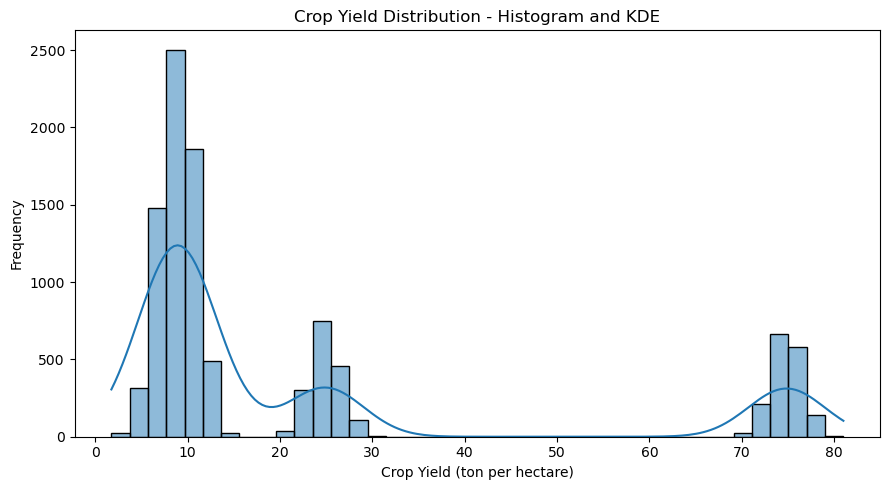

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Univariate\01_target_histogram_kde.png


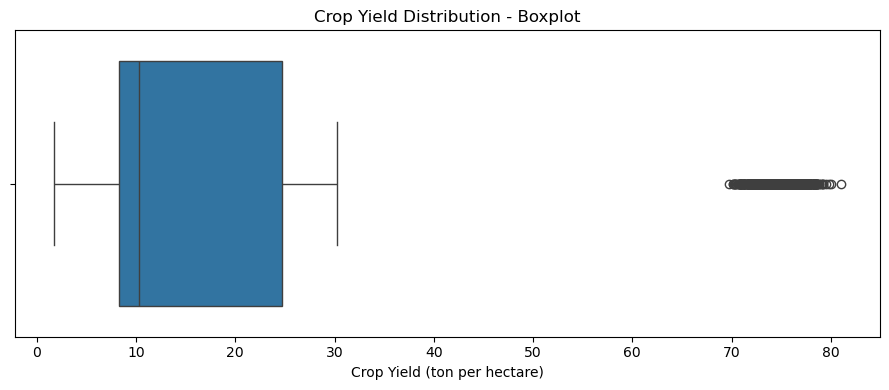

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Univariate\02_target_boxplot.png


In [23]:

# Step 6.1: Save target distribution charts individually
import matplotlib.pyplot as plt
TARGET = "Crop_Yield_ton_per_hectare"

# Graph 1: Histogram + KDE
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x=TARGET, bins=40, kde=True)

plt.title("Crop Yield Distribution - Histogram and KDE")
plt.xlabel("Crop Yield (ton per hectare)")
plt.ylabel("Frequency")
plt.tight_layout()

path = os.path.join(
    EDA_DIR, "Univariate", "01_target_histogram_kde.png"
)
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Saved:", path)

# Graph 2: Boxplot
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x=TARGET)

plt.title("Crop Yield Distribution - Boxplot")
plt.xlabel("Crop Yield (ton per hectare)")
plt.tight_layout()

path = os.path.join(
    EDA_DIR, "Univariate", "02_target_boxplot.png"
)
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Saved:", path)


In [24]:
# Step 6.2.1: Identify numerical predictor columns
numerical_features = df.select_dtypes(
    include=np.number
).columns.drop(TARGET).tolist()
print("Number of numerical input features:", len(numerical_features))
print("\nNumerical input features:")
for i, feature in enumerate(numerical_features, start=1):
    print(f"{i}. {feature}")

Number of numerical input features: 14

Numerical input features:
1. N
2. P
3. K
4. Soil_pH
5. Soil_Moisture
6. Organic_Carbon
7. Temperature
8. Humidity
9. Rainfall
10. Sunlight_Hours
11. Wind_Speed
12. Altitude
13. Fertilizer_Used
14. Pesticide_Used


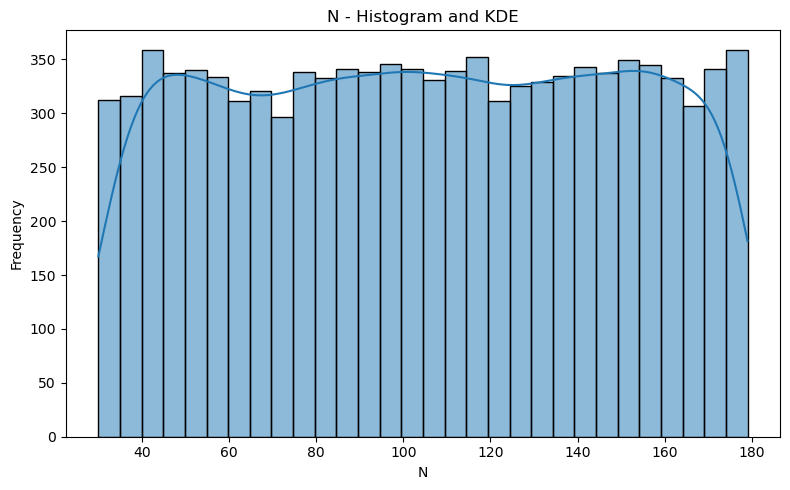

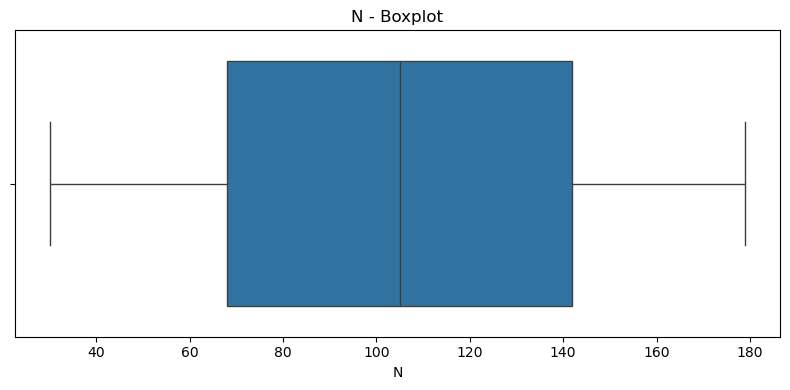

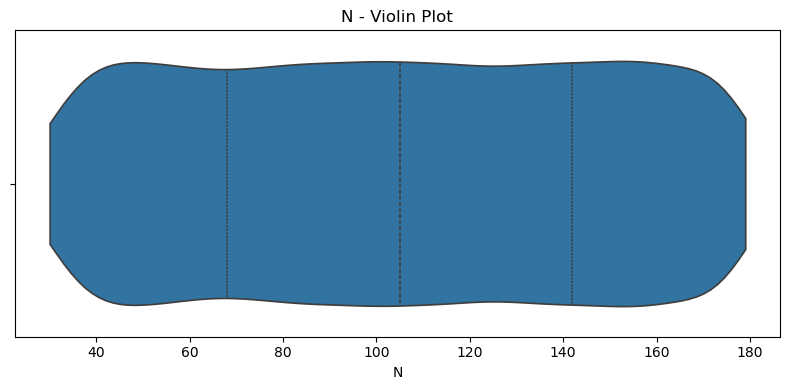

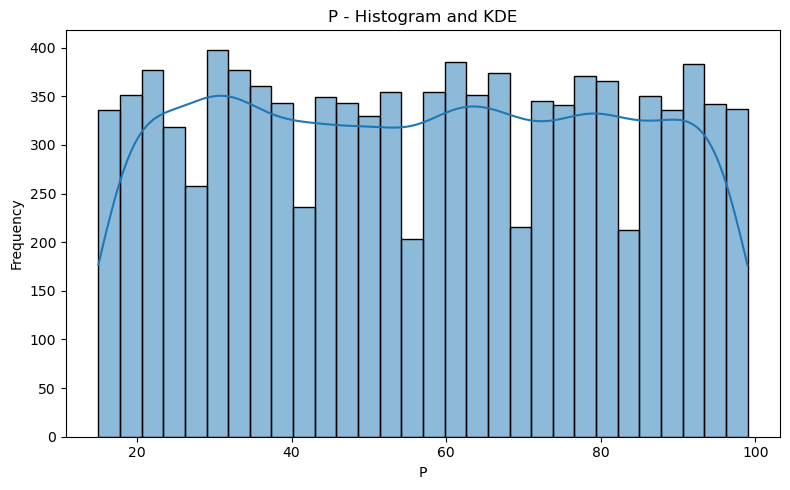

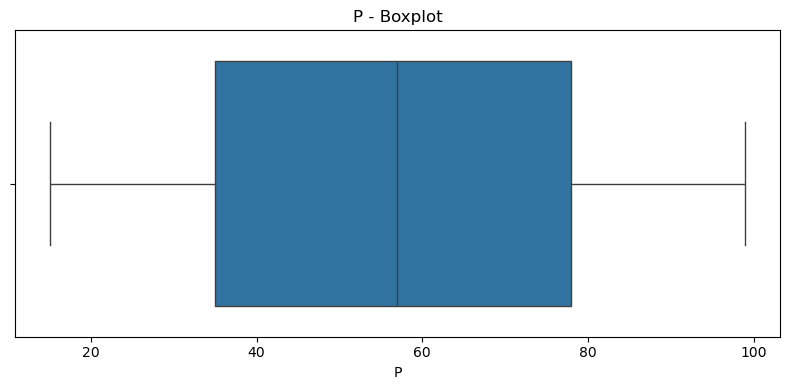

...

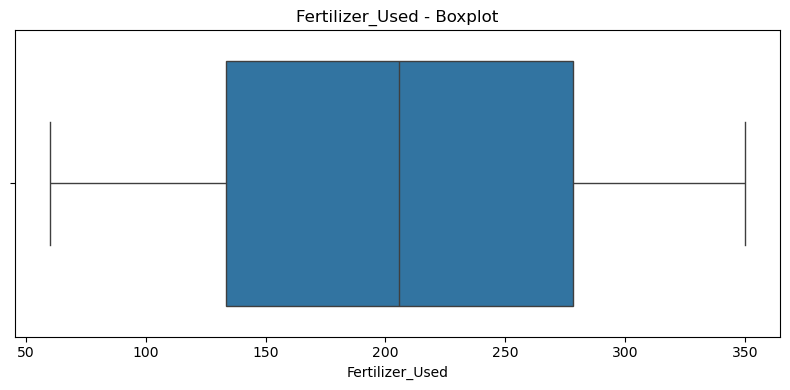

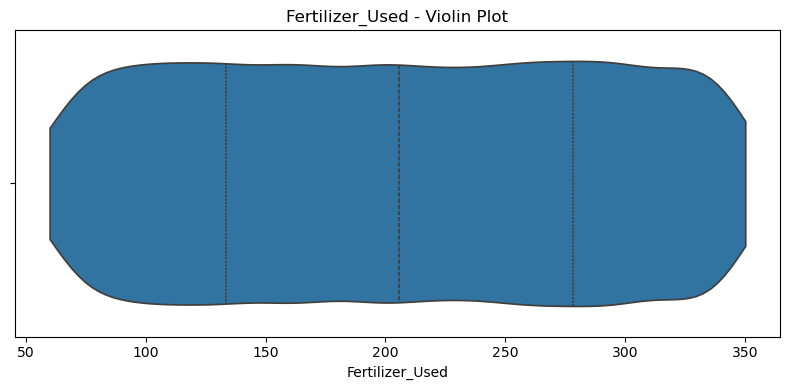

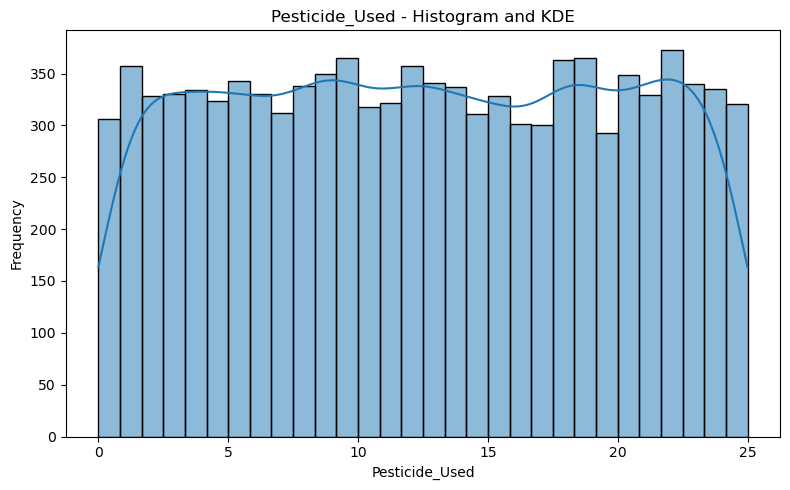

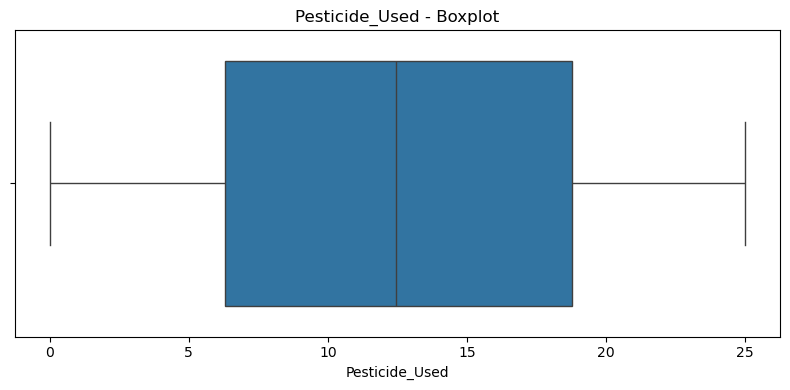

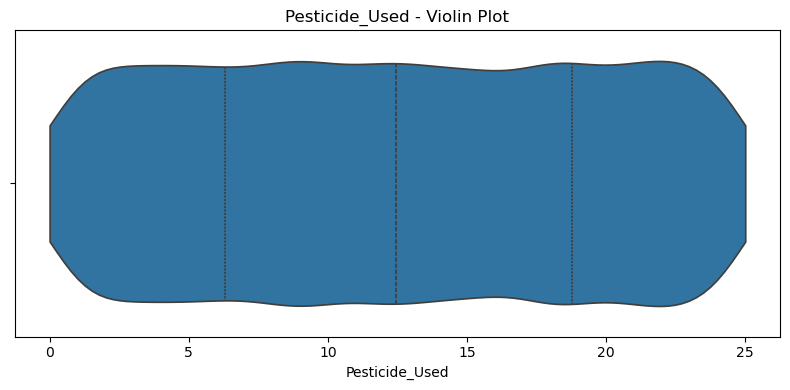

All numerical graphs saved individually!


In [25]:

# Step 6.2.2: Save every numerical graph separately

for feature in numerical_features:

    safe_name = feature.replace("/", "_").replace(" ", "_")

    # Graph 1: Histogram + KDE
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=feature, bins=30, kde=True)
    plt.title(f"{feature} - Histogram and KDE")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()

    path = os.path.join(
        EDA_DIR, "Univariate",
        f"numerical_{safe_name}_histogram_kde.png"
    )
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Graph 2: Boxplot
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x=feature)
    plt.title(f"{feature} - Boxplot")
    plt.xlabel(feature)
    plt.tight_layout()

    path = os.path.join(
        EDA_DIR, "Univariate",
        f"numerical_{safe_name}_boxplot.png"
    )
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Graph 3: Violin plot
    plt.figure(figsize=(8, 4))
    sns.violinplot(data=df, x=feature, inner="quartile", cut=0)
    plt.title(f"{feature} - Violin Plot")
    plt.xlabel(feature)
    plt.tight_layout()

    path = os.path.join(
        EDA_DIR, "Univariate",
        f"numerical_{safe_name}_violin.png"
    )
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

print("All numerical graphs saved individually!")


In [26]:
# Step 6.2.3: Numerical feature distribution diagnostics
diagnostics = []
for feature in numerical_features:
    series = df[feature].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    diagnostics.append({
        "Feature": feature,
        "Mean": series.mean(),
        "Median": series.median(),
        "Std_Dev": series.std(),
        "Skewness": series.skew(),
        "Kurtosis": series.kurt(),
        "IQR": iqr,
        "Potential_Outliers": (
            (series < lower_bound) | (series > upper_bound)
        ).sum()
    })
numerical_diagnostics = (
    pd.DataFrame(diagnostics)
    .set_index("Feature")
    .round(3)
)
display(numerical_diagnostics)
diagnostics_path = os.path.join(
    EDA_DIR,
    "Univariate",
    "numerical_feature_diagnostics.csv"
)
numerical_diagnostics.to_csv(diagnostics_path)
print("Diagnostics saved to:", diagnostics_path)

,Mean,Median,Std_Dev,Skewness,Kurtosis,IQR,Potential_Outliers
Feature,,,,,,,
N,104.983,105.00,43.292,-0.011,-1.199,74.000,0
P,56.810,57.00,24.523,0.010,-1.213,43.000,0
K,85.009,85.00,37.541,-0.015,-1.206,66.000,0
Soil_pH,6.504,6.52,0.979,-0.015,-1.194,1.680,0
Soil_Moisture,40.084,40.00,14.462,0.006,-1.200,25.133,0
Organic_Carbon,0.958,0.96,0.375,-0.038,-1.203,0.660,0
Temperature,25.097,24.97,8.719,0.003,-1.214,15.240,0
Humidity,59.894,59.55,17.402,0.018,-1.206,30.207,0
Rainfall,1546.695,1548.55,718.866,0.009,-1.196,1239.685,0


Diagnostics saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Univariate\numerical_feature_diagnostics.csv


In [27]:
# Step 6.3.1: Identify categorical features
categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()
print("Number of categorical features:", len(categorical_features))
print("\nCategorical features:")
for i, feature in enumerate(categorical_features, start=1):
    print(f"{i}. {feature}")

Number of categorical features: 5

Categorical features:
1. Soil_Type
2. Region
3. Season
4. Crop_Type
5. Irrigation_Type


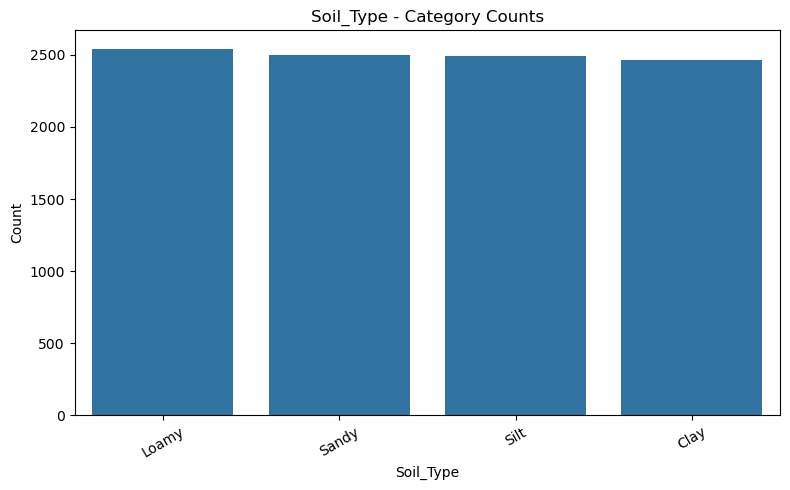

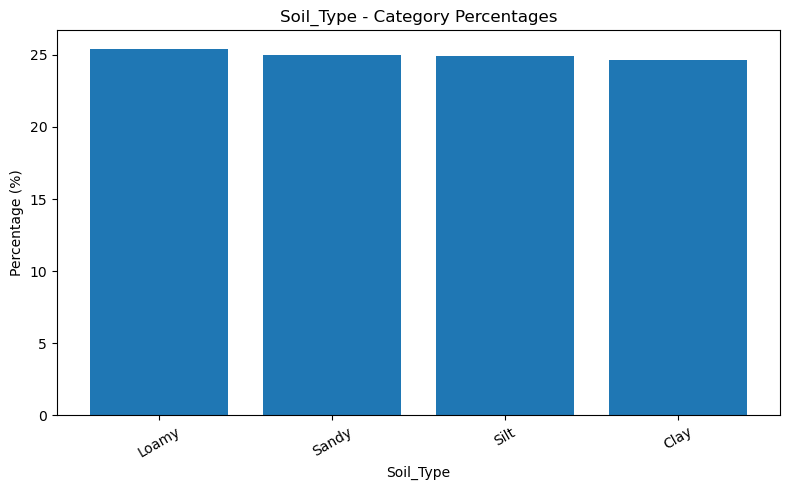

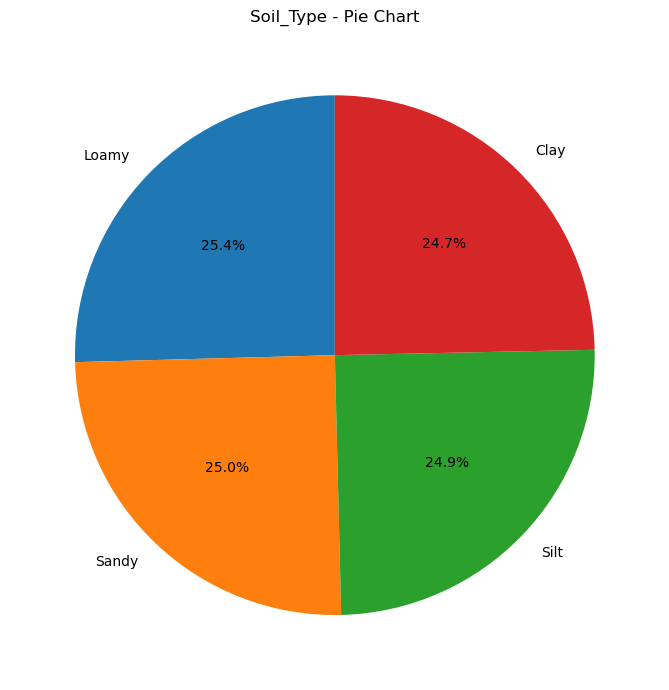

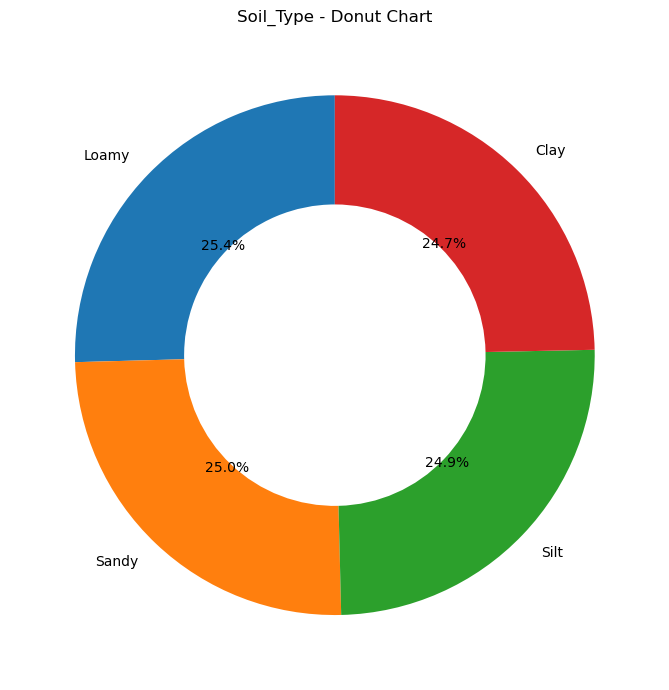

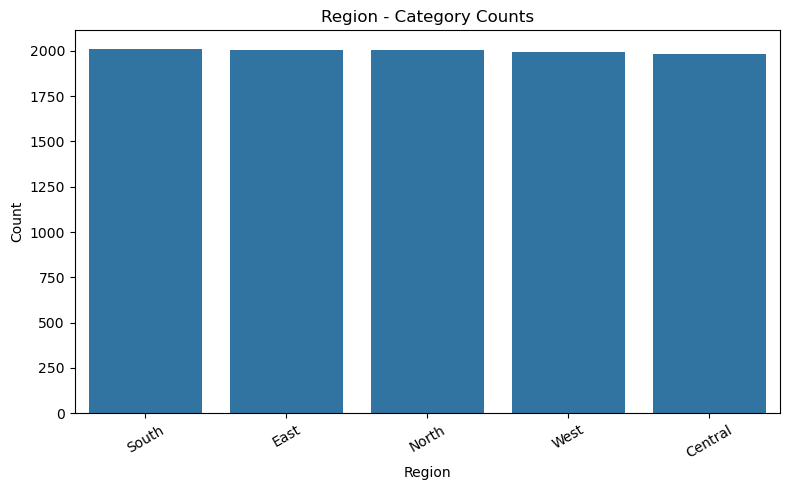

...

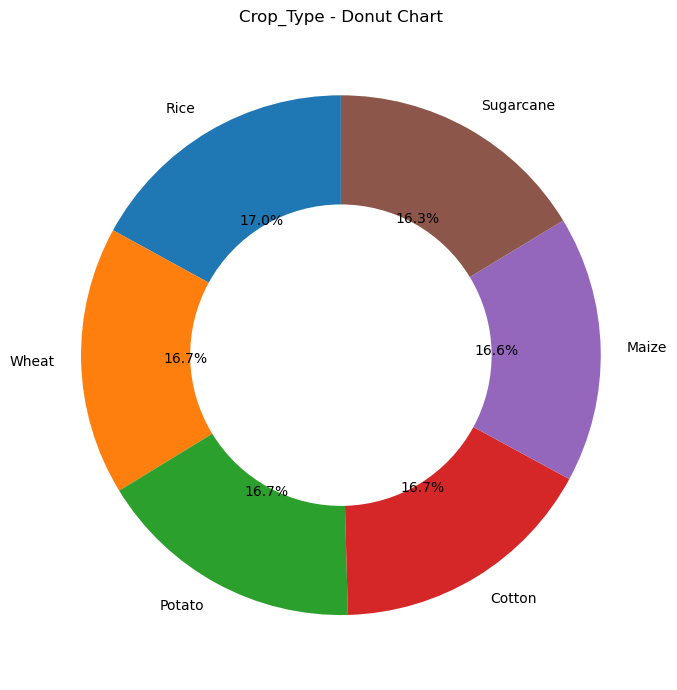

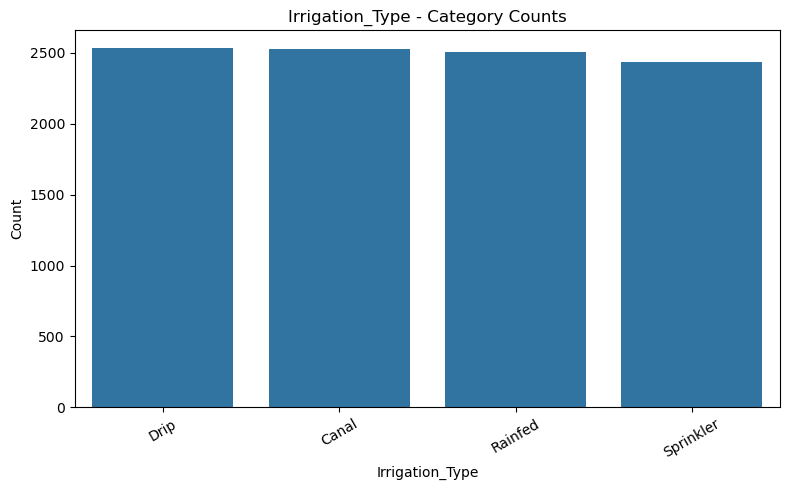

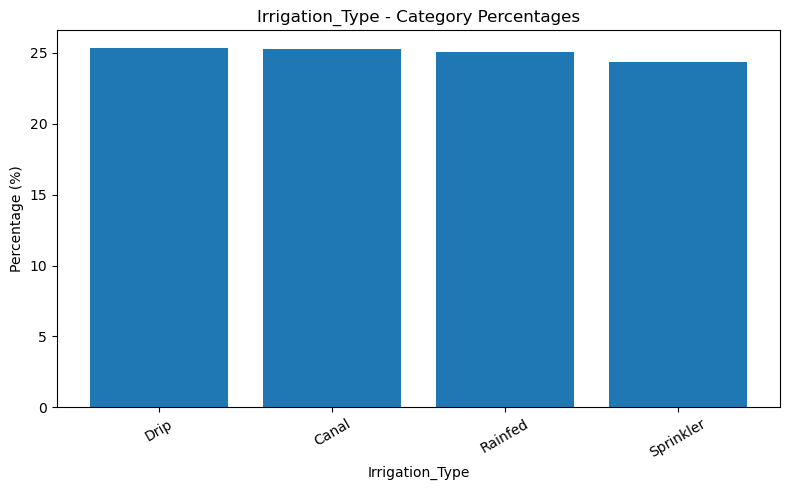

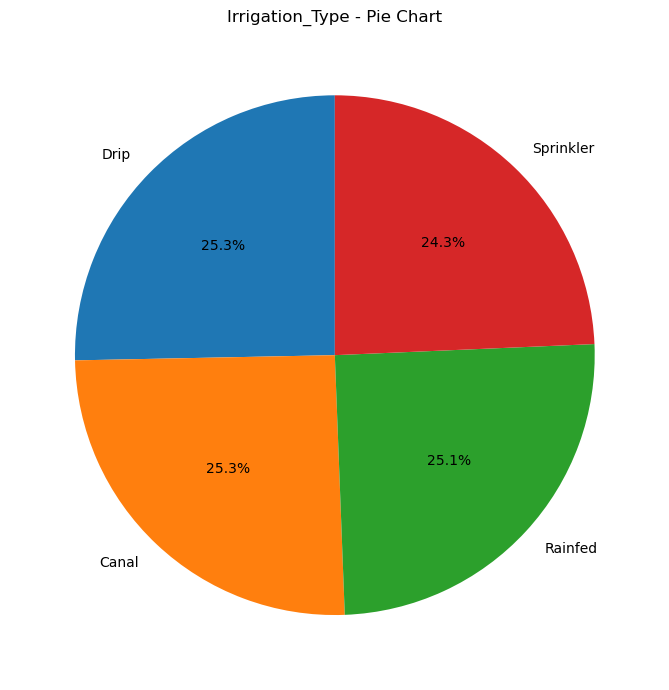

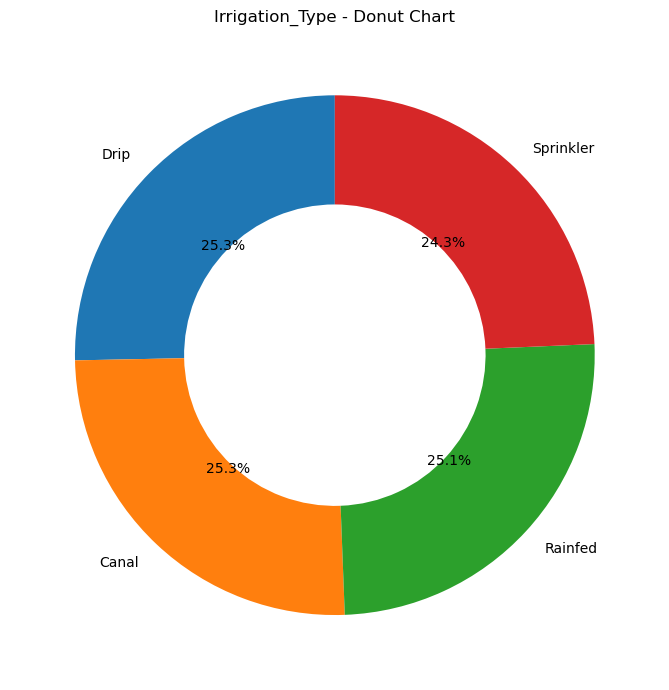

All categorical graphs saved individually!


In [28]:

# Step 6.3.2: Save every categorical graph separately

for feature in categorical_features:

    counts = df[feature].value_counts(dropna=False)
    percentages = counts / counts.sum() * 100
    safe_name = feature.replace("/", "_").replace(" ", "_")

    # Graph 1: Count plot
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=feature, order=counts.index)
    plt.title(f"{feature} - Category Counts")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.xticks(rotation=30)
    plt.tight_layout()

    path = os.path.join(
        EDA_DIR, "Univariate",
        f"categorical_{safe_name}_countplot.png"
    )
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Graph 2: Percentage bar chart
    plt.figure(figsize=(8, 5))
    plt.bar(percentages.index.astype(str), percentages.values)
    plt.title(f"{feature} - Category Percentages")
    plt.xlabel(feature)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)
    plt.tight_layout()

    path = os.path.join(
        EDA_DIR, "Univariate",
        f"categorical_{safe_name}_percentage_bar.png"
    )
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Graph 3: Pie chart
    plt.figure(figsize=(7, 7))
    plt.pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title(f"{feature} - Pie Chart")
    plt.tight_layout()

    path = os.path.join(
        EDA_DIR, "Univariate",
        f"categorical_{safe_name}_pie.png"
    )
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Graph 4: Donut chart
    plt.figure(figsize=(7, 7))
    plt.pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops={"width": 0.42}
    )
    plt.title(f"{feature} - Donut Chart")
    plt.tight_layout()

    path = os.path.join(
        EDA_DIR, "Univariate",
        f"categorical_{safe_name}_donut.png"
    )
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

print("All categorical graphs saved individually!")


In [29]:
# Step 6.3.3: Categorical frequency and proportion report
frequency_tables = []
for feature in categorical_features:
    counts = df[feature].value_counts(dropna=False)
    percentages = (
        df[feature]
        .value_counts(normalize=True, dropna=False) * 100
    )
    for category, count in counts.items():
        frequency_tables.append({
            "Feature": feature,
            "Category": str(category),
            "Count": int(count),
            "Percentage": round(percentages.loc[category], 2)
        })
categorical_frequency_report = pd.DataFrame(frequency_tables)
display(categorical_frequency_report)
frequency_path = os.path.join(
    EDA_DIR,
    "Univariate",
    "categorical_frequency_report.csv"
)
categorical_frequency_report.to_csv(frequency_path, index=False)
print("Report saved to:", frequency_path)

,Feature,Category,Count,Percentage
0,Soil_Type,Loamy,2543,25.43
1,Soil_Type,Sandy,2496,24.96
2,Soil_Type,Silt,2494,24.94
3,Soil_Type,Clay,2467,24.67
4,Region,South,2013,20.13
5,Region,East,2006,20.06
6,Region,North,2003,20.03
7,Region,West,1996,19.96
8,Region,Central,1982,19.82
9,Season,Rabi,3355,33.55


Report saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Univariate\categorical_frequency_report.csv


In [30]:
# Step 6.3.4: Check category labels and whitespace
for feature in categorical_features:
    print(f"\n{feature}")
    print("Unique values:", df[feature].nunique())
    print("Labels:")
    for value in sorted(df[feature].dropna().unique(), key=str):
        print(repr(value))
    whitespace_count = (
        df[feature]
        .astype("string")
        .str.strip()
        .ne(df[feature].astype("string"))
        .sum()
    )
    print("Values with leading/trailing whitespace:", whitespace_count)


Soil_Type
Unique values: 4
Labels:
'Clay'
'Loamy'
'Sandy'
'Silt'
Values with leading/trailing whitespace: 0

Region
Unique values: 5
Labels:
'Central'
'East'
'North'
'South'
'West'
Values with leading/trailing whitespace: 0

Season
Unique values: 3
Labels:
'Kharif'
'Rabi'
'Zaid'
Values with leading/trailing whitespace: 0

Crop_Type
Unique values: 6
Labels:
'Cotton'
'Maize'
'Potato'
'Rice'
'Sugarcane'
'Wheat'
Values with leading/trailing whitespace: 0

Irrigation_Type
Unique values: 4
Labels:
'Canal'
'Drip'
'Rainfed'
'Sprinkler'
Values with leading/trailing whitespace: 0


Numerical predictors: 14
Features: ['N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Temperature', 'Humidity', 'Rainfall', 'Sunlight_Hours', 'Wind_Speed', 'Altitude', 'Fertilizer_Used', 'Pesticide_Used']


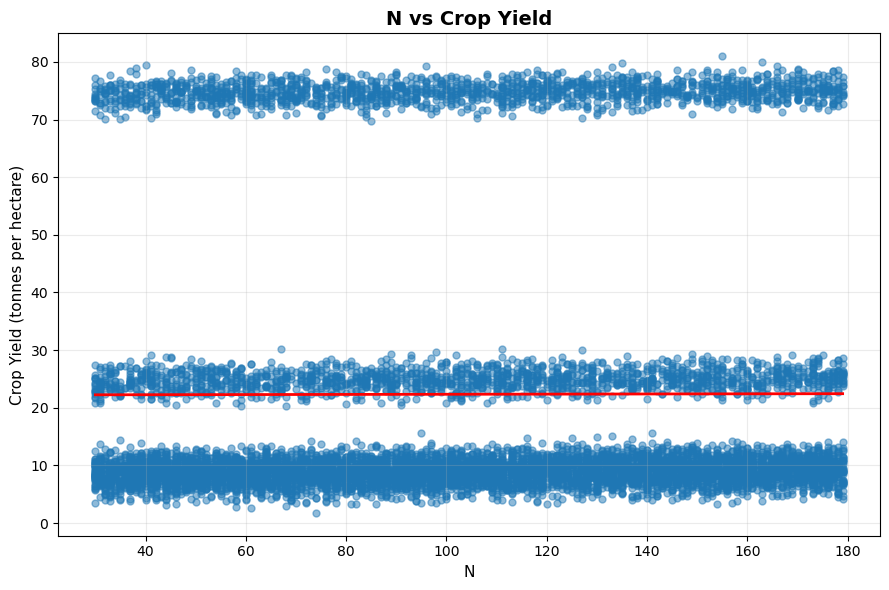

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_N_vs_crop_yield.png


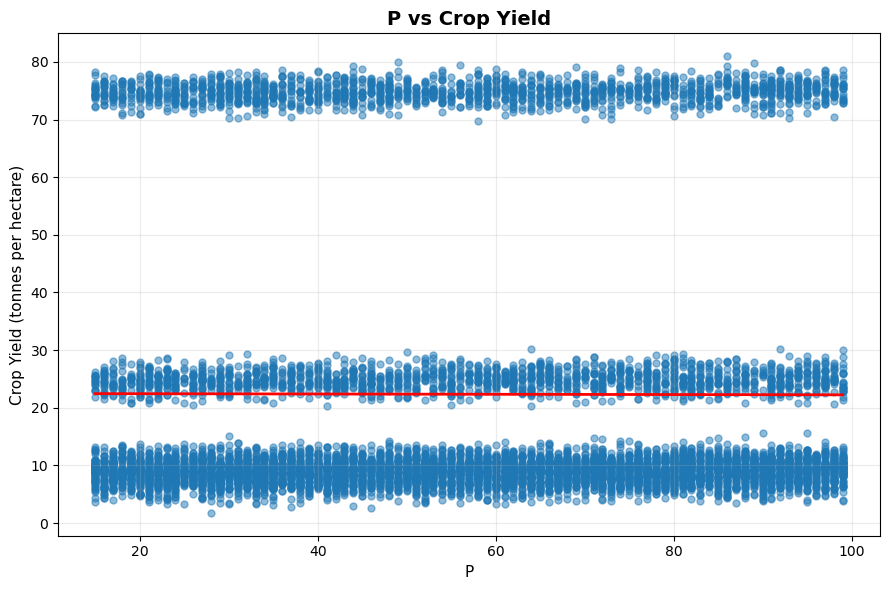

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_P_vs_crop_yield.png


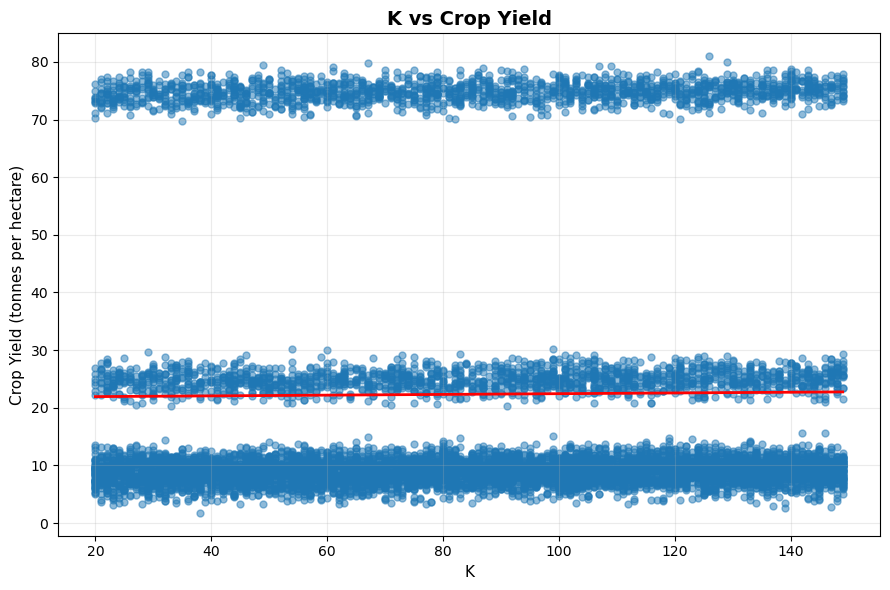

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_K_vs_crop_yield.png


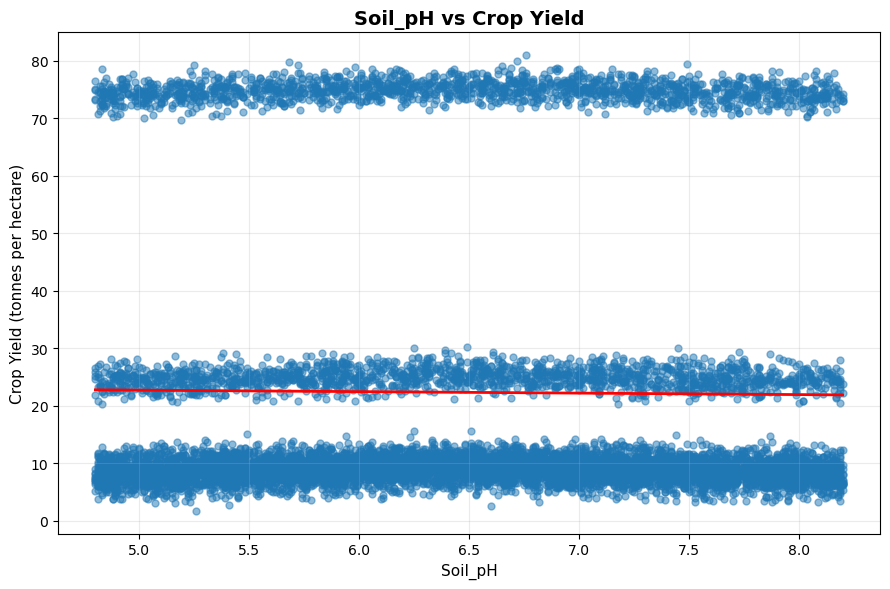

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Soil_pH_vs_crop_yield.png


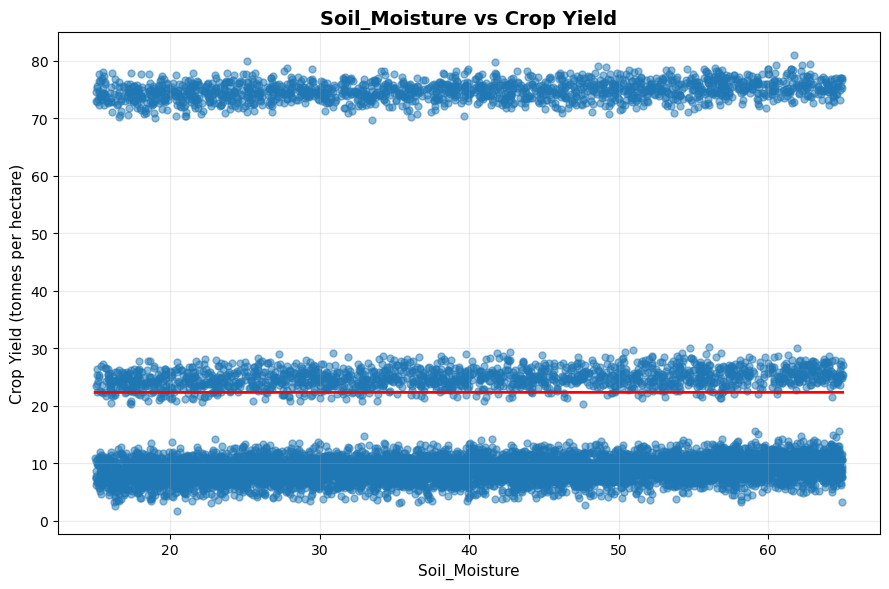

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Soil_Moisture_vs_crop_yield.png


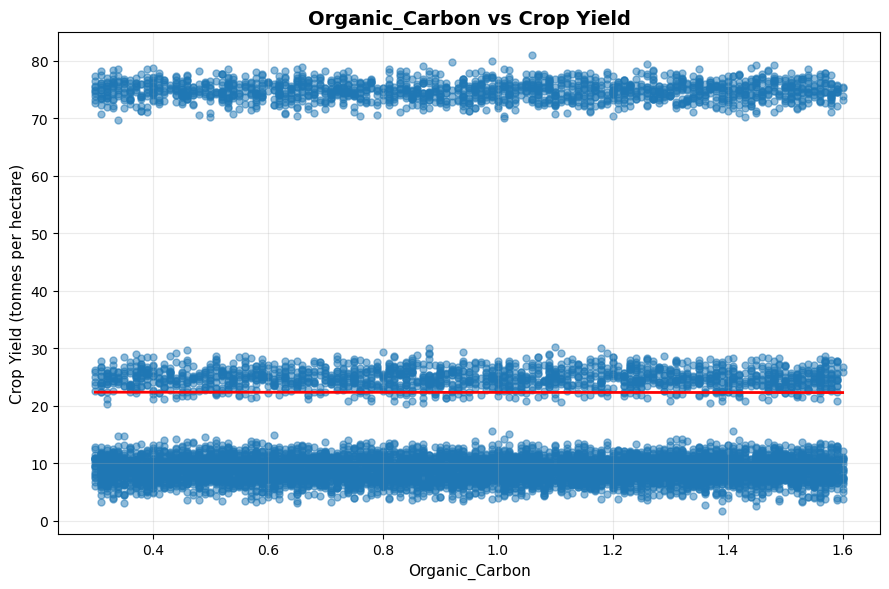

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Organic_Carbon_vs_crop_yield.png


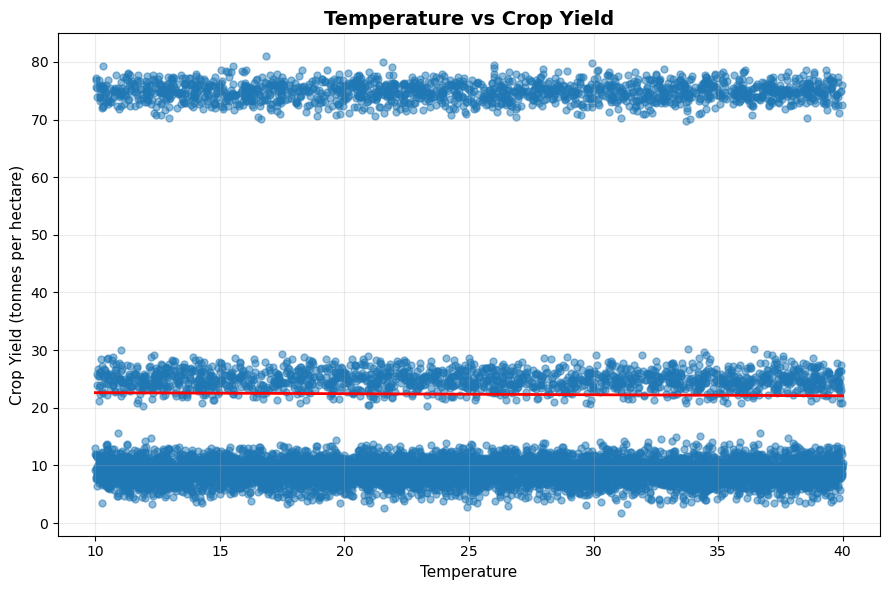

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Temperature_vs_crop_yield.png


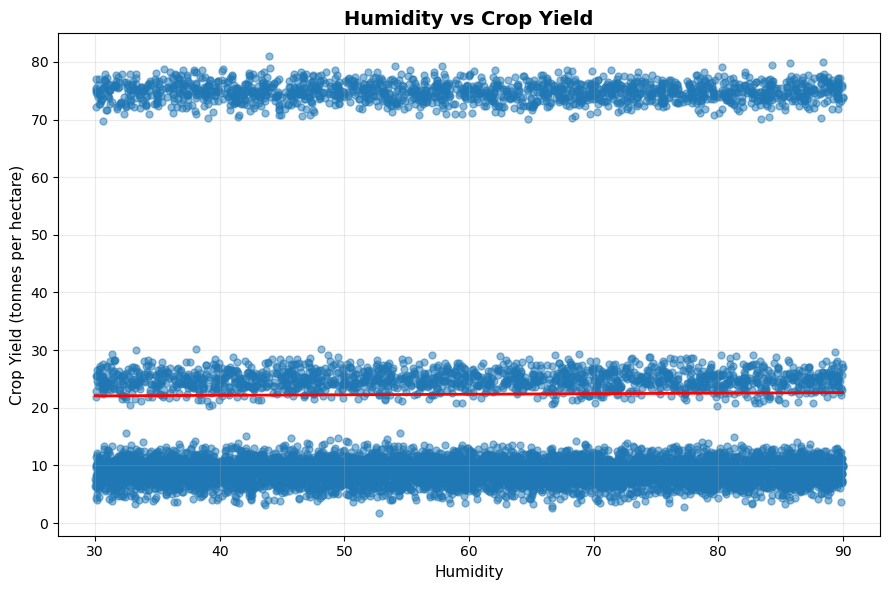

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Humidity_vs_crop_yield.png


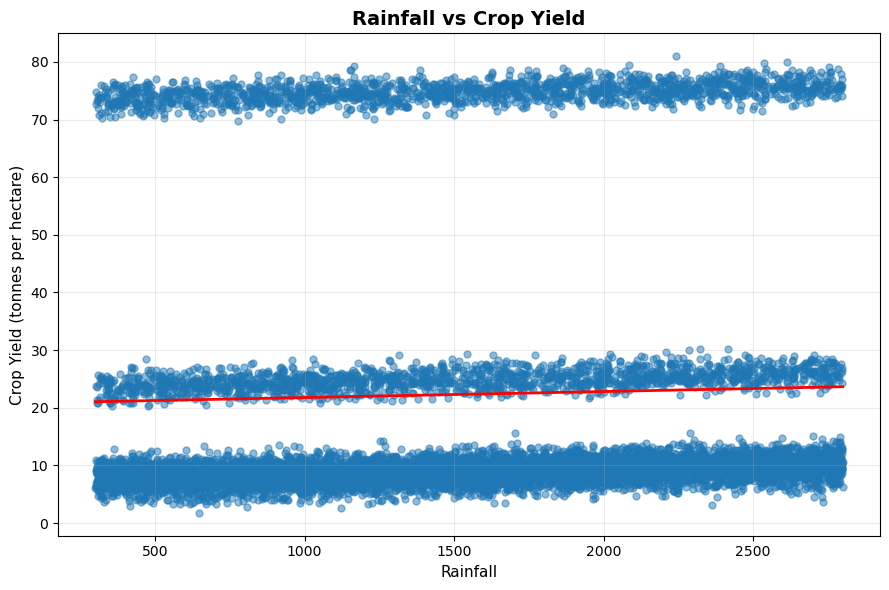

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Rainfall_vs_crop_yield.png


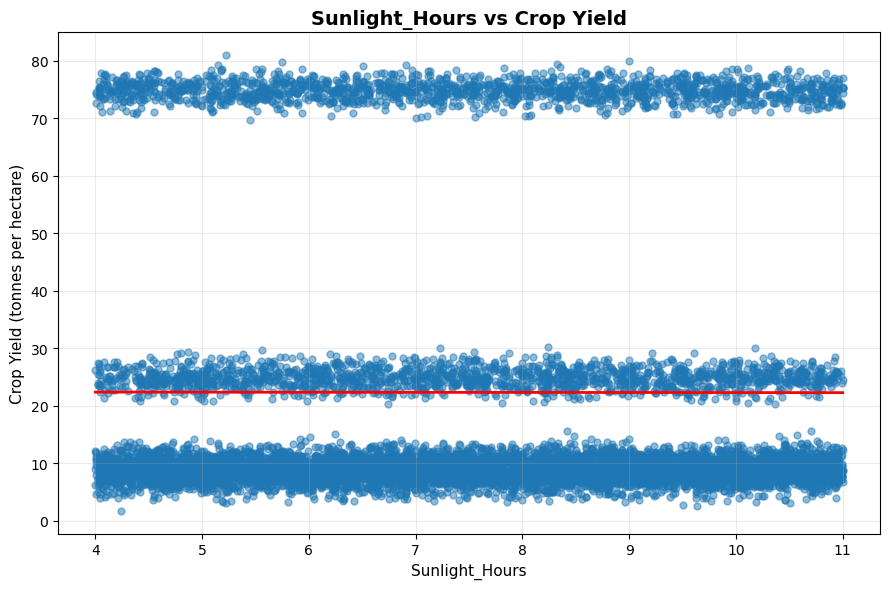

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Sunlight_Hours_vs_crop_yield.png


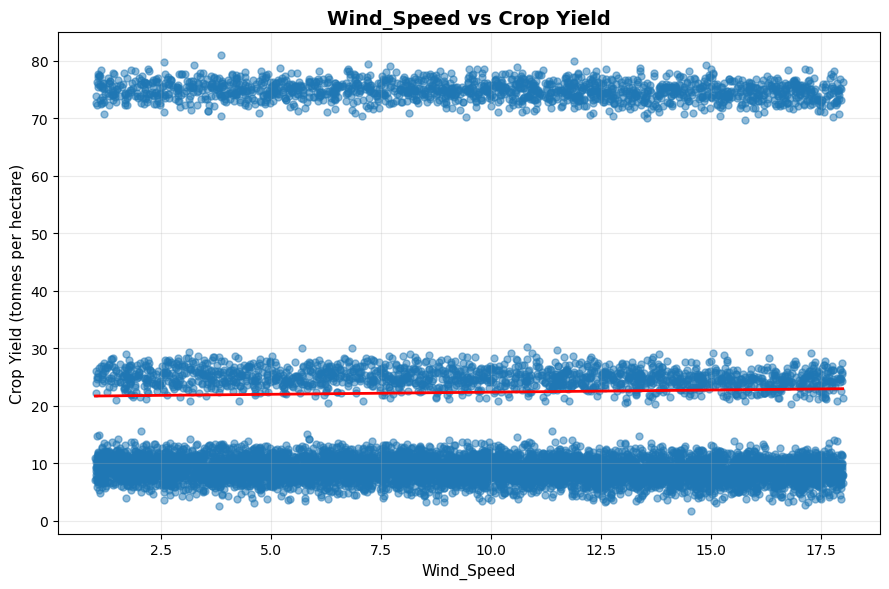

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Wind_Speed_vs_crop_yield.png


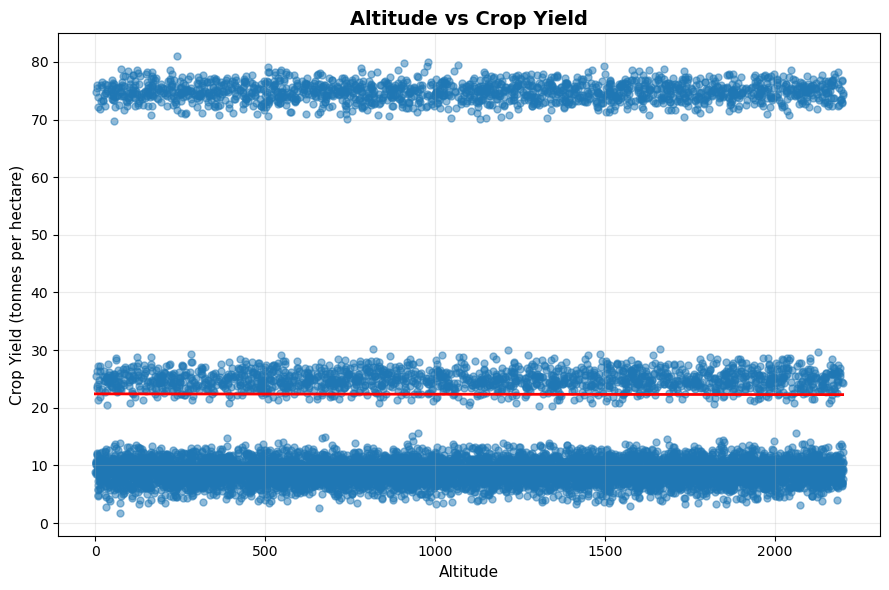

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Altitude_vs_crop_yield.png


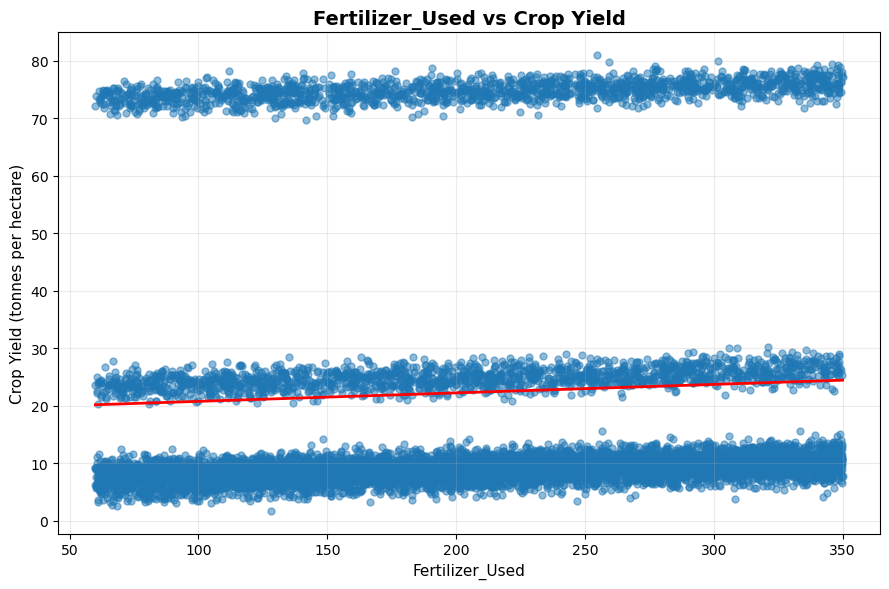

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Fertilizer_Used_vs_crop_yield.png


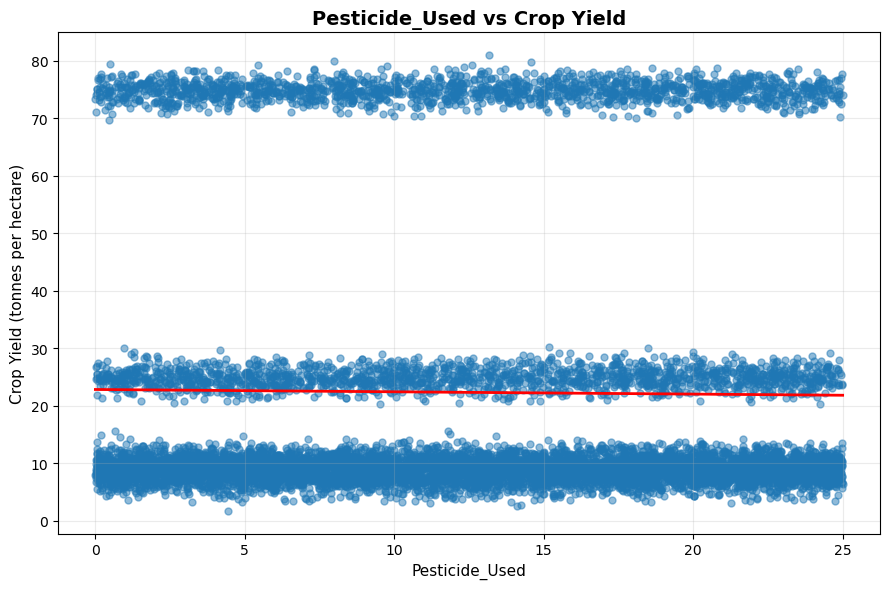

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\numerical_Pesticide_Used_vs_crop_yield.png

Step 6.4.1 completed!
All numerical bivariate graphs are saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate


In [31]:

# ============================================================
# STEP 6.4.1: BIVARIATE EDA — NUMERICAL FEATURES VS CROP YIELD
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create Bivariate directory inside the project-level EDA_Graphs
BIVARIATE_DIR = os.path.join(EDA_DIR, "Bivariate")
os.makedirs(BIVARIATE_DIR, exist_ok=True)

# Target variable
target = "Crop_Yield_ton_per_hectare"

# Identify all numerical predictors, excluding the target
numerical_features = [
    col for col in df.select_dtypes(include="number").columns
    if col != target
]

print("Numerical predictors:", len(numerical_features))
print("Features:", numerical_features)

# Generate, display, and save every graph individually
for feature in numerical_features:

    plot_data = df[[feature, target]].dropna()

    if plot_data.empty:
        print(f"Skipped {feature}: no valid data available.")
        continue

    plt.figure(figsize=(9, 6))

    sns.regplot(
        data=plot_data,
        x=feature,
        y=target,
        scatter_kws={"alpha": 0.5, "s": 25},
        line_kws={"color": "red", "linewidth": 2},
        ci=None
    )

    plt.title(
        f"{feature} vs Crop Yield",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel(feature, fontsize=11)
    plt.ylabel("Crop Yield (tonnes per hectare)", fontsize=11)
    plt.grid(alpha=0.25)
    plt.tight_layout()

    # Make the filename safe
    safe_name = (
        feature.replace("/", "_")
        .replace(" ", "_")
        .replace("\\", "_")
    )

    path = os.path.join(
        BIVARIATE_DIR,
        f"numerical_{safe_name}_vs_crop_yield.png"
    )

    # Save and display the individual graph
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", path)

print("\nStep 6.4.1 completed!")
print("All numerical bivariate graphs are saved in:", BIVARIATE_DIR)


Categorical predictors: 5
Features: ['Soil_Type', 'Region', 'Season', 'Crop_Type', 'Irrigation_Type']


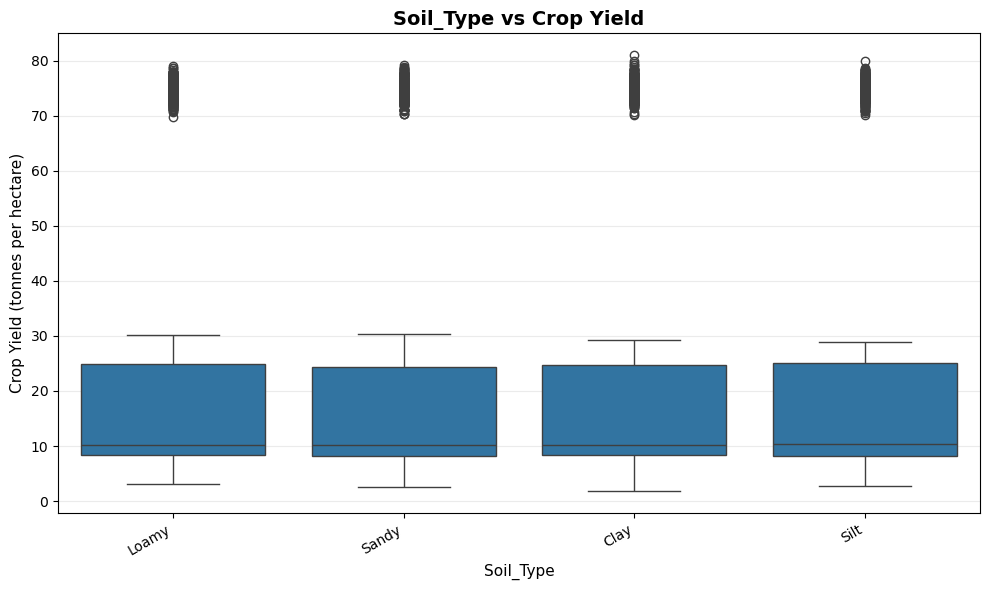

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\categorical_Soil_Type_vs_crop_yield_boxplot.png


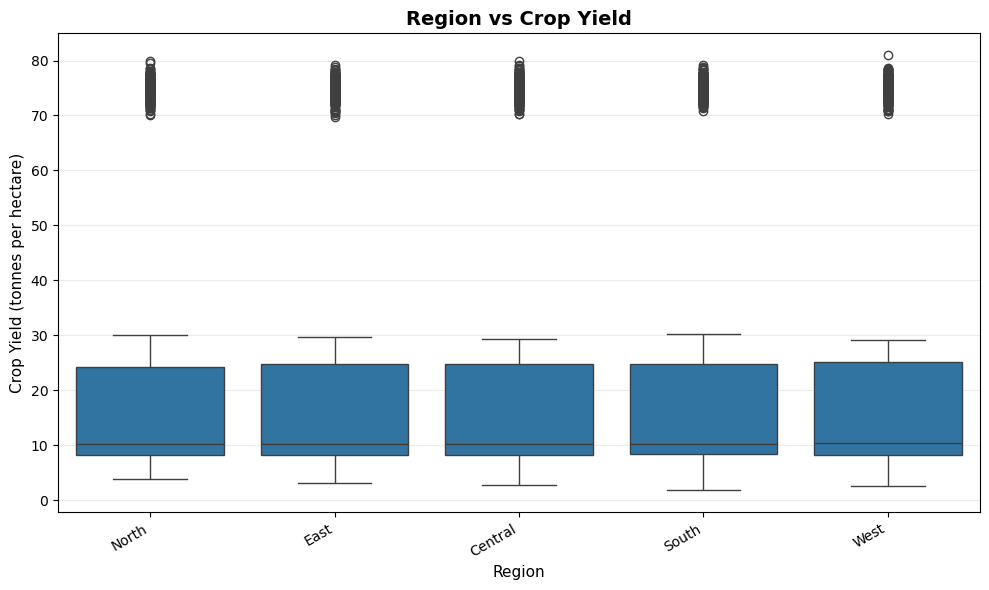

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\categorical_Region_vs_crop_yield_boxplot.png


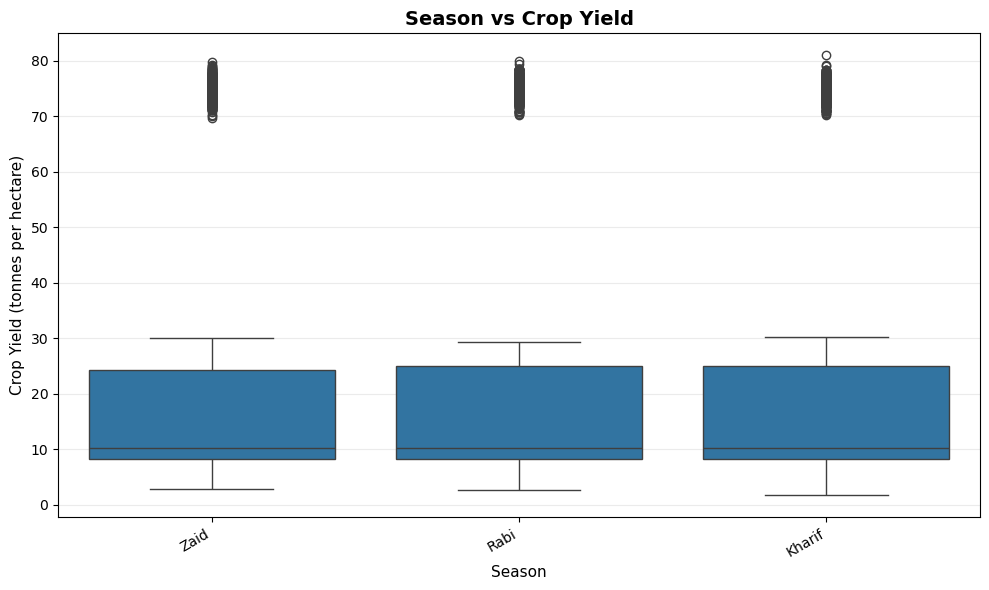

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\categorical_Season_vs_crop_yield_boxplot.png


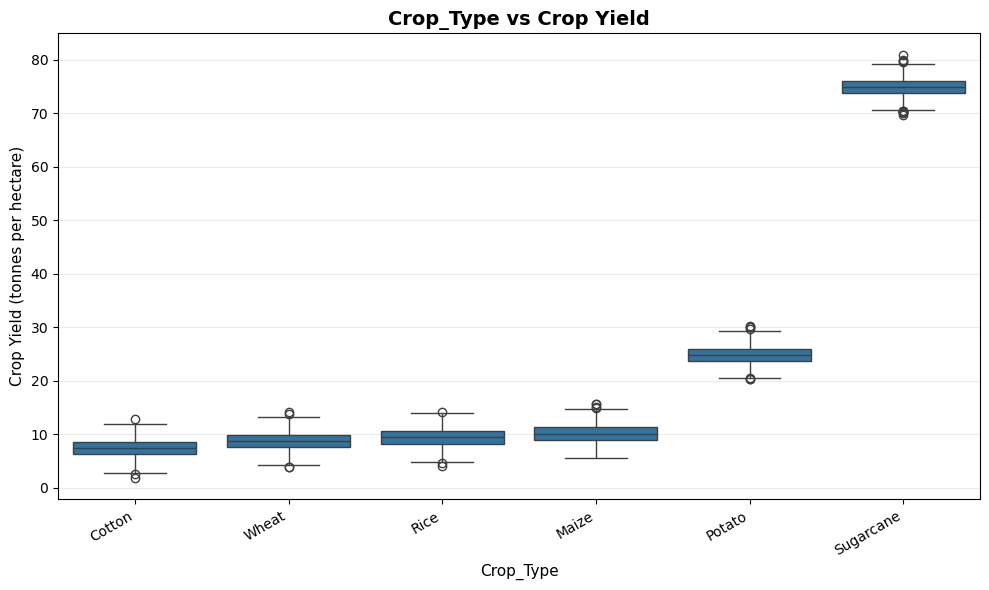

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\categorical_Crop_Type_vs_crop_yield_boxplot.png


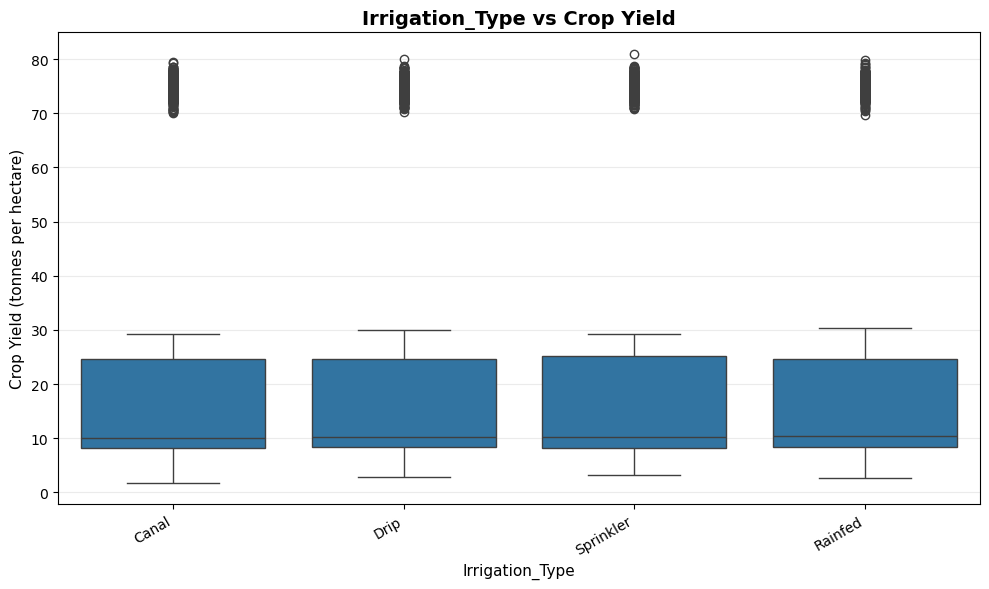

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate\categorical_Irrigation_Type_vs_crop_yield_boxplot.png

Step 6.4.2 completed!
All categorical bivariate graphs are saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Bivariate


In [32]:

# ============================================================
# STEP 6.4.2: BIVARIATE EDA — CATEGORICAL FEATURES VS CROP YIELD
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Use the same project-level EDA_Graphs directory
BIVARIATE_DIR = os.path.join(EDA_DIR, "Bivariate")
os.makedirs(BIVARIATE_DIR, exist_ok=True)

# Target variable
target = "Crop_Yield_ton_per_hectare"

print("Categorical predictors:", len(categorical_features))
print("Features:", categorical_features)

# Generate, display, and save every graph individually
for feature in categorical_features:

    plot_data = df[[feature, target]].dropna()

    if plot_data.empty:
        print(f"Skipped {feature}: no valid data available.")
        continue

    # Sort categories by median yield for easier comparison
    category_order = (
        plot_data.groupby(feature, observed=True)[target]
        .median()
        .sort_values()
        .index.tolist()
    )

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=plot_data,
        x=feature,
        y=target,
        order=category_order
    )

    plt.title(
        f"{feature} vs Crop Yield",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel(feature, fontsize=11)
    plt.ylabel("Crop Yield (tonnes per hectare)", fontsize=11)
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()

    # Make the filename safe
    safe_name = (
        feature.replace("/", "_")
        .replace(" ", "_")
        .replace("\\", "_")
    )

    path = os.path.join(
        BIVARIATE_DIR,
        f"categorical_{safe_name}_vs_crop_yield_boxplot.png"
    )

    # Save and display the individual graph
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", path)

print("\nStep 6.4.2 completed!")
print("All categorical bivariate graphs are saved in:", BIVARIATE_DIR)


Correlation Matrix:


,N,P,K,Soil_pH,Soil_Moisture,Organic_Carbon,Temperature,Humidity,Rainfall,Sunlight_Hours,Wind_Speed,Altitude,Fertilizer_Used,Pesticide_Used,Crop_Yield_ton_per_hectare
N,1.000,0.006,-0.006,0.008,0.012,0.011,0.002,0.007,0.008,-0.007,0.005,0.004,0.010,-0.001,0.002
P,0.006,1.000,-0.004,-0.005,-0.015,0.011,-0.001,0.006,-0.000,0.027,0.009,0.010,0.005,-0.009,-0.002
K,-0.006,-0.004,1.000,-0.002,0.010,-0.009,0.012,0.011,-0.006,-0.000,0.004,-0.004,0.008,-0.003,0.010
Soil_pH,0.008,-0.005,-0.002,1.000,-0.005,0.006,-0.000,0.000,0.001,-0.002,-0.000,-0.001,0.000,0.011,-0.011
Soil_Moisture,0.012,-0.015,0.010,-0.005,1.000,0.001,-0.006,-0.013,-0.007,-0.008,0.001,0.009,-0.008,0.008,0.000
Organic_Carbon,0.011,0.011,-0.009,0.006,0.001,1.000,-0.022,0.001,-0.010,-0.003,0.013,0.022,-0.001,-0.001,-0.001
Temperature,0.002,-0.001,0.012,-0.000,-0.006,-0.022,1.000,-0.009,-0.006,0.001,-0.010,0.003,-0.012,0.010,-0.007
Humidity,0.007,0.006,0.011,0.000,-0.013,0.001,-0.009,1.000,0.013,0.021,-0.003,-0.003,-0.010,-0.002,0.007
Rainfall,0.008,-0.000,-0.006,0.001,-0.007,-0.010,-0.006,0.013,1.000,-0.001,-0.014,-0.001,0.019,-0.007,0.031
Sunlight_Hours,-0.007,0.027,-0.000,-0.002,-0.008,-0.003,0.001,0.021,-0.001,1.000,-0.003,0.017,-0.009,-0.002,-0.001


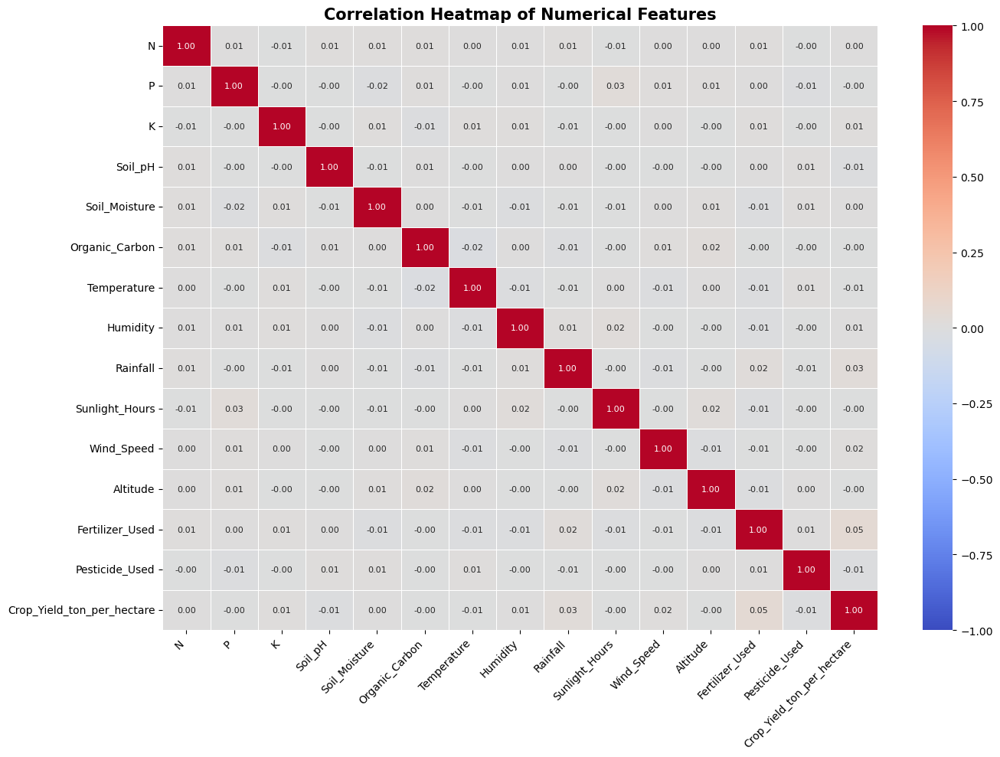

Heatmap saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Correlation\numerical_correlation_heatmap.png

Step 6.5.1 completed!


In [33]:

# ============================================================
# STEP 6.5.1: CORRELATION MATRIX AND HEATMAP
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Use the existing project-level EDA_Graphs directory
CORRELATION_DIR = os.path.join(EDA_DIR, "Correlation")
os.makedirs(CORRELATION_DIR, exist_ok=True)

target = "Crop_Yield_ton_per_hectare"

# Select numerical columns only
numerical_df = df.select_dtypes(include="number")

# Calculate the Pearson correlation matrix
correlation_matrix = numerical_df.corr(method="pearson")

# Display the complete correlation matrix
print("Correlation Matrix:")
display(correlation_matrix.round(3))

# Plot the correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title(
    "Correlation Heatmap of Numerical Features",
    fontsize=15,
    fontweight="bold"
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save and display the heatmap
heatmap_path = os.path.join(
    CORRELATION_DIR,
    "numerical_correlation_heatmap.png"
)

plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Heatmap saved:", heatmap_path)

print("\nStep 6.5.1 completed!")


Numerical Feature Correlation with Crop Yield:


,Feature,Correlation_with_Crop_Yield,Absolute_Correlation
0,Fertilizer_Used,0.0514,0.0514
1,Rainfall,0.0312,0.0312
2,Wind_Speed,0.0152,0.0152
3,Pesticide_Used,-0.0121,0.0121
4,Soil_pH,-0.0105,0.0105
5,K,0.0099,0.0099
6,Humidity,0.0069,0.0069
7,Temperature,-0.0066,0.0066
8,P,-0.0025,0.0025
9,N,0.0023,0.0023


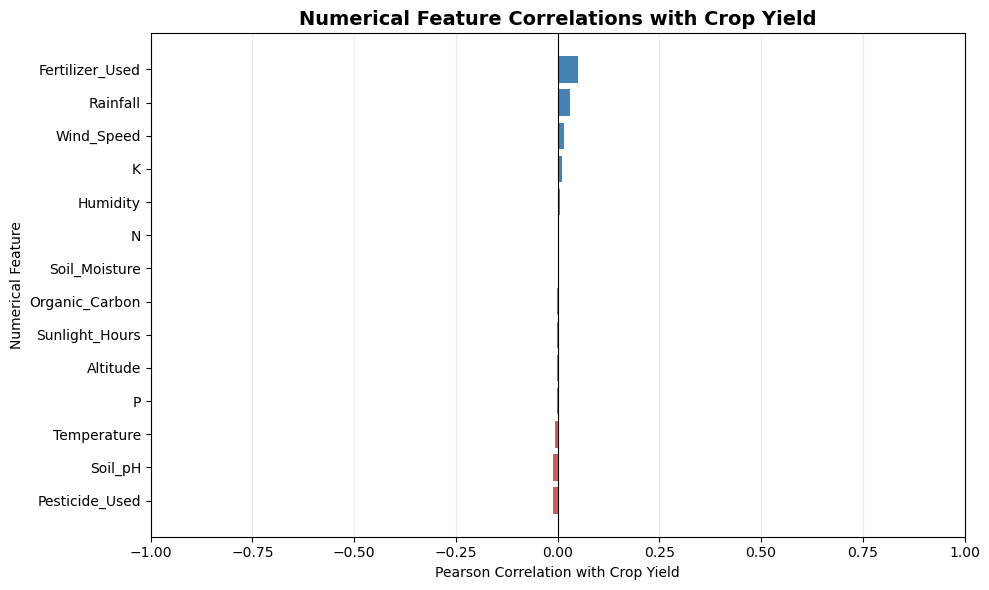

Correlation plot saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Correlation\feature_correlation_with_crop_yield.png
Correlation report saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Correlation\feature_correlation_with_crop_yield.csv

Step 6.5.2 completed!


In [34]:

# ============================================================
# STEP 6.5.2: FEATURE CORRELATION WITH CROP YIELD
# ============================================================

# Extract correlations with the target
target_correlations = (
    correlation_matrix[target]
    .drop(labels=[target])
    .dropna()
    .sort_values()
)

# Display the correlation ranking
correlation_report = pd.DataFrame({
    "Feature": target_correlations.index,
    "Correlation_with_Crop_Yield": target_correlations.values,
    "Absolute_Correlation": target_correlations.abs().values
})

correlation_report = correlation_report.sort_values(
    "Absolute_Correlation",
    ascending=False
).reset_index(drop=True)

print("Numerical Feature Correlation with Crop Yield:")
display(correlation_report.round(4))

# Plot signed correlations, ordered from negative to positive
plt.figure(figsize=(10, max(6, len(target_correlations) * 0.4)))

bar_colors = [
    "steelblue" if value >= 0 else "indianred"
    for value in target_correlations.values
]

plt.barh(
    target_correlations.index,
    target_correlations.values,
    color=bar_colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Pearson Correlation with Crop Yield")
plt.ylabel("Numerical Feature")
plt.title(
    "Numerical Feature Correlations with Crop Yield",
    fontsize=14,
    fontweight="bold"
)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

# Save and display the individual graph
correlation_plot_path = os.path.join(
    CORRELATION_DIR,
    "feature_correlation_with_crop_yield.png"
)

plt.savefig(correlation_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Save the correlation report as a CSV table
report_path = os.path.join(
    CORRELATION_DIR,
    "feature_correlation_with_crop_yield.csv"
)

correlation_report.to_csv(report_path, index=False)

print("Correlation plot saved:", correlation_plot_path)
print("Correlation report saved:", report_path)

print("\nStep 6.5.2 completed!")


Selected numerical features: ['Fertilizer_Used', 'Rainfall', 'Wind_Speed', 'Pesticide_Used', 'Soil_pH', 'Crop_Yield_ton_per_hectare']


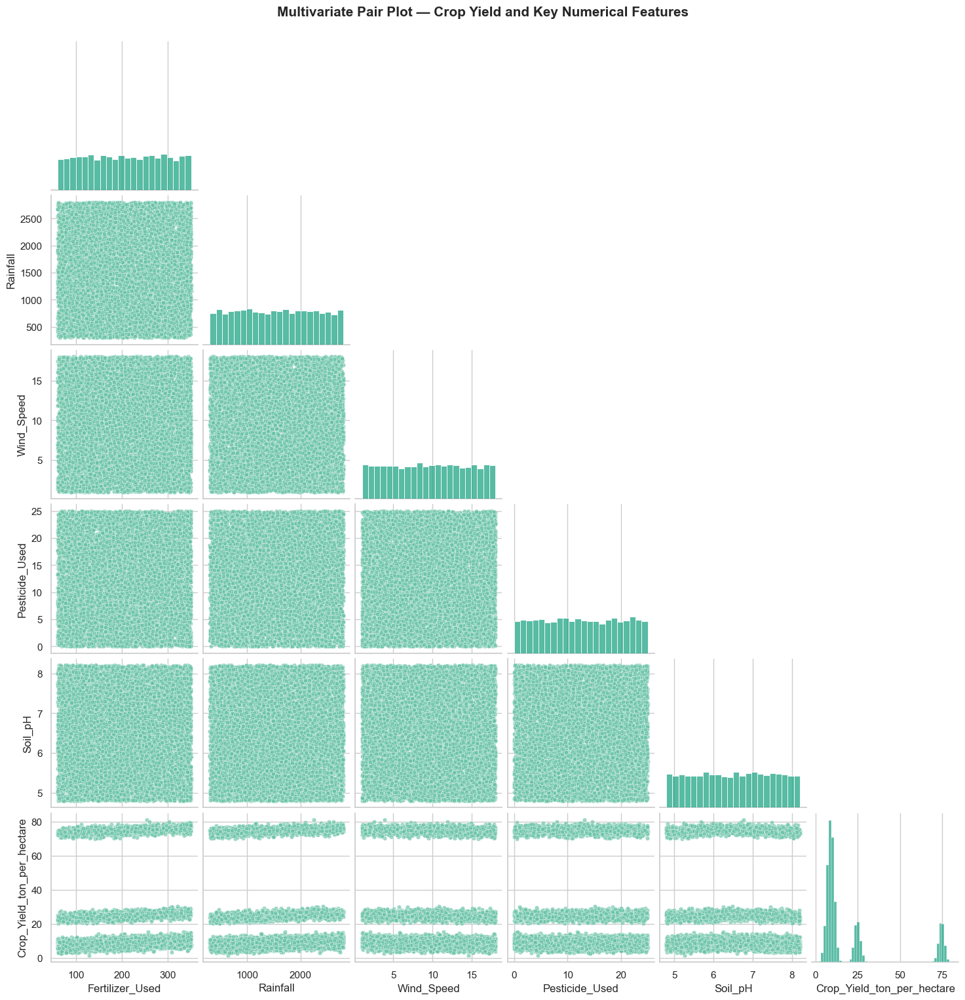

Pair plot saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Multivariate\multivariate_colorful_pairplot.png


In [35]:

# ============================================================
# STEP 6.6.1: MULTIVARIATE EDA — COLORFUL PAIR PLOT
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

MULTIVARIATE_DIR = os.path.join(EDA_DIR, "Multivariate")
os.makedirs(MULTIVARIATE_DIR, exist_ok=True)

target = "Crop_Yield_ton_per_hectare"

# Rank numerical predictors by absolute correlation with target
numeric_cols = df.select_dtypes(include="number").columns.tolist()

if target not in numeric_cols:
    raise ValueError(f"Target column '{target}' is not numerical.")

target_corr = (
    df[numeric_cols]
    .corr()[target]
    .drop(target)
    .dropna()
)

selected_features = (
    target_corr.abs()
    .sort_values(ascending=False)
    .head(5)
    .index.tolist()
)

pairplot_features = selected_features + [target]

print("Selected numerical features:", pairplot_features)

# Prepare complete observations for selected features
pair_data = df[pairplot_features].dropna()

# Colorful pair plot
sns.set_theme(style="whitegrid", palette="Set2")

pair_grid = sns.pairplot(
    pair_data,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.65, "s": 22},
    diag_kws={"color": "#20A486", "edgecolor": "white"}
)

pair_grid.fig.suptitle(
    "Multivariate Pair Plot — Crop Yield and Key Numerical Features",
    y=1.02,
    fontsize=15,
    fontweight="bold"
)

pairplot_path = os.path.join(
    MULTIVARIATE_DIR,
    "multivariate_colorful_pairplot.png"
)

pair_grid.savefig(pairplot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(pair_grid.fig)

print("Pair plot saved:", pairplot_path)


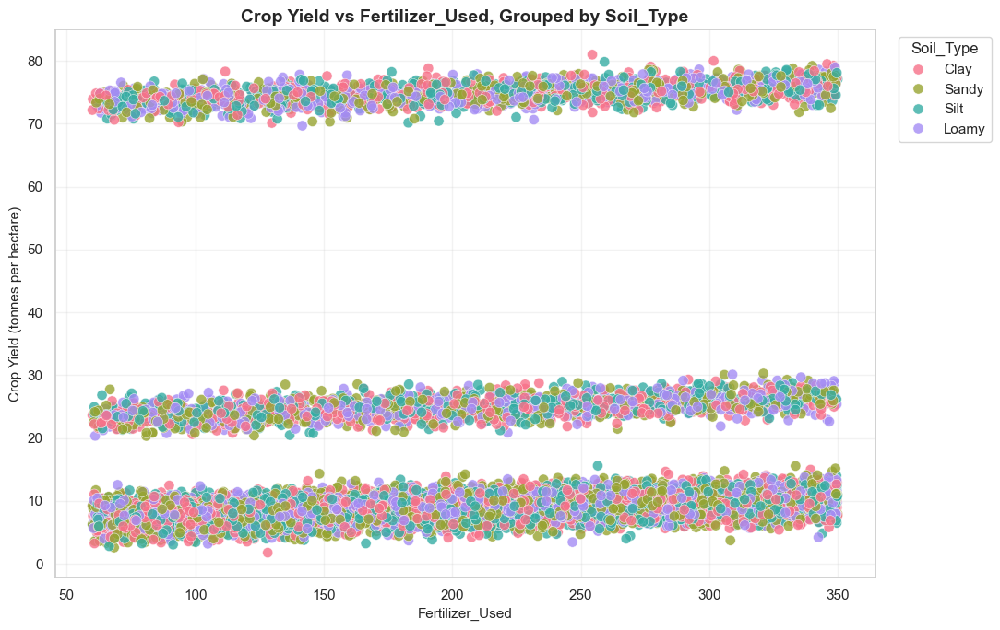

X-axis feature: Fertilizer_Used
Color grouping: Soil_Type
Scatter plot saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Multivariate\multivariate_grouped_colorful_scatter.png


In [36]:

# ============================================================
# STEP 6.6.2: MULTIVARIATE EDA — COLORFUL GROUPED SCATTER PLOT
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

MULTIVARIATE_DIR = os.path.join(EDA_DIR, "Multivariate")
os.makedirs(MULTIVARIATE_DIR, exist_ok=True)

target = "Crop_Yield_ton_per_hectare"

# Find available numerical predictors
numeric_features = [
    col for col in df.select_dtypes(include="number").columns
    if col != target
]

# Select the strongest numerical predictor based on correlation
target_corr = (
    df[numeric_features + [target]]
    .corr()[target]
    .drop(target)
    .dropna()
)

if target_corr.empty:
    raise ValueError("No usable numerical predictors were found.")

x_feature = target_corr.abs().idxmax()

# Find an available categorical feature
available_categories = [
    col for col in categorical_features
    if col in df.columns and df[col].nunique(dropna=True) <= 12
]

if not available_categories:
    available_categories = [
        col for col in df.select_dtypes(
            include=["object", "category", "bool"]
        ).columns
        if df[col].nunique(dropna=True) <= 12
    ]

if not available_categories:
    raise ValueError("No suitable categorical feature was found.")

hue_feature = available_categories[0]

plot_data = df[[x_feature, target, hue_feature]].dropna()

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_data,
    x=x_feature,
    y=target,
    hue=hue_feature,
    palette="husl",
    s=65,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.4
)

plt.title(
    f"Crop Yield vs {x_feature}, Grouped by {hue_feature}",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel(x_feature, fontsize=11)
plt.ylabel("Crop Yield (tonnes per hectare)", fontsize=11)
plt.legend(title=hue_feature, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.25)
plt.tight_layout()

scatter_path = os.path.join(
    MULTIVARIATE_DIR,
    "multivariate_grouped_colorful_scatter.png"
)

plt.savefig(scatter_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("X-axis feature:", x_feature)
print("Color grouping:", hue_feature)
print("Scatter plot saved:", scatter_path)


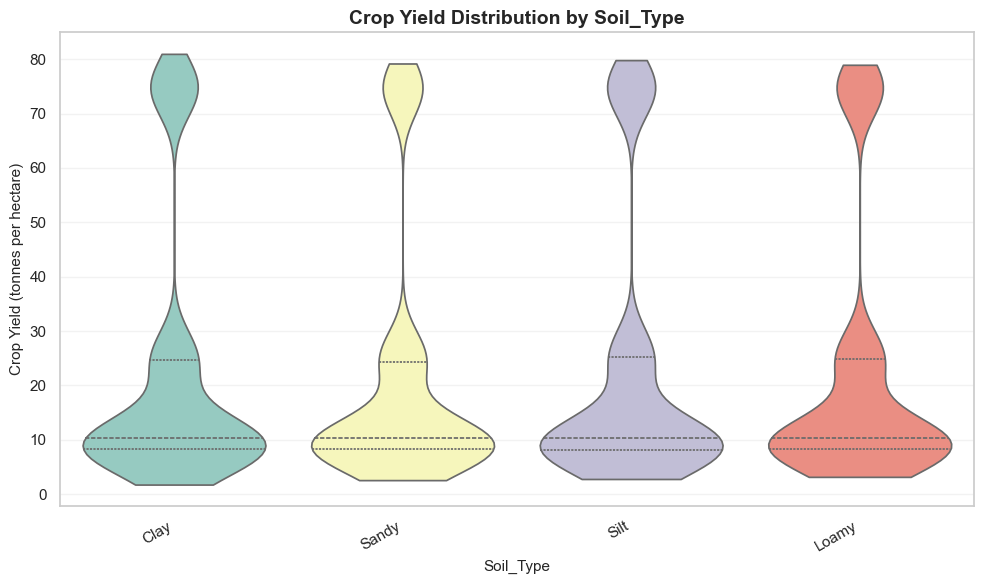

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Multivariate\multivariate_Soil_Type_colorful_violin.png


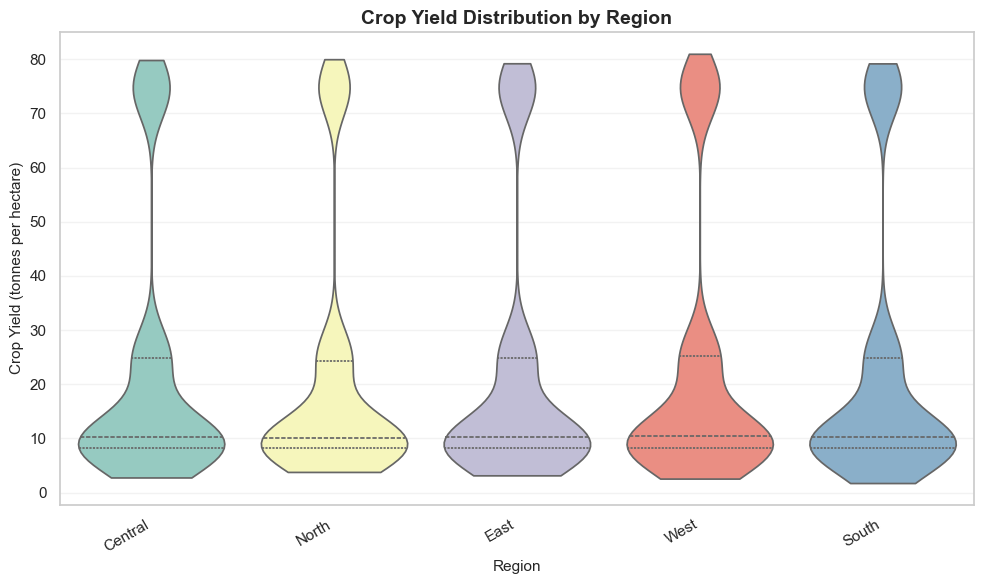

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Multivariate\multivariate_Region_colorful_violin.png


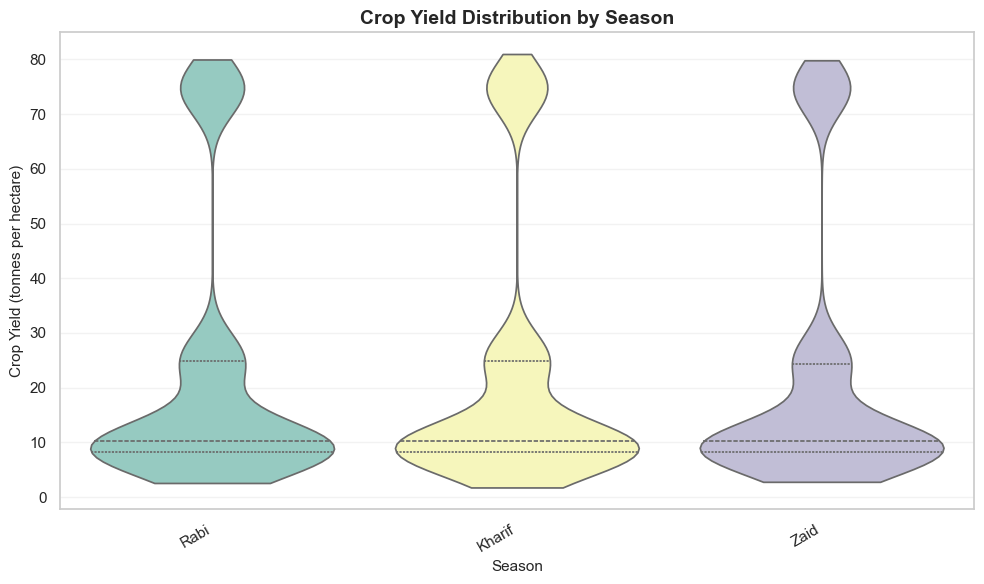

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Multivariate\multivariate_Season_colorful_violin.png


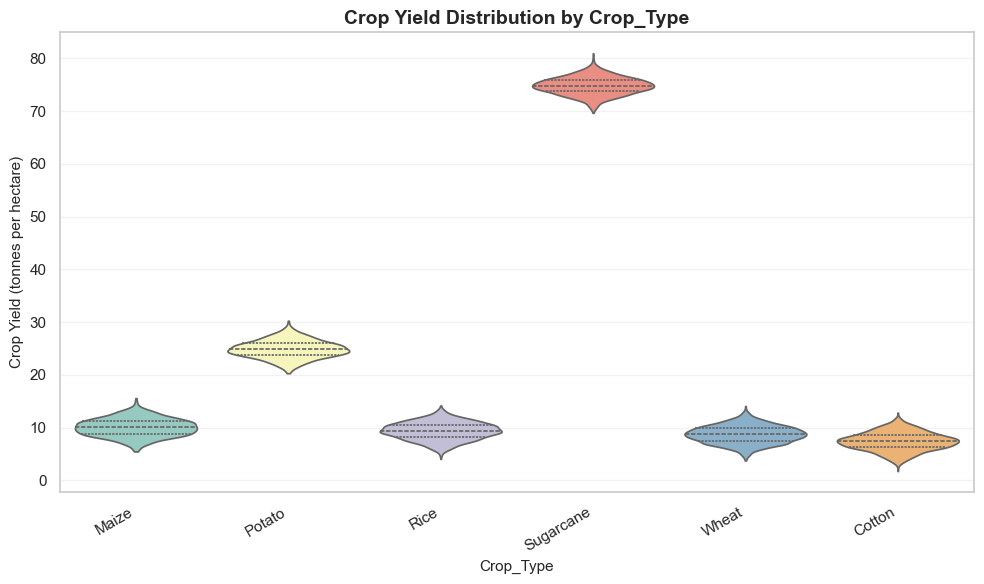

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Multivariate\multivariate_Crop_Type_colorful_violin.png


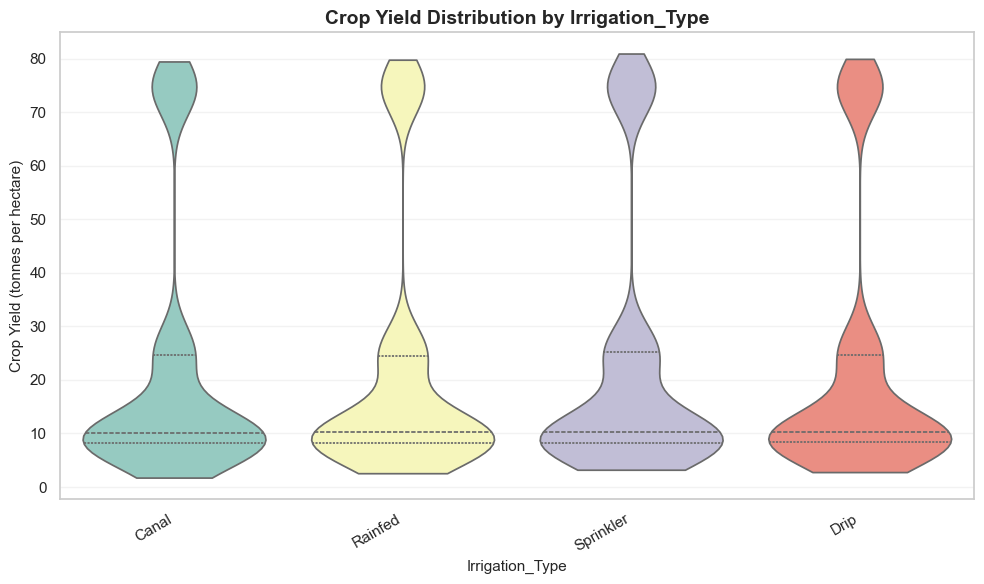

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Multivariate\multivariate_Irrigation_Type_colorful_violin.png

Step 6.6.3 completed!
Multivariate graphs saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Multivariate


In [37]:

# ============================================================
# STEP 6.6.3: MULTIVARIATE EDA — COLORFUL VIOLIN PLOTS
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

MULTIVARIATE_DIR = os.path.join(EDA_DIR, "Multivariate")
os.makedirs(MULTIVARIATE_DIR, exist_ok=True)

target = "Crop_Yield_ton_per_hectare"

# Select categorical features with a manageable number of groups
for feature in categorical_features:

    if feature not in df.columns:
        print(f"Skipped missing feature: {feature}")
        continue

    if df[feature].nunique(dropna=True) > 15:
        print(f"Skipped {feature}: too many categories for a clear violin plot.")
        continue

    plot_data = df[[feature, target]].dropna()

    if plot_data.empty or plot_data[feature].nunique() < 2:
        print(f"Skipped {feature}: insufficient category variation.")
        continue

    plt.figure(figsize=(10, 6))

    sns.violinplot(
        data=plot_data,
        x=feature,
        y=target,
        hue=feature,
        palette="Set3",
        legend=False,
        inner="quartile",
        cut=0
    )

    plt.title(
        f"Crop Yield Distribution by {feature}",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel(feature, fontsize=11)
    plt.ylabel("Crop Yield (tonnes per hectare)", fontsize=11)
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()

    safe_name = (
        feature.replace("/", "_")
        .replace(" ", "_")
        .replace("\\", "_")
    )

    violin_path = os.path.join(
        MULTIVARIATE_DIR,
        f"multivariate_{safe_name}_colorful_violin.png"
    )

    plt.savefig(violin_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", violin_path)

print("\nStep 6.6.3 completed!")
print("Multivariate graphs saved in:", MULTIVARIATE_DIR)


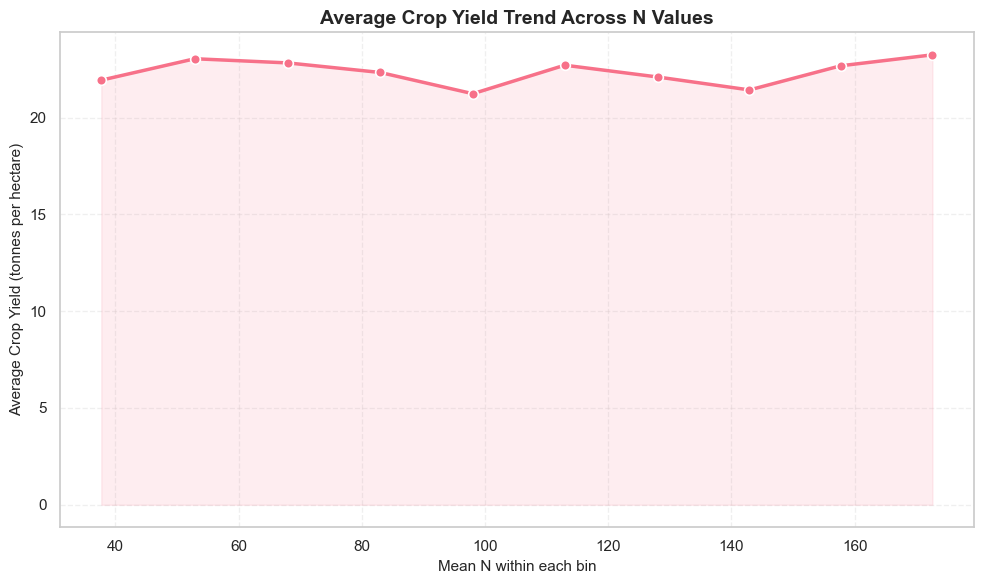

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_N_vs_crop_yield.png


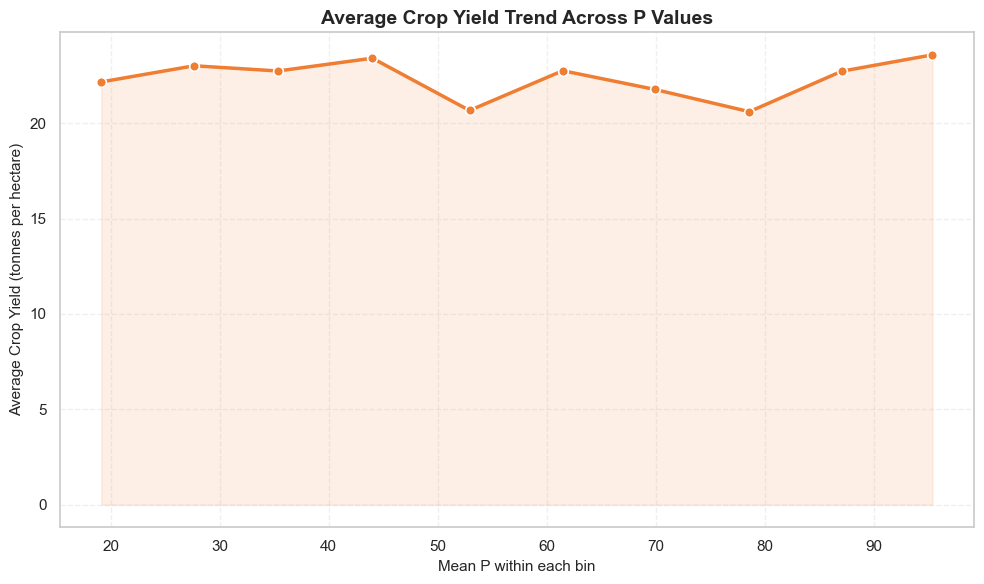

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_P_vs_crop_yield.png


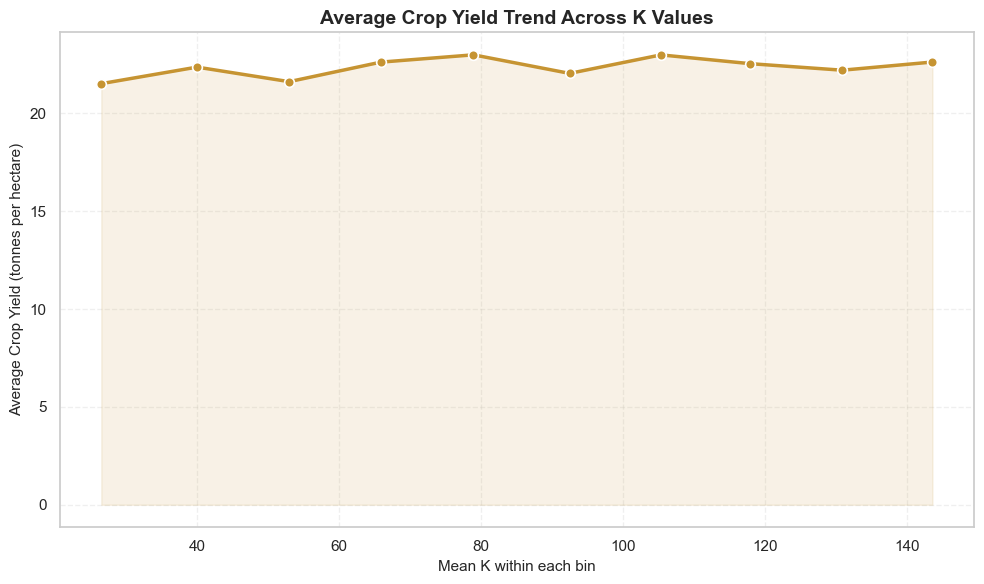

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_K_vs_crop_yield.png


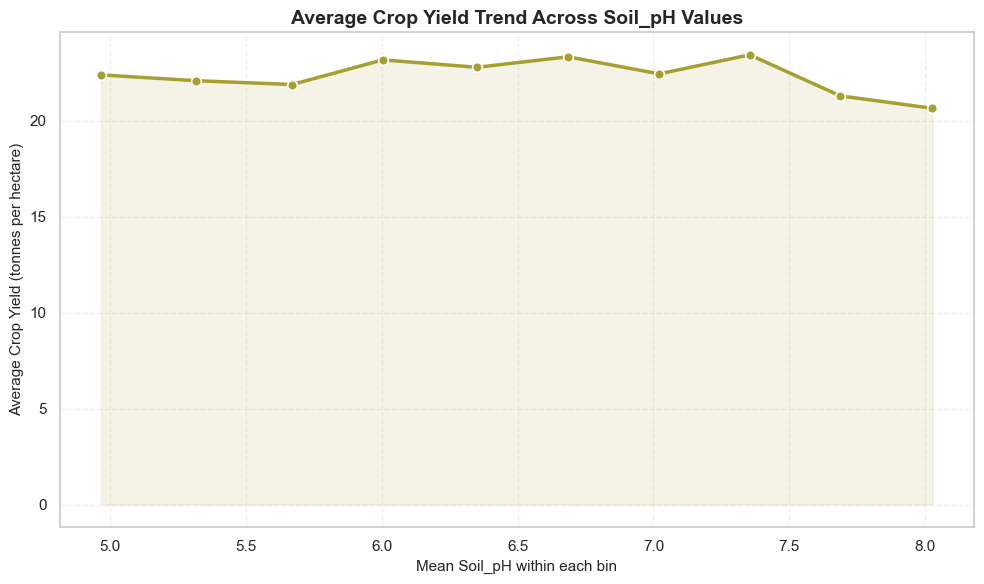

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Soil_pH_vs_crop_yield.png


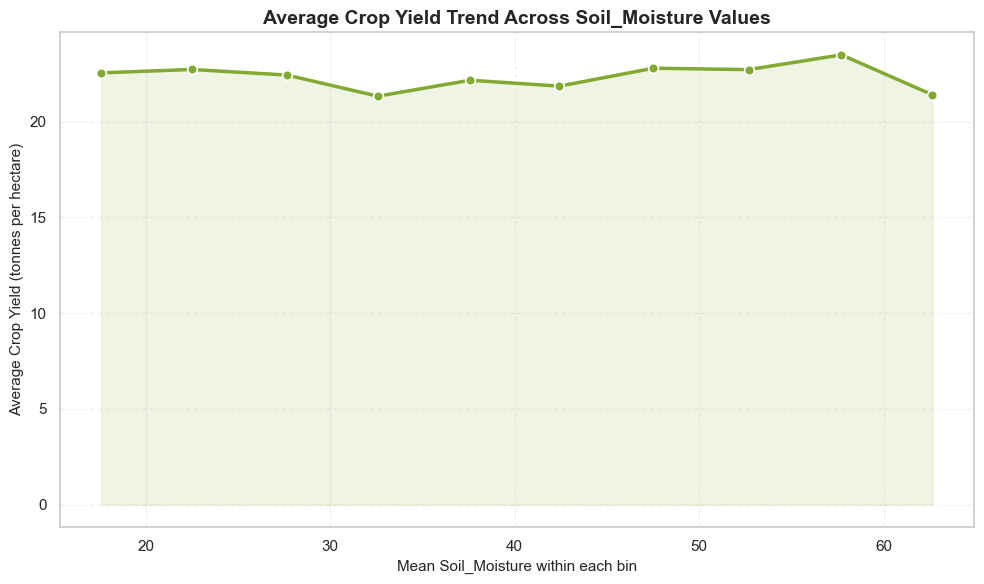

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Soil_Moisture_vs_crop_yield.png


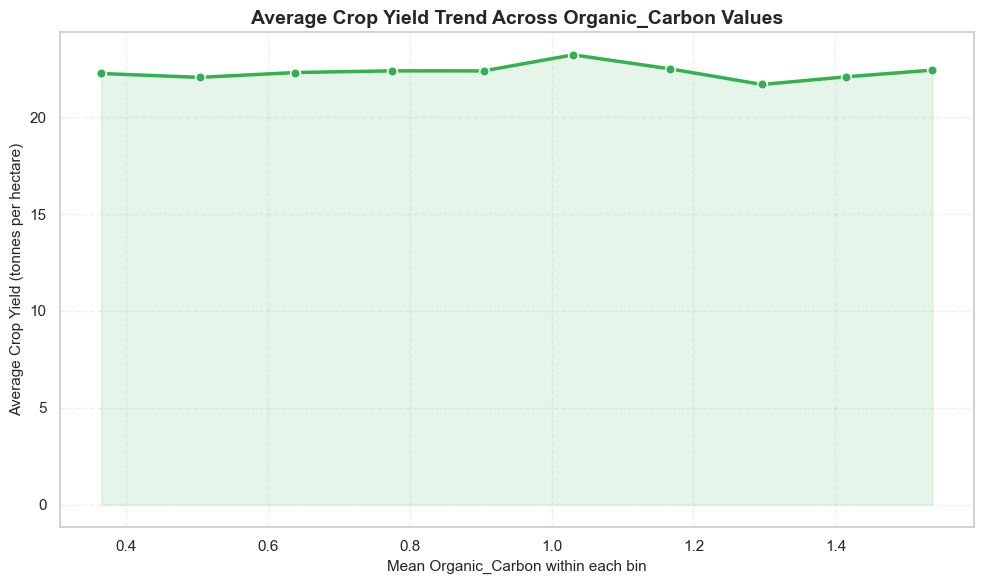

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Organic_Carbon_vs_crop_yield.png


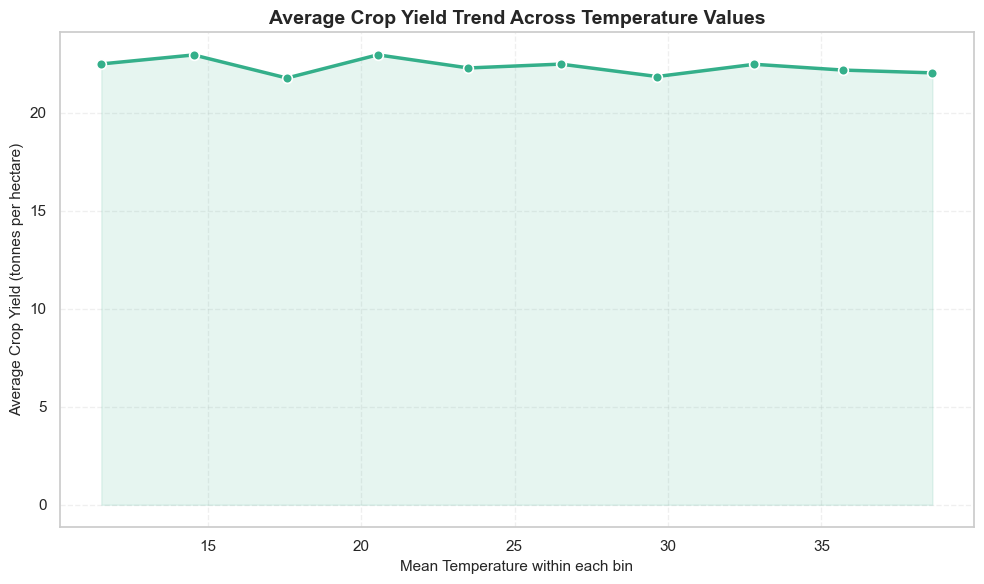

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Temperature_vs_crop_yield.png


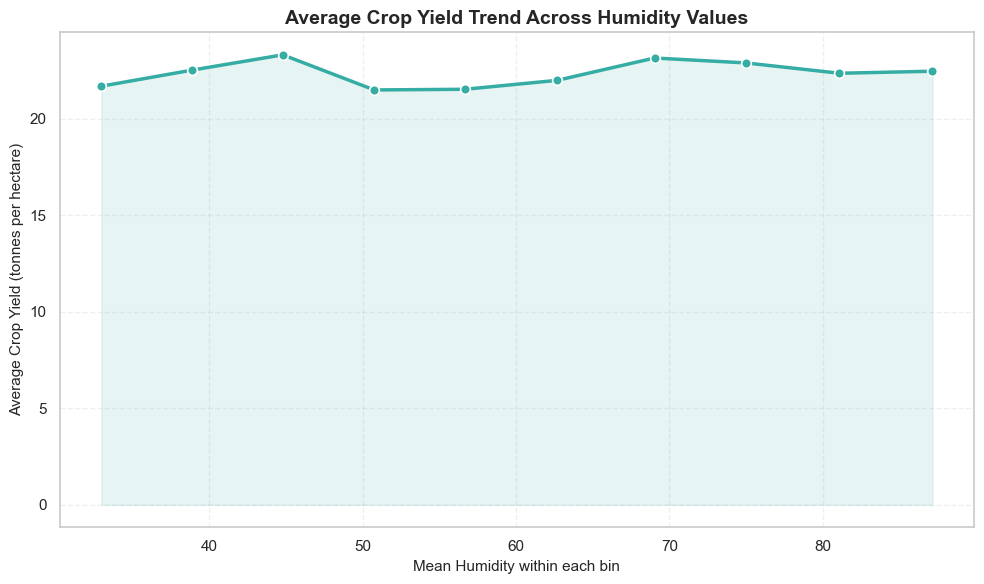

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Humidity_vs_crop_yield.png


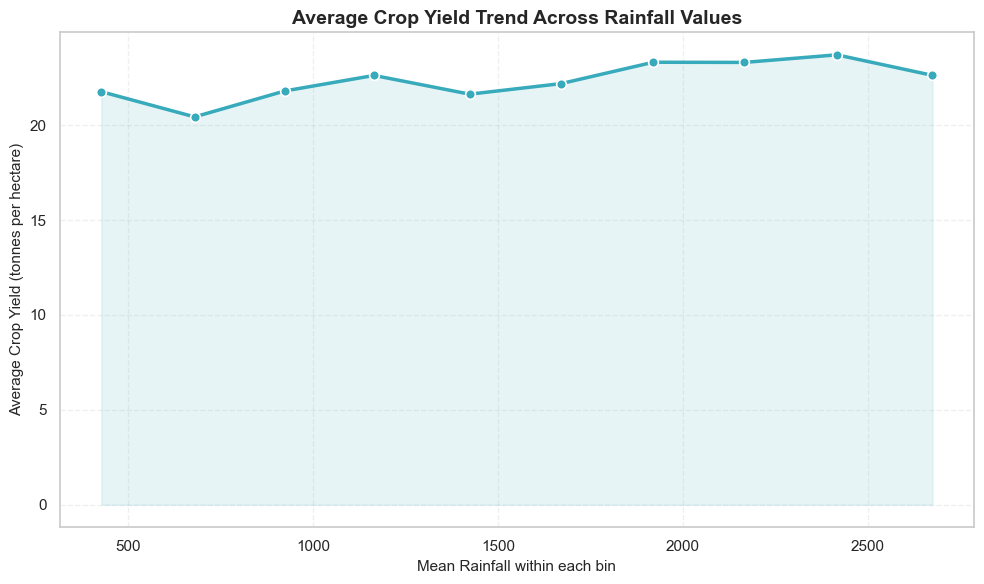

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Rainfall_vs_crop_yield.png


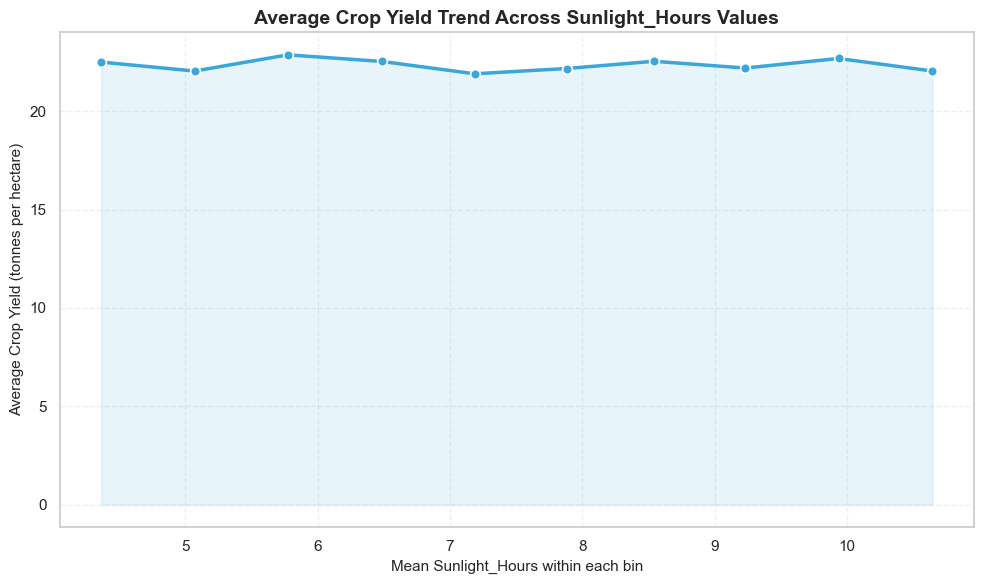

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Sunlight_Hours_vs_crop_yield.png


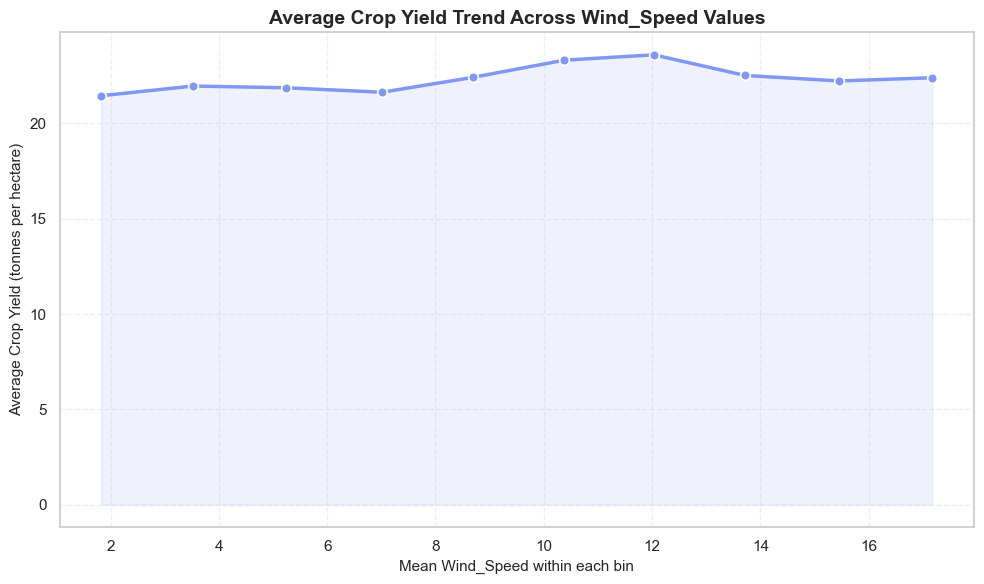

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Wind_Speed_vs_crop_yield.png


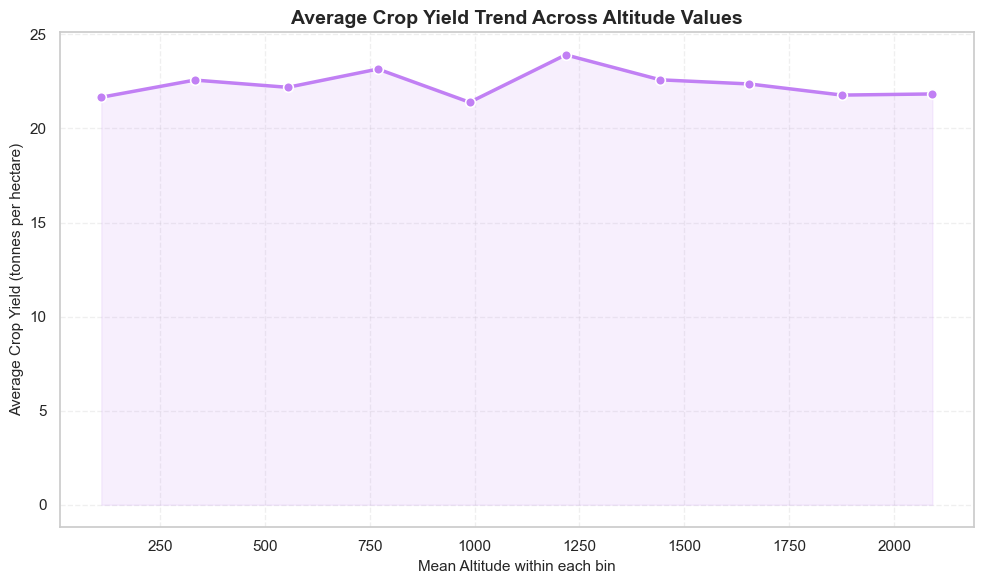

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Altitude_vs_crop_yield.png


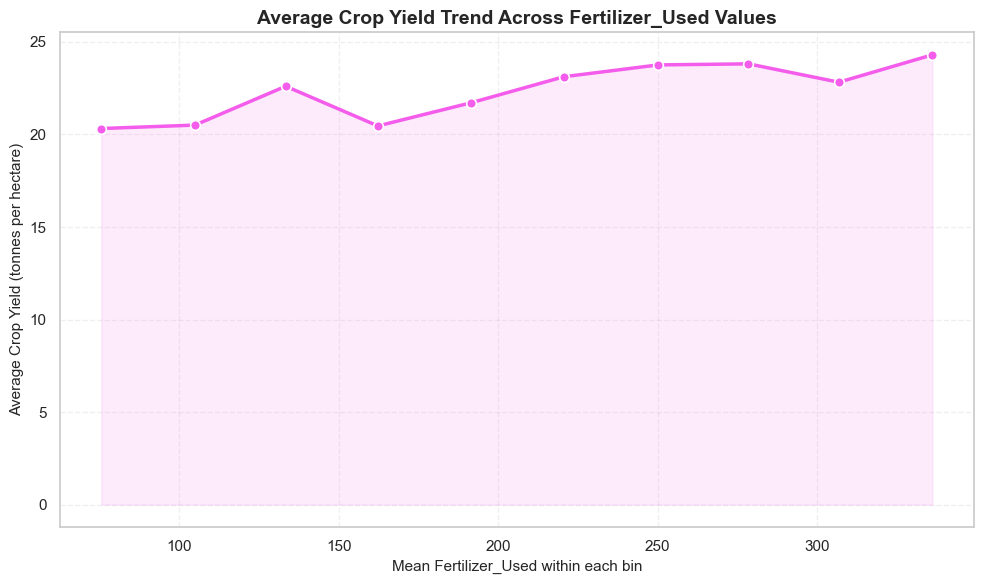

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Fertilizer_Used_vs_crop_yield.png


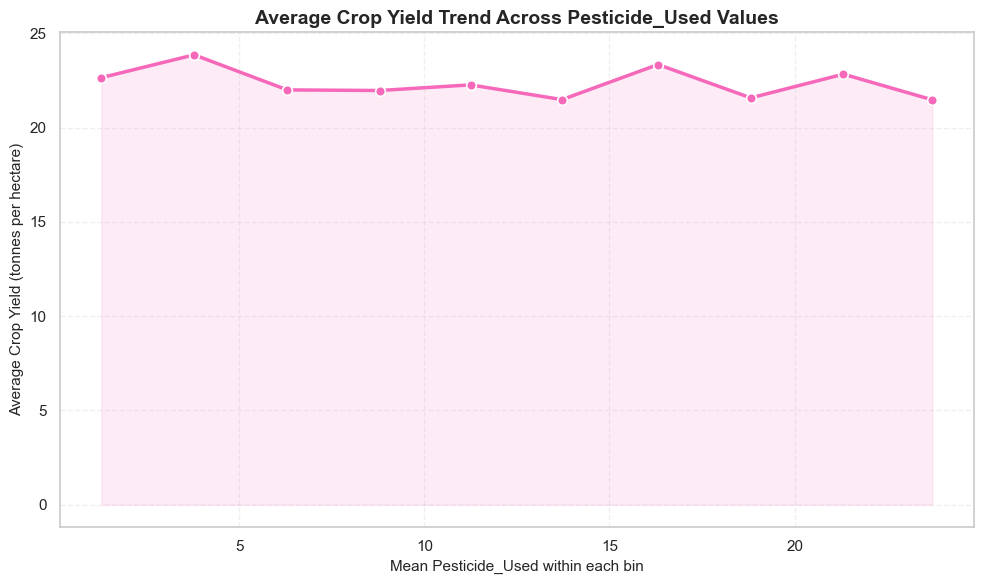

Saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts\line_Pesticide_Used_vs_crop_yield.png

Step 6.7.1 completed!
Line charts saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Line_Charts


In [38]:

# ============================================================
# STEP 6.7.1: LINE CHARTS — NUMERICAL FEATURES VS CROP YIELD
# ============================================================

import os
import re
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Use the existing project-level EDA_Graphs directory
LINE_DIR = os.path.join(EDA_DIR, "Line_Charts")
os.makedirs(LINE_DIR, exist_ok=True)

target = "Crop_Yield_ton_per_hectare"

# Identify numerical predictors
numerical_features = [
    col for col in df.select_dtypes(include="number").columns
    if col != target
]

# Colorful, consistent plotting style
sns.set_theme(style="whitegrid", context="notebook")
palette = sns.color_palette("husl", n_colors=max(1, len(numerical_features)))

for i, feature in enumerate(numerical_features):

    plot_data = df[[feature, target]].dropna().copy()

    # Skip features without enough distinct values
    if plot_data[feature].nunique() < 2:
        print(f"Skipped {feature}: insufficient distinct values.")
        continue

    # Divide feature values into up to 10 quantile-based bins
    plot_data["Feature_Bin"] = pd.qcut(
        plot_data[feature],
        q=10,
        duplicates="drop"
    )

    # Calculate mean feature value and mean crop yield per bin
    trend_data = (
        plot_data.groupby("Feature_Bin", observed=True)
        .agg(
            Mean_Feature=(feature, "mean"),
            Mean_Crop_Yield=(target, "mean"),
            Observation_Count=(target, "size")
        )
        .dropna()
        .sort_values("Mean_Feature")
    )

    if len(trend_data) < 2:
        print(f"Skipped {feature}: insufficient populated bins.")
        continue

    # Create an individual line chart
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(
        trend_data["Mean_Feature"],
        trend_data["Mean_Crop_Yield"],
        color=palette[i],
        marker="o",
        markersize=7,
        linewidth=2.5,
        markeredgecolor="white",
        markeredgewidth=1.2
    )

    ax.fill_between(
        trend_data["Mean_Feature"],
        trend_data["Mean_Crop_Yield"],
        alpha=0.12,
        color=palette[i]
    )

    ax.set_title(
        f"Average Crop Yield Trend Across {feature} Values",
        fontsize=14,
        fontweight="bold"
    )
    ax.set_xlabel(f"Mean {feature} within each bin", fontsize=11)
    ax.set_ylabel("Average Crop Yield (tonnes per hectare)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.3)

    plt.tight_layout()

    # Generate a safe filename
    safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", feature)

    path = os.path.join(
        LINE_DIR,
        f"line_{safe_name}_vs_crop_yield.png"
    )

    # Save and display each graph individually
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", path)

print("\nStep 6.7.1 completed!")
print("Line charts saved in:", LINE_DIR)


In [39]:

# ============================================================
# STEP 7.1: DATASET INSPECTION BEFORE FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np

# Preserve the original dataset
df_original = df.copy(deep=True)

target = "Crop_Yield_ton_per_hectare"

print("=" * 60)
print("STEP 7.1: DATASET INSPECTION")
print("=" * 60)

# Dataset dimensions
print("\nDataset shape:", df.shape)

# Original column names
print("\nAll column names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

# Data types and missing values
print("\nColumn information:")
df.info()

print("\nMissing values:")
display(
    df.isnull().sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Confirm target exists
if target not in df.columns:
    raise ValueError(f"Target column '{target}' was not found.")

print("\nTarget variable:", target)
print("Target data type:", df[target].dtype)
print("Target unique values:", df[target].nunique())

# Numerical predictor summary
print("\nNumerical predictor summary:")
display(
    df.select_dtypes(include="number")
    .drop(columns=[target], errors="ignore")
    .describe()
    .T.round(3)
)

# Categorical predictor summary
print("\nCategorical predictor summary:")
display(
    df.select_dtypes(include=["object", "category", "bool"])
    .describe()
    .T
)

print("\nStep 7.1 completed successfully!")


STEP 7.1: DATASET INSPECTION

Dataset shape: (10000, 20)

All column names:
1. N
2. P
3. K
4. Soil_pH
5. Soil_Moisture
6. Soil_Type
7. Organic_Carbon
8. Temperature
9. Humidity
10. Rainfall
11. Sunlight_Hours
12. Wind_Speed
13. Region
14. Altitude
15. Season
16. Crop_Type
17. Irrigation_Type
18. Fertilizer_Used
19. Pesticide_Used
20. Crop_Yield_ton_per_hectare

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   N                           10000 non-null  int64  
 1   P                           10000 non-null  int64  
 2   K                           10000 non-null  int64  
 3   Soil_pH                     10000 non-null  float64
 4   Soil_Moisture               10000 non-null  float64
 5   Soil_Type                   10000 non-null  object 
 6   Organic_Carbon              10000 non-null  flo

,Missing_Count



Duplicate rows: 0

Target variable: Crop_Yield_ton_per_hectare
Target data type: float64
Target unique values: 2191

Numerical predictor summary:


,count,mean,std,min,25%,50%,75%,max
N,10000.0,104.983,43.292,30.00,68.000,105.00,142.000,179.00
P,10000.0,56.810,24.523,15.00,35.000,57.00,78.000,99.00
K,10000.0,85.009,37.541,20.00,52.000,85.00,118.000,149.00
Soil_pH,10000.0,6.504,0.979,4.80,5.670,6.52,7.350,8.20
Soil_Moisture,10000.0,40.084,14.462,15.00,27.630,40.00,52.762,64.99
Organic_Carbon,10000.0,0.958,0.375,0.30,0.630,0.96,1.290,1.60
Temperature,10000.0,25.097,8.719,10.00,17.590,24.97,32.830,40.00
Humidity,10000.0,59.894,17.402,30.01,44.830,59.55,75.038,89.99
Rainfall,10000.0,1546.695,718.866,300.70,925.767,1548.55,2165.452,2799.26
Sunlight_Hours,10000.0,7.508,2.006,4.00,5.770,7.53,9.220,11.00



Categorical predictor summary:


,count,unique,top,freq
Soil_Type,10000,4,Loamy,2543
Region,10000,5,South,2013
Season,10000,3,Rabi,3355
Crop_Type,10000,6,Rice,1702
Irrigation_Type,10000,4,Drip,2532



Step 7.1 completed successfully!


In [40]:

# ============================================================
# STEP 7.2.1: FEATURE ENGINEERING
# ============================================================

import os
import numpy as np
import pandas as pd

# Target variable
target = "Crop_Yield_ton_per_hectare"

# Preserve the original dataset
df_feature_engineered = df.copy(deep=True)

# ------------------------------------------------------------
# 1. Nutrient-based features
# ------------------------------------------------------------

# Combined amount of the three primary soil nutrients
df_feature_engineered["NPK_Total"] = (
    df_feature_engineered["N"]
    + df_feature_engineered["P"]
    + df_feature_engineered["K"]
)

# Nitrogen relative to the combined phosphorus and potassium
df_feature_engineered["N_to_PK_Ratio"] = (
    df_feature_engineered["N"]
    / (df_feature_engineered["P"] + df_feature_engineered["K"] + 1e-8)
)

# ------------------------------------------------------------
# 2. Soil-based feature
# ------------------------------------------------------------

# Distance from neutral pH (7); this does not assume
# that neutral pH is optimal for every crop.
df_feature_engineered["Soil_pH_Deviation"] = (
    df_feature_engineered["Soil_pH"] - 7
).abs()

# ------------------------------------------------------------
# 3. Environmental interaction features
# ------------------------------------------------------------

# Combined soil moisture and atmospheric humidity indicator
df_feature_engineered["Moisture_Humidity_Interaction"] = (
    df_feature_engineered["Soil_Moisture"]
    * df_feature_engineered["Humidity"] / 100
)

# Combined rainfall and sunlight indicator
df_feature_engineered["Rainfall_Sunlight_Interaction"] = (
    df_feature_engineered["Rainfall"]
    * df_feature_engineered["Sunlight_Hours"]
)

# ------------------------------------------------------------
# 4. Agricultural input feature
# ------------------------------------------------------------

# Fertilizer amount relative to the combined NPK values
df_feature_engineered["Fertilizer_to_NPK_Ratio"] = (
    df_feature_engineered["Fertilizer_Used"]
    / (df_feature_engineered["NPK_Total"] + 1e-8)
)

# ------------------------------------------------------------
# 5. Validate the engineered dataset
# ------------------------------------------------------------

new_features = [
    "NPK_Total",
    "N_to_PK_Ratio",
    "Soil_pH_Deviation",
    "Moisture_Humidity_Interaction",
    "Rainfall_Sunlight_Interaction",
    "Fertilizer_to_NPK_Ratio"
]

print("=" * 60)
print("STEP 7.2.1: FEATURE ENGINEERING RESULTS")
print("=" * 60)

print("\nOriginal dataset shape:", df.shape)
print("Engineered dataset shape:", df_feature_engineered.shape)

print("\nNew features created:")
for feature in new_features:
    print("-", feature)

print("\nEngineered feature summary:")
display(df_feature_engineered[new_features].describe().T.round(3))

print("\nMissing values in new features:")
display(df_feature_engineered[new_features].isnull().sum().to_frame("Missing_Count"))

print("\nInfinite values in new features:")
display(
    pd.Series(
        np.isinf(
            df_feature_engineered[new_features].to_numpy(dtype=float)
        ).sum(axis=0),
        index=new_features,
        name="Infinite_Count"
    ).to_frame()
)

# ------------------------------------------------------------
# 6. Save the engineered dataset
# ------------------------------------------------------------

PROJECT_DIR = os.path.dirname(os.path.abspath(EDA_DIR))

FEATURE_DIR = os.path.join(
    PROJECT_DIR,
    "Feature_Engineered_Data"
)
os.makedirs(FEATURE_DIR, exist_ok=True)

output_path = os.path.join(
    FEATURE_DIR,
    "crop_yield_feature_engineered.csv"
)

df_feature_engineered.to_csv(output_path, index=False)

print("\nOriginal dataset remains unchanged:", df.equals(df_original))
print("Engineered dataset saved to:", output_path)
print("\nStep 7.2.1 completed!")


STEP 7.2.1: FEATURE ENGINEERING RESULTS

Original dataset shape: (10000, 20)
Engineered dataset shape: (10000, 26)

New features created:
- NPK_Total
- N_to_PK_Ratio
- Soil_pH_Deviation
- Moisture_Humidity_Interaction
- Rainfall_Sunlight_Interaction
- Fertilizer_to_NPK_Ratio

Engineered feature summary:


,count,mean,std,min,25%,50%,75%,max
NPK_Total,10000.0,246.801,62.199,74.000,203.000,247.000,291.000,414.000
N_to_PK_Ratio,10000.0,0.838,0.501,0.129,0.475,0.749,1.066,4.268
Soil_pH_Deviation,10000.0,0.917,0.602,0.000,0.420,0.840,1.330,2.200
Moisture_Humidity_Interaction,10000.0,23.976,11.300,4.652,15.174,22.036,31.179,58.150
Rainfall_Sunlight_Interaction,10000.0,11610.522,6393.284,1300.166,6421.094,10716.786,15867.215,30663.517
Fertilizer_to_NPK_Ratio,10000.0,0.898,0.466,0.164,0.541,0.833,1.162,3.834



Missing values in new features:


,Missing_Count
NPK_Total,0
N_to_PK_Ratio,0
Soil_pH_Deviation,0
Moisture_Humidity_Interaction,0
Rainfall_Sunlight_Interaction,0
Fertilizer_to_NPK_Ratio,0



Infinite values in new features:


,Infinite_Count
NPK_Total,0
N_to_PK_Ratio,0
Soil_pH_Deviation,0
Moisture_Humidity_Interaction,0
Rainfall_Sunlight_Interaction,0
Fertilizer_to_NPK_Ratio,0



Original dataset remains unchanged: True
Engineered dataset saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Engineered_Data\crop_yield_feature_engineered.csv

Step 7.2.1 completed!


STEP 7.3.1: ENGINEERED FEATURE DISTRIBUTIONS


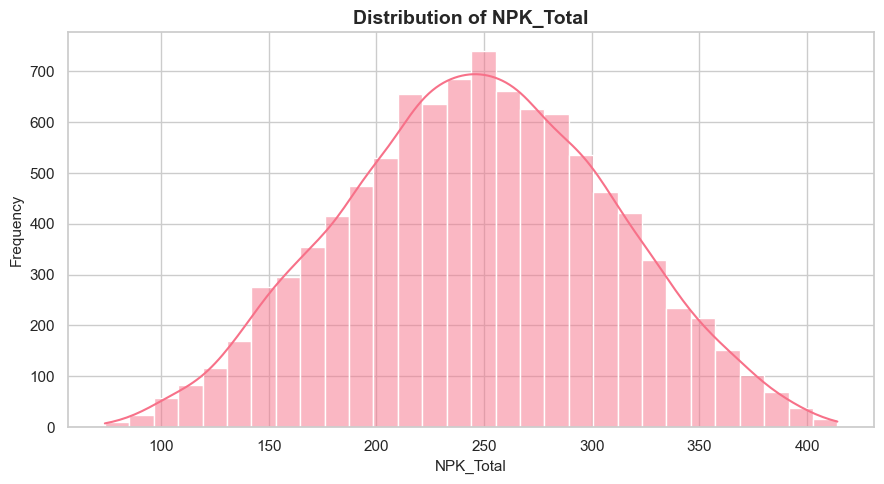

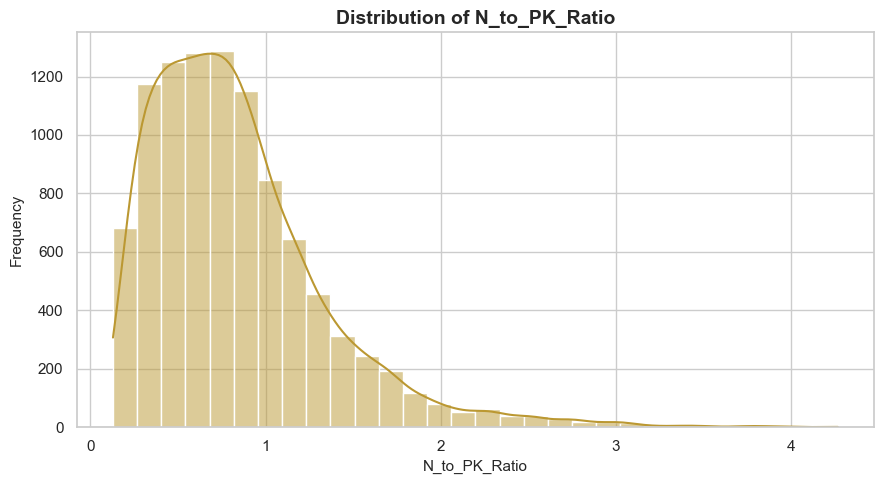

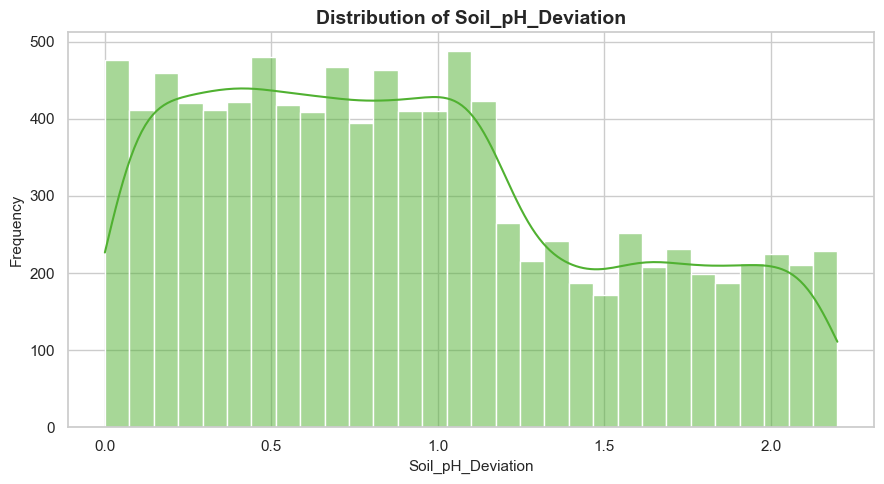

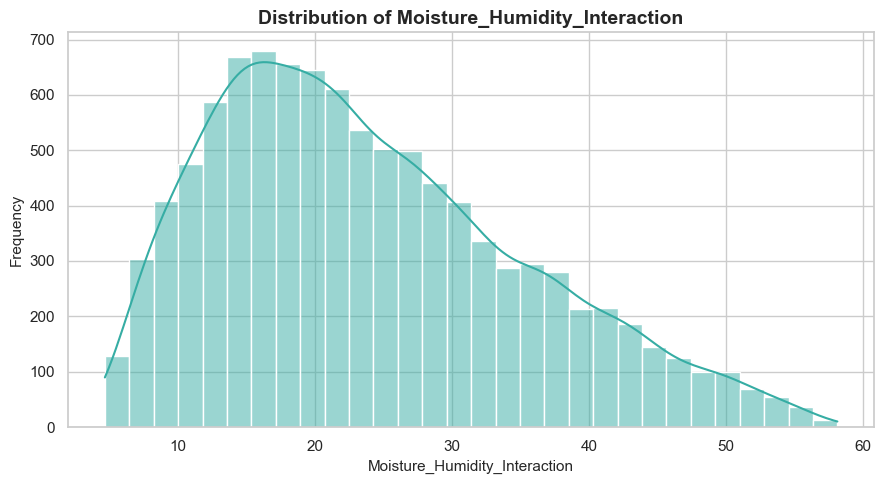

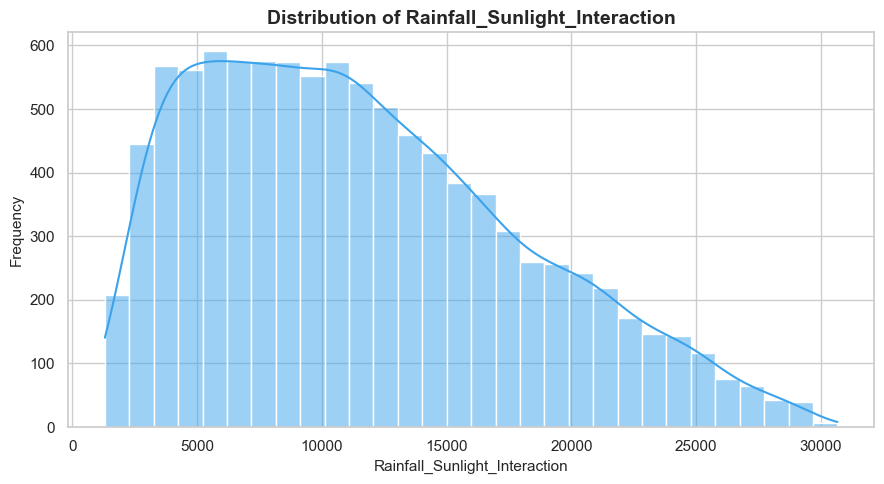

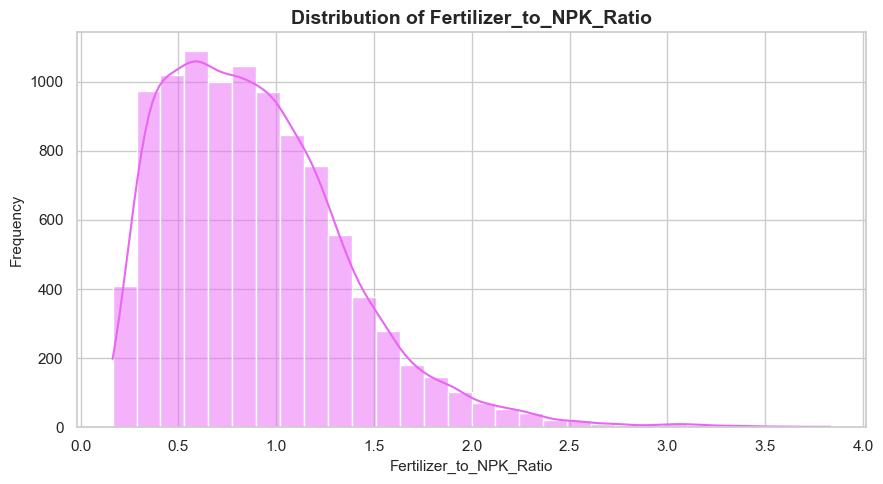


ENGINEERED FEATURE SUMMARY


,NPK_Total,N_to_PK_Ratio,Soil_pH_Deviation,Moisture_Humidity_Interaction,Rainfall_Sunlight_Interaction,Fertilizer_to_NPK_Ratio
count,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000
mean,246.8013,0.8376,0.9173,23.9757,11610.5218,0.8978
std,62.1987,0.5015,0.6017,11.3004,6393.2841,0.4663
min,74.0000,0.1288,0.0000,4.6525,1300.1664,0.1640
25%,203.0000,0.4747,0.4200,15.1743,6421.0940,0.5413
50%,247.0000,0.7487,0.8400,22.0365,10716.7865,0.8332
75%,291.0000,1.0657,1.3300,31.1787,15867.2148,1.1615
max,414.0000,4.2683,2.2000,58.1504,30663.5166,3.8339



Graphs saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Feature_Engineering
Number of distribution graphs saved: 6


In [41]:

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Target and engineered features
target = "Crop_Yield_ton_per_hectare"

engineered_features = [
    "NPK_Total",
    "N_to_PK_Ratio",
    "Soil_pH_Deviation",
    "Moisture_Humidity_Interaction",
    "Rainfall_Sunlight_Interaction",
    "Fertilizer_to_NPK_Ratio"
]

# Save graphs in the project-root EDA_Graphs folder
FEATURE_EDA_DIR = os.path.join(EDA_DIR, "Feature_Engineering")
os.makedirs(FEATURE_EDA_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

print("=" * 65)
print("STEP 7.3.1: ENGINEERED FEATURE DISTRIBUTIONS")
print("=" * 65)

# Validate that all expected features exist
missing_features = [
    col for col in engineered_features
    if col not in df_feature_engineered.columns
]

if missing_features:
    raise ValueError(f"Missing engineered features: {missing_features}")

# Plot and save each feature individually
for feature in engineered_features:
    values = df_feature_engineered[feature].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    plt.figure(figsize=(9, 5))
    sns.histplot(
        values,
        bins=30,
        kde=True,
        color=sns.color_palette("husl", 6)[
            engineered_features.index(feature)
        ],
        edgecolor="white"
    )

    plt.title(f"Distribution of {feature}", fontsize=14, fontweight="bold")
    plt.xlabel(feature, fontsize=11)
    plt.ylabel("Frequency", fontsize=11)
    plt.tight_layout()

    filename = f"{feature}_Distribution.jpg"
    plt.savefig(
        os.path.join(FEATURE_EDA_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# Summary statistics for the engineered features
print("\nENGINEERED FEATURE SUMMARY")
display(
    df_feature_engineered[engineered_features]
    .describe()
    .round(4)
)

print(f"\nGraphs saved in: {FEATURE_EDA_DIR}")
print(f"Number of distribution graphs saved: {len(engineered_features)}")


STEP 7.3.2: ENGINEERED FEATURES VS CROP YIELD


,Engineered_Feature,Correlation_with_Crop_Yield
0,Soil_pH_Deviation,-0.0098
1,N_to_PK_Ratio,-0.0045
2,NPK_Total,0.0066
3,Moisture_Humidity_Interaction,0.0068
4,Rainfall_Sunlight_Interaction,0.0254
5,Fertilizer_to_NPK_Ratio,0.0343


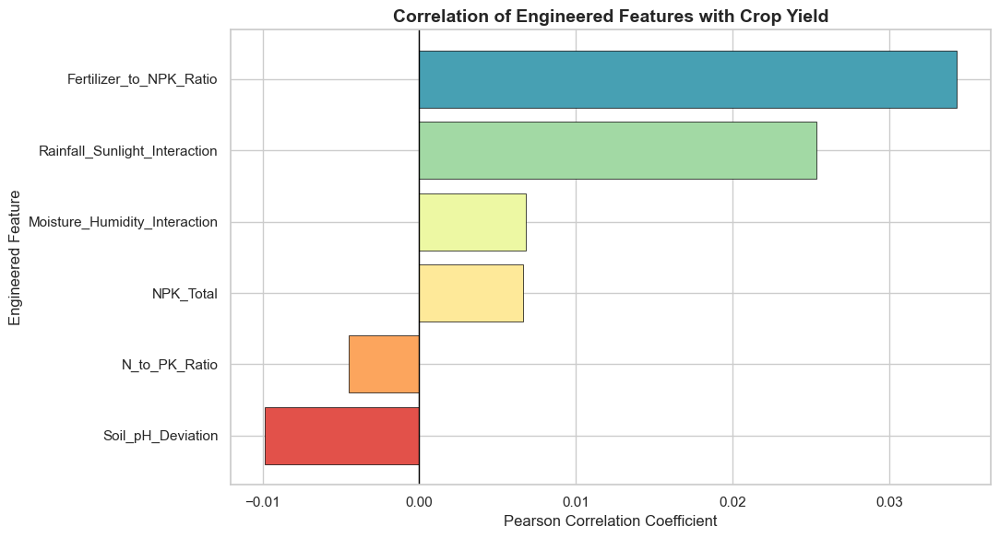

Correlation graph saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Feature_Engineering\Engineered_Features_Target_Correlation.jpg
Correlation table saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\EDA_Graphs\Feature_Engineering\Engineered_Features_Target_Correlation.csv


In [42]:

print("=" * 65)
print("STEP 7.3.2: ENGINEERED FEATURES VS CROP YIELD")
print("=" * 65)

# Calculate Pearson correlations for analysis only
correlation_values = (
    df_feature_engineered[engineered_features + [target]]
    .corr(numeric_only=True)[target]
    .drop(target)
    .sort_values()
)

correlation_df = correlation_values.rename(
    "Correlation_with_Crop_Yield"
).reset_index()

correlation_df.columns = ["Engineered_Feature", "Correlation_with_Crop_Yield"]

display(correlation_df.round(4))

# Colorful horizontal bar chart
plt.figure(figsize=(11, 6))

colors = sns.color_palette("Spectral", len(correlation_values))

plt.barh(
    correlation_values.index,
    correlation_values.values,
    color=colors,
    edgecolor="black",
    linewidth=0.5
)

plt.axvline(0, color="black", linewidth=1)
plt.title(
    "Correlation of Engineered Features with Crop Yield",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Engineered Feature")
plt.tight_layout()

correlation_plot_path = os.path.join(
    FEATURE_EDA_DIR,
    "Engineered_Features_Target_Correlation.jpg"
)

plt.savefig(correlation_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Save correlation table
correlation_csv_path = os.path.join(
    FEATURE_EDA_DIR,
    "Engineered_Features_Target_Correlation.csv"
)

correlation_df.to_csv(correlation_csv_path, index=False)

print(f"Correlation graph saved: {correlation_plot_path}")
print(f"Correlation table saved: {correlation_csv_path}")


In [43]:

print("=" * 65)
print("STEP 7.3.3: ENGINEERED FEATURE QUALITY CHECK")
print("=" * 65)

feature_quality = pd.DataFrame({
    "Feature": engineered_features,
    "Missing_Values": [
        df_feature_engineered[col].isna().sum()
        for col in engineered_features
    ],
    "Infinite_Values": [
        np.isinf(
            df_feature_engineered[col].to_numpy(dtype=float)
        ).sum()
        for col in engineered_features
    ],
    "Unique_Values": [
        df_feature_engineered[col].nunique()
        for col in engineered_features
    ],
    "Standard_Deviation": [
        df_feature_engineered[col].std()
        for col in engineered_features
    ]
})

display(feature_quality.round(4))

print("\nOriginal dataset shape:", df.shape)
print("Feature-engineered dataset shape:", df_feature_engineered.shape)
print("Original dataset remains unchanged:", df.equals(df_original))

if (
    feature_quality["Missing_Values"].sum() == 0
    and feature_quality["Infinite_Values"].sum() == 0
    and (feature_quality["Standard_Deviation"] > 0).all()
):
    print("\nValidation passed: no missing/infinite values or constant engineered features.")
else:
    print("\nReview the quality table before proceeding.")


STEP 7.3.3: ENGINEERED FEATURE QUALITY CHECK


,Feature,Missing_Values,Infinite_Values,Unique_Values,Standard_Deviation
0,NPK_Total,0,0,332,62.1987
1,N_to_PK_Ratio,0,0,8273,0.5015
2,Soil_pH_Deviation,0,0,231,0.6017
3,Moisture_Humidity_Interaction,0,0,9997,11.3004
4,Rainfall_Sunlight_Interaction,0,0,9997,6393.2841
5,Fertilizer_to_NPK_Ratio,0,0,9988,0.4663



Original dataset shape: (10000, 20)
Feature-engineered dataset shape: (10000, 26)
Original dataset remains unchanged: True

Validation passed: no missing/infinite values or constant engineered features.


In [44]:

import os
import numpy as np
import pandas as pd

print("=" * 65)
print("STEP 7.4: FINAL FEATURE ENGINEERING VALIDATION")
print("=" * 65)

target = "Crop_Yield_ton_per_hectare"

engineered_features = [
    "NPK_Total",
    "N_to_PK_Ratio",
    "Soil_pH_Deviation",
    "Moisture_Humidity_Interaction",
    "Rainfall_Sunlight_Interaction",
    "Fertilizer_to_NPK_Ratio"
]

# 1. Verify required columns
assert target in df_feature_engineered.columns, "Target column is missing."

missing_engineered = [
    col for col in engineered_features
    if col not in df_feature_engineered.columns
]
assert not missing_engineered, f"Missing engineered features: {missing_engineered}"

# 2. Verify original columns are preserved
original_columns = list(df.columns)
missing_original = [
    col for col in original_columns
    if col not in df_feature_engineered.columns
]
assert not missing_original, f"Original columns missing: {missing_original}"

# 3. Check missing and infinite values
numeric_data = df_feature_engineered.select_dtypes(include=np.number)

missing_count = int(df_feature_engineered.isna().sum().sum())
infinite_count = int(
    np.isinf(numeric_data.to_numpy(dtype=float)).sum()
)

# 4. Confirm target values remain unchanged
target_unchanged = df_feature_engineered[target].equals(df[target])

print("Original dataset shape:", df.shape)
print("Feature-engineered dataset shape:", df_feature_engineered.shape)
print("Original columns preserved:", not missing_original)
print("Target unchanged:", target_unchanged)
print("Total missing values:", missing_count)
print("Total infinite numeric values:", infinite_count)

# 5. Save finalized dataset only if validation passes
if missing_count == 0 and infinite_count == 0 and target_unchanged:
    PROJECT_DIR = os.path.dirname(os.path.abspath(EDA_DIR))
    FEATURE_DIR = os.path.join(PROJECT_DIR, "Feature_Engineered_Data")
    os.makedirs(FEATURE_DIR, exist_ok=True)

    final_path = os.path.join(
        FEATURE_DIR,
        "crop_yield_feature_engineered_final.csv"
    )

    df_feature_engineered.to_csv(final_path, index=False)

    print("\nFINALIZATION SUCCESSFUL!")
    print("Final dataset saved to:", final_path)
    print("Original features:", len(original_columns))
    print("New engineered features:", len(engineered_features))
    print("Total columns:", df_feature_engineered.shape[1])
else:
    print("\nValidation failed. Review the checks before saving.")

print("\nEngineered features finalized as candidates:")
for i, feature in enumerate(engineered_features, start=1):
    print(f"{i}. {feature}")


STEP 7.4: FINAL FEATURE ENGINEERING VALIDATION
Original dataset shape: (10000, 20)
Feature-engineered dataset shape: (10000, 26)
Original columns preserved: True
Target unchanged: True
Total missing values: 0
Total infinite numeric values: 0

FINALIZATION SUCCESSFUL!
Final dataset saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Engineered_Data\crop_yield_feature_engineered_final.csv
Original features: 20
New engineered features: 6
Total columns: 26

Engineered features finalized as candidates:
1. NPK_Total
2. N_to_PK_Ratio
3. Soil_pH_Deviation
4. Moisture_Humidity_Interaction
5. Rainfall_Sunlight_Interaction
6. Fertilizer_to_NPK_Ratio


In [45]:

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# Load the finalized feature-engineered dataset
PROJECT_DIR = os.path.dirname(os.path.abspath(EDA_DIR))
FEATURE_DIR = os.path.join(PROJECT_DIR, "Feature_Engineered_Data")

FINAL_DATA_PATH = os.path.join(
    FEATURE_DIR,
    "crop_yield_feature_engineered_final.csv"
)

df_feature_engineered = pd.read_csv(FINAL_DATA_PATH)

target = "Crop_Yield_ton_per_hectare"

# Separate predictors and target
X = df_feature_engineered.drop(columns=[target]).copy()
y = df_feature_engineered[target].copy()

# Identify column types
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("=" * 65)
print("STEP 8.1: FEATURE AND TARGET SEPARATION")
print("=" * 65)

print("Dataset shape:", df_feature_engineered.shape)
print("Predictor matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target column:", target)
print("Numerical predictor count:", len(numeric_features))
print("Categorical predictor count:", len(categorical_features))

print("\nNumerical predictors:")
print(numeric_features)

print("\nCategorical predictors:")
print(categorical_features)

print("\nTarget summary:")
display(y.describe().to_frame(name="Crop_Yield_ton_per_hectare"))

print("\nMissing values in predictors:", int(X.isna().sum().sum()))
print("Missing values in target:", int(y.isna().sum()))

assert target not in X.columns, "Target leakage: target is still in X."
assert len(X) == len(y), "Predictors and target have different row counts."
assert X.index.equals(y.index), "Predictors and target indices do not match."
assert X.isna().sum().sum() == 0, "Missing predictor values detected."
assert y.isna().sum() == 0, "Missing target values detected."

print("\nStep 8.1 completed successfully!")


STEP 8.1: FEATURE AND TARGET SEPARATION
Dataset shape: (10000, 26)
Predictor matrix shape: (10000, 25)
Target shape: (10000,)
Target column: Crop_Yield_ton_per_hectare
Numerical predictor count: 20
Categorical predictor count: 5

Numerical predictors:
['N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Temperature', 'Humidity', 'Rainfall', 'Sunlight_Hours', 'Wind_Speed', 'Altitude', 'Fertilizer_Used', 'Pesticide_Used', 'NPK_Total', 'N_to_PK_Ratio', 'Soil_pH_Deviation', 'Moisture_Humidity_Interaction', 'Rainfall_Sunlight_Interaction', 'Fertilizer_to_NPK_Ratio']

Categorical predictors:
['Soil_Type', 'Region', 'Season', 'Crop_Type', 'Irrigation_Type']

Target summary:


,Crop_Yield_ton_per_hectare
count,10000.000000
mean,22.342801
std,23.986065
min,1.760000
25%,8.280000
50%,10.270000
75%,24.750000
max,80.990000



Missing values in predictors: 0
Missing values in target: 0

Step 8.1 completed successfully!


In [46]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("=" * 65)
print("STEP 8.2: TRAIN-TEST SPLIT")
print("=" * 65)

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining proportion:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing proportion:", round(len(X_test) / len(X) * 100, 2), "%")

print("\nTraining target mean:", round(y_train.mean(), 4))
print("Testing target mean:", round(y_test.mean(), 4))

assert len(X_train) == 8000
assert len(X_test) == 2000
assert X_train.index.intersection(X_test.index).empty

print("\nStep 8.2 completed successfully!")
print("The test set is reserved for final evaluation.")


STEP 8.2: TRAIN-TEST SPLIT
Training predictors: (8000, 25)
Testing predictors: (2000, 25)
Training target: (8000,)
Testing target: (2000,)

Training proportion: 80.0 %
Testing proportion: 20.0 %

Training target mean: 22.3286
Testing target mean: 22.3996

Step 8.2 completed successfully!
The test set is reserved for final evaluation.


In [47]:

import os
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Get names of transformed features
processed_feature_names = preprocessor.get_feature_names_out()

# Convert arrays to DataFrames for easier interpretation
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=processed_feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=processed_feature_names,
    index=X_test.index
)

print("=" * 65)
print("STEP 8.3.1: PREPROCESSING RESULTS")
print("=" * 65)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed_df.shape)
print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed_df.shape)

print("\nTransformed feature names:")
print(processed_feature_names.tolist())

print("\nMissing values in processed training data:",
      int(X_train_processed_df.isna().sum().sum()))
print("Missing values in processed testing data:",
      int(X_test_processed_df.isna().sum().sum()))

assert X_train_processed_df.shape[1] == X_test_processed_df.shape[1]
assert list(X_train_processed_df.columns) == list(X_test_processed_df.columns)
assert np.isfinite(X_train_processed_df.to_numpy()).all()
assert np.isfinite(X_test_processed_df.to_numpy()).all()

print("\nStep 8.3.1 completed successfully!")


STEP 8.3.1: PREPROCESSING RESULTS
Original training shape: (8000, 25)
Processed training shape: (8000, 42)
Original testing shape: (2000, 25)
Processed testing shape: (2000, 42)

Transformed feature names:
['N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Temperature', 'Humidity', 'Rainfall', 'Sunlight_Hours', 'Wind_Speed', 'Altitude', 'Fertilizer_Used', 'Pesticide_Used', 'NPK_Total', 'N_to_PK_Ratio', 'Soil_pH_Deviation', 'Moisture_Humidity_Interaction', 'Rainfall_Sunlight_Interaction', 'Fertilizer_to_NPK_Ratio', 'Soil_Type_Clay', 'Soil_Type_Loamy', 'Soil_Type_Sandy', 'Soil_Type_Silt', 'Region_Central', 'Region_East', 'Region_North', 'Region_South', 'Region_West', 'Season_Kharif', 'Season_Rabi', 'Season_Zaid', 'Crop_Type_Cotton', 'Crop_Type_Maize', 'Crop_Type_Potato', 'Crop_Type_Rice', 'Crop_Type_Sugarcane', 'Crop_Type_Wheat', 'Irrigation_Type_Canal', 'Irrigation_Type_Drip', 'Irrigation_Type_Rainfed', 'Irrigation_Type_Sprinkler']

Missing values in processed training data:

In [48]:

# Create output directory in the project root
FEATURE_SELECTION_DIR = os.path.join(
    PROJECT_DIR,
    "Feature_Selection"
)
os.makedirs(FEATURE_SELECTION_DIR, exist_ok=True)

# Save processed datasets
X_train_processed_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "X_train_processed.csv"
)
X_test_processed_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "X_test_processed.csv"
)

y_train_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "y_train.csv"
)
y_test_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "y_test.csv"
)

X_train_processed_df.to_csv(X_train_processed_path, index=False)
X_test_processed_df.to_csv(X_test_processed_path, index=False)

y_train.rename("Crop_Yield_ton_per_hectare").to_csv(
    y_train_path, index=False
)
y_test.rename("Crop_Yield_ton_per_hectare").to_csv(
    y_test_path, index=False
)

# Save transformed feature names for traceability
feature_names_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "processed_feature_names.csv"
)

pd.DataFrame({
    "Feature_Name": processed_feature_names
}).to_csv(feature_names_path, index=False)

print("Processed datasets and feature names saved to:")
print(FEATURE_SELECTION_DIR)

print("\nFiles created:")
for filename in [
    "X_train_processed.csv",
    "X_test_processed.csv",
    "y_train.csv",
    "y_test.csv",
    "processed_feature_names.csv"
]:
    print("-", filename)


Processed datasets and feature names saved to:
C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection

Files created:
- X_train_processed.csv
- X_test_processed.csv
- y_train.csv
- y_test.csv
- processed_feature_names.csv


In [49]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import SelectKBest, f_regression

# Output directory
FEATURE_SELECTION_DIR = os.path.join(
    PROJECT_DIR, "Feature_Selection"
)
os.makedirs(FEATURE_SELECTION_DIR, exist_ok=True)

# Fit the scoring method using training data only
selector_all = SelectKBest(score_func=f_regression, k="all")
selector_all.fit(X_train_processed_df, y_train)

# Collect feature scores
scores = selector_all.scores_
p_values = selector_all.pvalues_

# Replace any non-finite scores for safe reporting
scores_clean = np.nan_to_num(
    scores, nan=0.0, posinf=0.0, neginf=0.0
)
p_values_clean = np.nan_to_num(
    p_values, nan=1.0, posinf=1.0, neginf=1.0
)

selectkbest_results = pd.DataFrame({
    "Feature": X_train_processed_df.columns,
    "F_Score": scores_clean,
    "P_Value": p_values_clean
}).sort_values("F_Score", ascending=False).reset_index(drop=True)

selectkbest_results["Rank"] = np.arange(
    1, len(selectkbest_results) + 1
)

print("=" * 65)
print("STEP 8.4.1: SELECTKBEST FEATURE RANKING")
print("=" * 65)

print("Total processed predictors:", len(selectkbest_results))
print("\nTop 20 features:")
display(selectkbest_results.head(20).round(6))

# Save the complete ranking
ranking_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "SelectKBest_FRegression_Ranking.csv"
)
selectkbest_results.to_csv(ranking_path, index=False)

print("\nFull ranking saved to:", ranking_path)


STEP 8.4.1: SELECTKBEST FEATURE RANKING
Total processed predictors: 42

Top 20 features:


,Feature,F_Score,P_Value,Rank
0,Crop_Type_Sugarcane,113322.513679,0.000000,1
1,Crop_Type_Cotton,665.353219,0.000000,2
2,Crop_Type_Wheat,546.876555,0.000000,3
3,Crop_Type_Rice,513.015136,0.000000,4
4,Crop_Type_Maize,439.990102,0.000000,5
5,Fertilizer_Used,34.147857,0.000000,6
6,Crop_Type_Potato,18.336617,0.000019,7
7,Fertilizer_to_NPK_Ratio,17.202945,0.000034,8
8,Soil_Type_Sandy,8.575663,0.003416,9
9,Rainfall,8.321097,0.003929,10



Full ranking saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\SelectKBest_FRegression_Ranking.csv


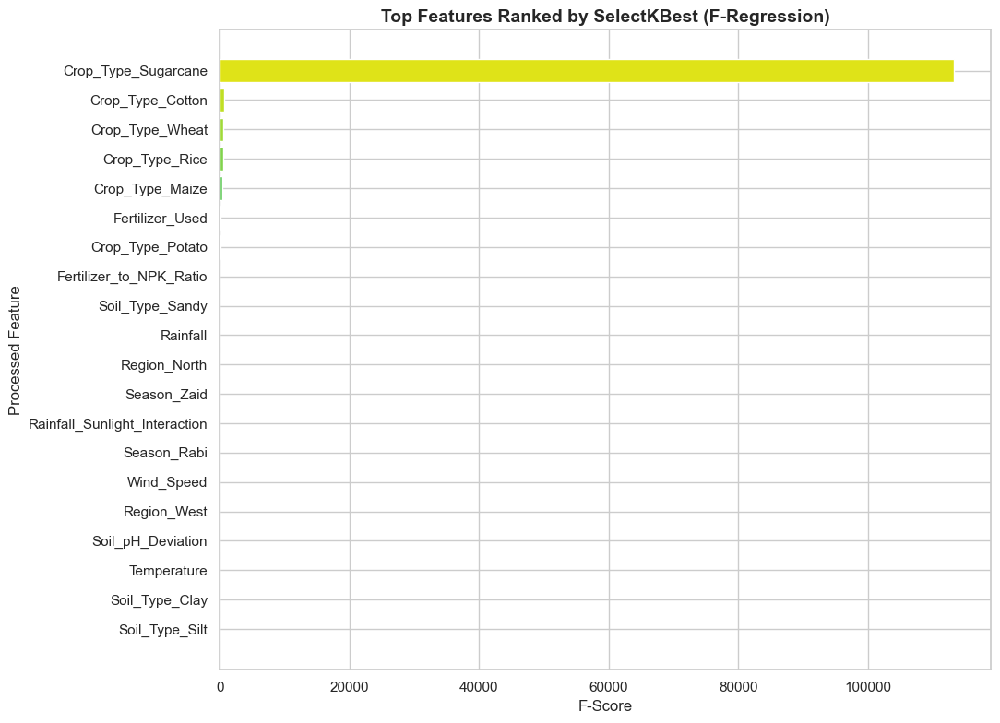

Ranking graph saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\SelectKBest_Top20_Features.jpg


In [50]:

top_n = min(20, len(selectkbest_results))
top_features = selectkbest_results.head(top_n).sort_values(
    "F_Score", ascending=True
)

plt.figure(figsize=(11, 8))
colors = sns.color_palette("viridis", n_colors=top_n)

plt.barh(
    top_features["Feature"],
    top_features["F_Score"],
    color=colors,
    edgecolor="white"
)

plt.title(
    "Top Features Ranked by SelectKBest (F-Regression)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("F-Score")
plt.ylabel("Processed Feature")
plt.tight_layout()

ranking_plot_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "SelectKBest_Top20_Features.jpg"
)

plt.savefig(ranking_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Ranking graph saved to:", ranking_plot_path)


In [51]:

available_features = len(selectkbest_results)
k_values = sorted(set(
    k for k in [10, 15, 20]
    if k <= available_features
))

if available_features < 10:
    k_values = [available_features]

candidate_subsets = {}

for k in k_values:
    selector = SelectKBest(score_func=f_regression, k=k)
    selector.fit(X_train_processed_df, y_train)

    selected_names = X_train_processed_df.columns[
        selector.get_support()
    ].tolist()

    candidate_subsets[k] = selected_names

    subset_path = os.path.join(
        FEATURE_SELECTION_DIR,
        f"SelectKBest_Top{k}_Features.csv"
    )

    pd.DataFrame({
        "Selected_Feature": selected_names
    }).to_csv(subset_path, index=False)

    print(f"\nTop {k} features:")
    for rank, name in enumerate(selected_names, start=1):
        print(f"{rank}. {name}")

print("\nCandidate feature sets saved in:", FEATURE_SELECTION_DIR)
print("\nStep 8.4 completed successfully!")



Top 10 features:
1. Rainfall
2. Fertilizer_Used
3. Fertilizer_to_NPK_Ratio
4. Soil_Type_Sandy
5. Crop_Type_Cotton
6. Crop_Type_Maize
7. Crop_Type_Potato
8. Crop_Type_Rice
9. Crop_Type_Sugarcane
10. Crop_Type_Wheat

Top 15 features:
1. Rainfall
2. Wind_Speed
3. Fertilizer_Used
4. Rainfall_Sunlight_Interaction
5. Fertilizer_to_NPK_Ratio
6. Soil_Type_Sandy
7. Region_North
8. Season_Rabi
9. Season_Zaid
10. Crop_Type_Cotton
11. Crop_Type_Maize
12. Crop_Type_Potato
13. Crop_Type_Rice
14. Crop_Type_Sugarcane
15. Crop_Type_Wheat

Top 20 features:
1. Temperature
2. Rainfall
3. Wind_Speed
4. Fertilizer_Used
5. Soil_pH_Deviation
6. Rainfall_Sunlight_Interaction
7. Fertilizer_to_NPK_Ratio
8. Soil_Type_Clay
9. Soil_Type_Sandy
10. Soil_Type_Silt
11. Region_North
12. Region_West
13. Season_Rabi
14. Season_Zaid
15. Crop_Type_Cotton
16. Crop_Type_Maize
17. Crop_Type_Potato
18. Crop_Type_Rice
19. Crop_Type_Sugarcane
20. Crop_Type_Wheat

Candidate feature sets saved in: C:\Users\umash\OneDrive\Desktop\s

In [52]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor

# Output directory
FEATURE_SELECTION_DIR = os.path.join(
    PROJECT_DIR, "Feature_Selection"
)
os.makedirs(FEATURE_SELECTION_DIR, exist_ok=True)

# Select a candidate number of features
n_features_to_select = min(15, X_train_processed_df.shape[1])

# Random Forest used as the feature-ranking estimator
rfe_estimator = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Run RFE on the processed training data only
rfe_selector = RFE(
    estimator=rfe_estimator,
    n_features_to_select=n_features_to_select,
    step=2
)

rfe_selector.fit(X_train_processed_df, y_train)

# Build a ranking table
rfe_results = pd.DataFrame({
    "Feature": X_train_processed_df.columns,
    "Selected": rfe_selector.support_,
    "RFE_Rank": rfe_selector.ranking_
}).sort_values(
    ["Selected", "RFE_Rank", "Feature"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("=" * 65)
print("STEP 8.5.1: RECURSIVE FEATURE ELIMINATION")
print("=" * 65)

print("Total processed features:", X_train_processed_df.shape[1])
print("Requested selected features:", n_features_to_select)
print("Actual selected features:", int(rfe_selector.support_.sum()))

print("\nRFE ranking:")
display(rfe_results)

# Save the full ranking
rfe_ranking_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "RFE_RandomForest_Ranking.csv"
)
rfe_results.to_csv(rfe_ranking_path, index=False)

# Save selected feature names
rfe_selected_features = X_train_processed_df.columns[
    rfe_selector.support_
].tolist()

rfe_selected_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "RFE_Selected_Features.csv"
)

pd.DataFrame({
    "Selected_Feature": rfe_selected_features
}).to_csv(rfe_selected_path, index=False)

print("\nFull RFE ranking saved to:", rfe_ranking_path)
print("Selected features saved to:", rfe_selected_path)

print("\nSelected features:")
for i, feature in enumerate(rfe_selected_features, start=1):
    print(f"{i}. {feature}")


STEP 8.5.1: RECURSIVE FEATURE ELIMINATION
Total processed features: 42
Requested selected features: 15
Actual selected features: 15

RFE ranking:


,Feature,Selected,RFE_Rank
0,Crop_Type_Cotton,True,1
1,Crop_Type_Potato,True,1
2,Crop_Type_Sugarcane,True,1
3,Crop_Type_Wheat,True,1
4,Fertilizer_Used,True,1
5,K,True,1
6,Moisture_Humidity_Interaction,True,1
7,N,True,1
8,NPK_Total,True,1
9,Rainfall,True,1



Full RFE ranking saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\RFE_RandomForest_Ranking.csv
Selected features saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\RFE_Selected_Features.csv

Selected features:
1. N
2. K
3. Soil_pH
4. Soil_Moisture
5. Rainfall
6. Wind_Speed
7. Fertilizer_Used
8. NPK_Total
9. Soil_pH_Deviation
10. Moisture_Humidity_Interaction
11. Rainfall_Sunlight_Interaction
12. Crop_Type_Cotton
13. Crop_Type_Potato
14. Crop_Type_Sugarcane
15. Crop_Type_Wheat


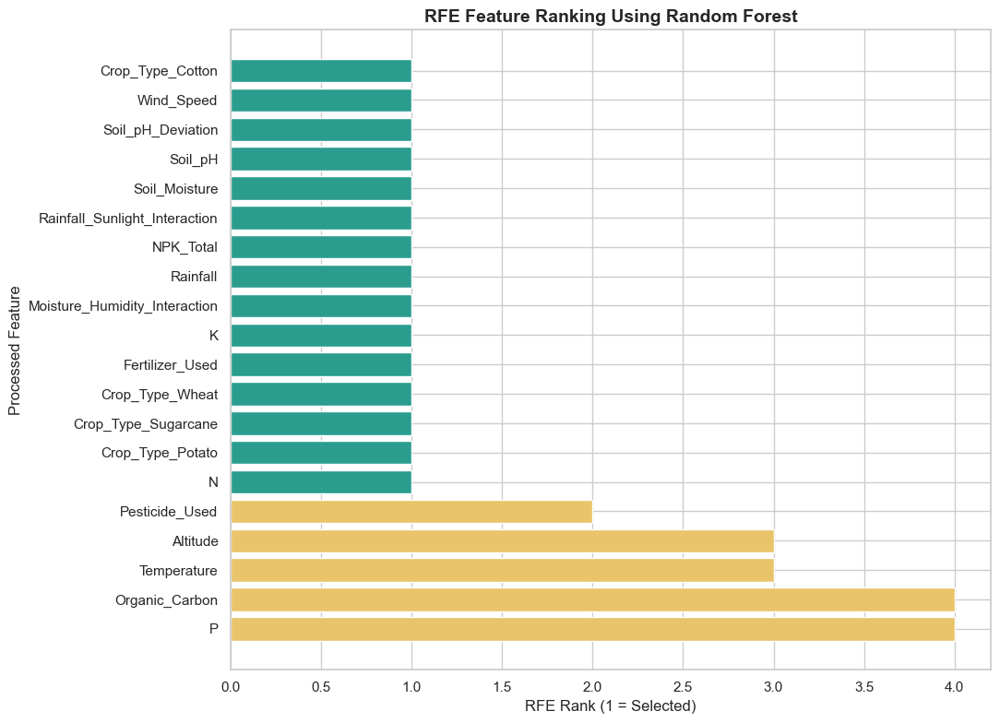

RFE graph saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\RFE_RandomForest_Feature_Ranking.jpg

Step 8.5 completed successfully!


In [53]:

# Plot the top 20 features according to RFE ranking
rfe_plot_df = rfe_results.sort_values(
    ["RFE_Rank", "Feature"]
).head(min(20, len(rfe_results))).copy()

rfe_plot_df = rfe_plot_df.sort_values(
    "RFE_Rank", ascending=True
)

plt.figure(figsize=(11, 8))

bar_colors = [
    "#2A9D8F" if selected else "#E9C46A"
    for selected in rfe_plot_df["Selected"]
]

plt.barh(
    rfe_plot_df["Feature"],
    rfe_plot_df["RFE_Rank"],
    color=bar_colors,
    edgecolor="white"
)

plt.gca().invert_yaxis()
plt.title(
    "RFE Feature Ranking Using Random Forest",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("RFE Rank (1 = Selected)")
plt.ylabel("Processed Feature")

plt.tight_layout()

rfe_plot_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "RFE_RandomForest_Feature_Ranking.jpg"
)

plt.savefig(rfe_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("RFE graph saved to:", rfe_plot_path)
print("\nStep 8.5 completed successfully!")


In [54]:

# Compare the top 15 SelectKBest features with RFE-selected features
selectkbest_top15 = set(
    selectkbest_results.head(
        min(15, len(selectkbest_results))
    )["Feature"]
)

rfe_selected_set = set(rfe_selected_features)

comparison_df = pd.DataFrame({
    "Feature": X_train_processed_df.columns,
    "Selected_by_SelectKBest_Top15": [
        feature in selectkbest_top15
        for feature in X_train_processed_df.columns
    ],
    "Selected_by_RFE": [
        feature in rfe_selected_set
        for feature in X_train_processed_df.columns
    ]
})

comparison_df["Selected_by_Both"] = (
    comparison_df["Selected_by_SelectKBest_Top15"]
    & comparison_df["Selected_by_RFE"]
)

comparison_df["Selection_Category"] = comparison_df.apply(
    lambda row: (
        "Both methods"
        if row["Selected_by_Both"]
        else "SelectKBest only"
        if row["Selected_by_SelectKBest_Top15"]
        else "RFE only"
        if row["Selected_by_RFE"]
        else "Neither"
    ),
    axis=1
)

comparison_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "SelectKBest_RFE_Comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("=" * 65)
print("STEP 8.6: FEATURE SELECTION METHOD COMPARISON")
print("=" * 65)

display(comparison_df)

print("\nSelectKBest top-15 count:", len(selectkbest_top15))
print("RFE selected count:", len(rfe_selected_set))
print("Selected by both:", len(selectkbest_top15 & rfe_selected_set))
print("Comparison saved to:", comparison_path)


STEP 8.6: FEATURE SELECTION METHOD COMPARISON


,Feature,Selected_by_SelectKBest_Top15,Selected_by_RFE,Selected_by_Both,Selection_Category
0,N,False,True,False,RFE only
1,P,False,False,False,Neither
2,K,False,True,False,RFE only
3,Soil_pH,False,True,False,RFE only
4,Soil_Moisture,False,True,False,RFE only
5,Organic_Carbon,False,False,False,Neither
6,Temperature,False,False,False,Neither
7,Humidity,False,False,False,Neither
8,Rainfall,True,True,True,Both methods
9,Sunlight_Hours,False,False,False,Neither



SelectKBest top-15 count: 15
RFE selected count: 15
Selected by both: 8
Comparison saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\SelectKBest_RFE_Comparison.csv


In [55]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate

FEATURE_SELECTION_DIR = os.path.join(
    PROJECT_DIR, "Feature_Selection"
)
os.makedirs(FEATURE_SELECTION_DIR, exist_ok=True)

# Five-fold cross-validation on training data only
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Candidate subsets
candidate_configs = [
    ("All Features", "all", None),
    ("SelectKBest Top 10", "kbest", 10),
    ("SelectKBest Top 15", "kbest", 15),
    ("SelectKBest Top 20", "kbest", 20),
    ("RFE Top 10", "rfe", 10),
    ("RFE Top 15", "rfe", 15),
    ("RFE Top 20", "rfe", 20)
]

# Determine transformed feature count without fitting on validation folds.
# This is only used to avoid requesting more features than exist.
preprocessor_for_count = clone(preprocessor)
preprocessor_for_count.fit(X_train, y_train)
transformed_count = len(
    preprocessor_for_count.get_feature_names_out()
)

print("Number of transformed predictors:", transformed_count)

results = []

for candidate_name, method, k in candidate_configs:

    # Skip any candidate larger than the available feature count
    if k is not None and k > transformed_count:
        print(f"Skipping {candidate_name}: only {transformed_count} features available.")
        continue

    steps = [
        ("preprocessor", clone(preprocessor))
    ]

    if method == "kbest":
        steps.append((
            "feature_selector",
            SelectKBest(score_func=f_regression, k=k)
        ))

    elif method == "rfe":
        rfe_model = RandomForestRegressor(
            n_estimators=50,
            random_state=42,
            n_jobs=1
        )

        steps.append((
            "feature_selector",
            RFE(
                estimator=rfe_model,
                n_features_to_select=k,
                step=5
            )
        ))

    # Baseline and selected subsets use the same evaluation model
    evaluation_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    )

    steps.append(("model", evaluation_model))
    candidate_pipeline = Pipeline(steps)

    scores = cross_validate(
        candidate_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1,
        return_train_score=False
    )

    rmse_values = -scores["test_rmse"]
    r2_values = scores["test_r2"]

    results.append({
        "Candidate": candidate_name,
        "Selection_Method": method,
        "Requested_Features": (
            transformed_count if k is None else k
        ),
        "Mean_CV_RMSE": rmse_values.mean(),
        "Std_CV_RMSE": rmse_values.std(),
        "Mean_CV_R2": r2_values.mean(),
        "Std_CV_R2": r2_values.std()
    })

    print(
        f"{candidate_name}: "
        f"RMSE = {rmse_values.mean():.4f} "
        f"(± {rmse_values.std():.4f}), "
        f"R² = {r2_values.mean():.4f}"
    )

cv_results_df = pd.DataFrame(results)

# Lower RMSE is the primary ranking criterion
cv_results_df = cv_results_df.sort_values(
    "Mean_CV_RMSE",
    ascending=True
).reset_index(drop=True)

cv_results_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "Feature_Subset_Cross_Validation_Results.csv"
)

cv_results_df.to_csv(cv_results_path, index=False)

print("\nCROSS-VALIDATION COMPARISON")
display(cv_results_df.round(4))

print("\nResults saved to:", cv_results_path)


Number of transformed predictors: 42
All Features: RMSE = 1.1345 (± 0.0181), R² = 0.9978
SelectKBest Top 10: RMSE = 1.2960 (± 0.0131), R² = 0.9971
SelectKBest Top 15: RMSE = 1.2537 (± 0.0264), R² = 0.9973
SelectKBest Top 20: RMSE = 1.2122 (± 0.0289), R² = 0.9974
RFE Top 10: RMSE = 1.1735 (± 0.0207), R² = 0.9976
RFE Top 15: RMSE = 1.1353 (± 0.0207), R² = 0.9977
RFE Top 20: RMSE = 1.1359 (± 0.0209), R² = 0.9977

CROSS-VALIDATION COMPARISON


,Candidate,Selection_Method,Requested_Features,Mean_CV_RMSE,Std_CV_RMSE,Mean_CV_R2,Std_CV_R2
0,All Features,all,42,1.1345,0.0181,0.9978,0.0001
1,RFE Top 15,rfe,15,1.1353,0.0207,0.9977,0.0001
2,RFE Top 20,rfe,20,1.1359,0.0209,0.9977,0.0001
3,RFE Top 10,rfe,10,1.1735,0.0207,0.9976,0.0001
4,SelectKBest Top 20,kbest,20,1.2122,0.0289,0.9974,0.0002
5,SelectKBest Top 15,kbest,15,1.2537,0.0264,0.9973,0.0002
6,SelectKBest Top 10,kbest,10,1.2960,0.0131,0.9971,0.0001



Results saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\Feature_Subset_Cross_Validation_Results.csv


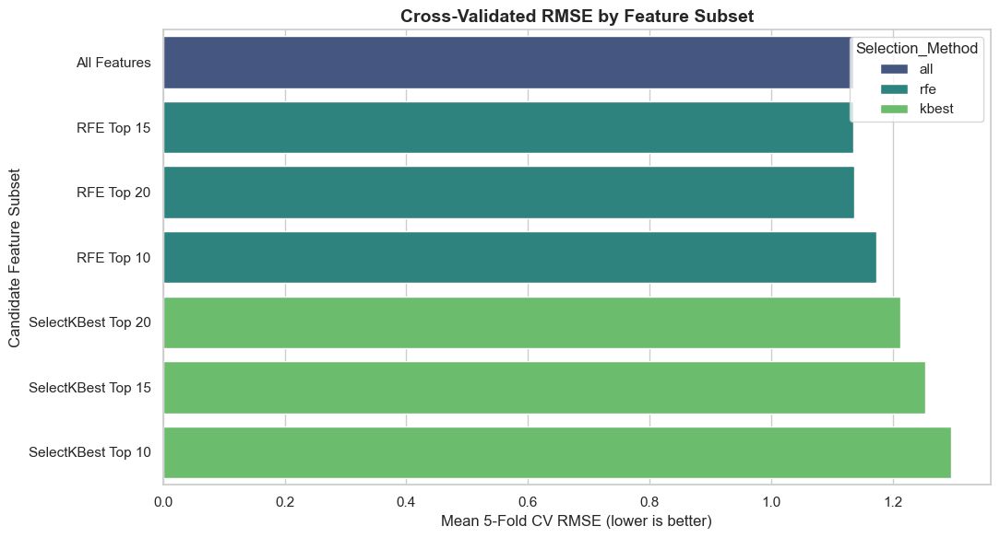

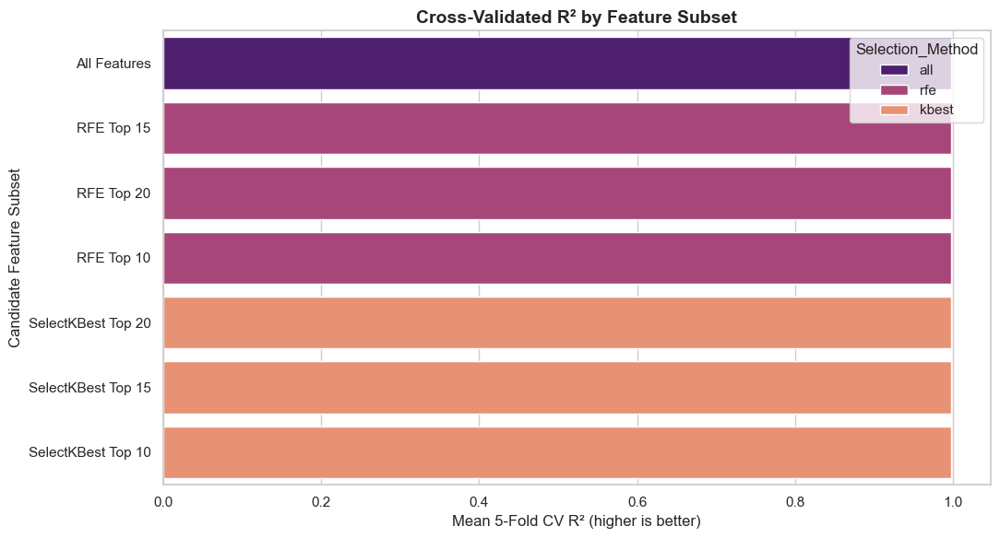

RMSE graph saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\Feature_Subset_CV_RMSE.jpg
R² graph saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\Feature_Subset_CV_R2.jpg


In [56]:

# RMSE comparison
plot_df = cv_results_df.sort_values(
    "Mean_CV_RMSE", ascending=True
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=plot_df,
    x="Mean_CV_RMSE",
    y="Candidate",
    hue="Selection_Method",
    palette="viridis",
    errorbar=None
)

plt.title(
    "Cross-Validated RMSE by Feature Subset",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Mean 5-Fold CV RMSE (lower is better)")
plt.ylabel("Candidate Feature Subset")
plt.tight_layout()

rmse_plot_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "Feature_Subset_CV_RMSE.jpg"
)
plt.savefig(rmse_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# R² comparison
plot_df_r2 = cv_results_df.sort_values(
    "Mean_CV_R2", ascending=False
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=plot_df_r2,
    x="Mean_CV_R2",
    y="Candidate",
    hue="Selection_Method",
    palette="magma",
    errorbar=None
)

plt.title(
    "Cross-Validated R² by Feature Subset",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Mean 5-Fold CV R² (higher is better)")
plt.ylabel("Candidate Feature Subset")
plt.tight_layout()

r2_plot_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "Feature_Subset_CV_R2.jpg"
)
plt.savefig(r2_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("RMSE graph saved to:", rmse_plot_path)
print("R² graph saved to:", r2_plot_path)


In [57]:

best_candidate = cv_results_df.iloc[0]

print("=" * 65)
print("LEADING FEATURE SUBSET")
print("=" * 65)

print("Candidate:", best_candidate["Candidate"])
print("Selection method:", best_candidate["Selection_Method"])
print("Requested feature count:", best_candidate["Requested_Features"])
print("Mean CV RMSE:", round(best_candidate["Mean_CV_RMSE"], 4))
print("Mean CV R²:", round(best_candidate["Mean_CV_R2"], 4))

print(
    "\nThis is the leading candidate by mean cross-validated RMSE. "
    "It is not yet the final model selection."
)
print(
    "We will also consider variability, model simplicity, and "
    "whether the performance difference is meaningful."
)


LEADING FEATURE SUBSET
Candidate: All Features
Selection method: all
Requested feature count: 42
Mean CV RMSE: 1.1345
Mean CV R²: 0.9978

This is the leading candidate by mean cross-validated RMSE. It is not yet the final model selection.
We will also consider variability, model simplicity, and whether the performance difference is meaningful.


In [58]:

import os
import numpy as np
import pandas as pd

FEATURE_SELECTION_DIR = os.path.join(
    PROJECT_DIR, "Feature_Selection"
)
os.makedirs(FEATURE_SELECTION_DIR, exist_ok=True)

# Display the complete cross-validation comparison
print("=" * 70)
print("STEP 8.8: FINAL FEATURE-SELECTION DECISION")
print("=" * 70)

display(cv_results_df.round(4))

# Identify the candidate with the lowest mean CV RMSE
best_candidate = cv_results_df.sort_values(
    "Mean_CV_RMSE", ascending=True
).iloc[0]

print("\nLeading candidate:", best_candidate["Candidate"])
print("Mean CV RMSE:", round(best_candidate["Mean_CV_RMSE"], 4))
print("Mean CV R²:", round(best_candidate["Mean_CV_R2"], 4))

# Use all features if that is the leading candidate
if best_candidate["Selection_Method"] == "all":
    final_feature_names = X_train_processed_df.columns.tolist()
    final_selection_method = "All processed features retained"
elif best_candidate["Selection_Method"] == "kbest":
    final_k = int(best_candidate["Requested_Features"])
    final_selector = SelectKBest(
        score_func=f_regression, k=final_k
    )
    final_selector.fit(X_train_processed_df, y_train)
    final_feature_names = X_train_processed_df.columns[
        final_selector.get_support()
    ].tolist()
    final_selection_method = f"SelectKBest, k={final_k}"
elif best_candidate["Selection_Method"] == "rfe":
    final_k = int(best_candidate["Requested_Features"])
    final_selector = RFE(
        estimator=RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),
        n_features_to_select=final_k,
        step=2
    )
    final_selector.fit(X_train_processed_df, y_train)
    final_feature_names = X_train_processed_df.columns[
        final_selector.support_
    ].tolist()
    final_selection_method = f"RFE, k={final_k}"
else:
    raise ValueError("Unknown feature-selection method.")

print("\nChosen strategy:", final_selection_method)
print("Number of final predictors:", len(final_feature_names))

# Save the selected feature names
final_features_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "Final_Selected_Features.csv"
)

pd.DataFrame({
    "Feature_Name": final_feature_names
}).to_csv(final_features_path, index=False)

# Save a concise decision record
decision_record = pd.DataFrame([{
    "Chosen_Candidate": best_candidate["Candidate"],
    "Selection_Method": final_selection_method,
    "Number_of_Processed_Features": len(final_feature_names),
    "Mean_CV_RMSE": best_candidate["Mean_CV_RMSE"],
    "Std_CV_RMSE": best_candidate["Std_CV_RMSE"],
    "Mean_CV_R2": best_candidate["Mean_CV_R2"],
    "Std_CV_R2": best_candidate["Std_CV_R2"],
    "Decision_Status": "Provisional; verify on held-out test data"
}])

decision_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "Feature_Selection_Decision.csv"
)
decision_record.to_csv(decision_path, index=False)

print("\nFeature list saved to:", final_features_path)
print("Decision record saved to:", decision_path)

print("\nStep 8.8 completed!")


STEP 8.8: FINAL FEATURE-SELECTION DECISION


,Candidate,Selection_Method,Requested_Features,Mean_CV_RMSE,Std_CV_RMSE,Mean_CV_R2,Std_CV_R2
0,All Features,all,42,1.1345,0.0181,0.9978,0.0001
1,RFE Top 15,rfe,15,1.1353,0.0207,0.9977,0.0001
2,RFE Top 20,rfe,20,1.1359,0.0209,0.9977,0.0001
3,RFE Top 10,rfe,10,1.1735,0.0207,0.9976,0.0001
4,SelectKBest Top 20,kbest,20,1.2122,0.0289,0.9974,0.0002
5,SelectKBest Top 15,kbest,15,1.2537,0.0264,0.9973,0.0002
6,SelectKBest Top 10,kbest,10,1.2960,0.0131,0.9971,0.0001



Leading candidate: All Features
Mean CV RMSE: 1.1345
Mean CV R²: 0.9978

Chosen strategy: All processed features retained
Number of final predictors: 42

Feature list saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\Final_Selected_Features.csv
Decision record saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection\Feature_Selection_Decision.csv

Step 8.8 completed!


In [59]:

# Select identical columns from the processed train/test matrices
X_train_final = X_train_processed_df[final_feature_names].copy()
X_test_final = X_test_processed_df[final_feature_names].copy()

# Save the final matrices for reproducibility
X_train_final_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "X_train_final.csv"
)
X_test_final_path = os.path.join(
    FEATURE_SELECTION_DIR,
    "X_test_final.csv"
)

X_train_final.to_csv(X_train_final_path, index=False)
X_test_final.to_csv(X_test_final_path, index=False)

print("=" * 65)
print("FINAL MODEL-READY DATA")
print("=" * 65)

print("X_train_final shape:", X_train_final.shape)
print("X_test_final shape:", X_test_final.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining missing values:",
      int(X_train_final.isna().sum().sum()))
print("Testing missing values:",
      int(X_test_final.isna().sum().sum()))

print("\nTraining matrix finite:",
      bool(np.isfinite(X_train_final.to_numpy()).all()))
print("Testing matrix finite:",
      bool(np.isfinite(X_test_final.to_numpy()).all()))

assert list(X_train_final.columns) == list(X_test_final.columns)
assert X_train_final.index.equals(y_train.index)
assert X_test_final.index.equals(y_test.index)
assert X_train_final.shape[1] == X_test_final.shape[1]
assert np.isfinite(X_train_final.to_numpy()).all()
assert np.isfinite(X_test_final.to_numpy()).all()

print("\nStep 8.8.2 completed successfully!")
print("Final matrices saved in:", FEATURE_SELECTION_DIR)


FINAL MODEL-READY DATA
X_train_final shape: (8000, 42)
X_test_final shape: (2000, 42)
y_train shape: (8000,)
y_test shape: (2000,)

Training missing values: 0
Testing missing values: 0

Training matrix finite: True
Testing matrix finite: True

Step 8.8.2 completed successfully!
Final matrices saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Feature_Selection


In [60]:

print("=" * 70)
print("FEATURE SELECTION SUMMARY")
print("=" * 70)

print("Original dataset:", df.shape)
print("Feature-engineered dataset:", df_feature_engineered.shape)
print("Training samples:", len(X_train_final))
print("Testing samples:", len(X_test_final))
print("Final processed predictors:", len(final_feature_names))
print("Selected strategy:", final_selection_method)

print("\nDecision:")
if final_selection_method == "All processed features retained":
    print(
        "All processed predictors are retained because the all-feature "
        "candidate led the tested cross-validation comparison."
    )
else:
    print(
        "The leading candidate's feature-selection method is retained "
        "for the next model-development stage."
    )

print(
    "\nImportant: the final test set has not been used to choose features. "
    "We will evaluate it only after fitting the models."
)


FEATURE SELECTION SUMMARY
Original dataset: (10000, 20)
Feature-engineered dataset: (10000, 26)
Training samples: 8000
Testing samples: 2000
Final processed predictors: 42
Selected strategy: All processed features retained

Decision:
All processed predictors are retained because the all-feature candidate led the tested cross-validation comparison.

Important: the final test set has not been used to choose features. We will evaluate it only after fitting the models.


In [61]:

import os
import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error
)

# Create output directories in the project root
PROJECT_DIR = os.path.dirname(os.path.abspath(EDA_DIR))

MODEL_DIR = os.path.join(PROJECT_DIR, "Models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "Model_Results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("=" * 65)
print("STEP 9.1: LINEAR REGRESSION BASELINE")
print("=" * 65)

# 1. Initialize the model
linear_model = LinearRegression()

# 2. Train using training data only
linear_model.fit(X_train_final, y_train)

# 3. Generate predictions
y_train_pred_lr = linear_model.predict(X_train_final)
y_test_pred_lr = linear_model.predict(X_test_final)

# 4. Calculate evaluation metrics on the held-out test set
lr_mae = mean_absolute_error(y_test, y_test_pred_lr)
lr_mse = mean_squared_error(y_test, y_test_pred_lr)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, y_test_pred_lr)
lr_median_ae = median_absolute_error(y_test, y_test_pred_lr)
lr_explained_variance = explained_variance_score(
    y_test, y_test_pred_lr
)
lr_max_error = max_error(y_test, y_test_pred_lr)

# 5. Display results
lr_results = {
    "Model": "Linear Regression",
    "MAE": lr_mae,
    "MSE": lr_mse,
    "RMSE": lr_rmse,
    "R2": lr_r2,
    "Median_AE": lr_median_ae,
    "Explained_Variance": lr_explained_variance,
    "Max_Error": lr_max_error
}

lr_results_df = pd.DataFrame([lr_results])

display(lr_results_df.round(4))

# 6. Save the trained model
lr_model_path = os.path.join(
    MODEL_DIR,
    "linear_regression_model.joblib"
)
joblib.dump(linear_model, lr_model_path)

# 7. Save the test predictions alongside actual yields
lr_predictions_df = pd.DataFrame({
    "Actual_Crop_Yield": y_test,
    "Predicted_Crop_Yield": y_test_pred_lr,
    "Prediction_Error": y_test - y_test_pred_lr
})

lr_predictions_path = os.path.join(
    RESULTS_DIR,
    "Linear_Regression_Test_Predictions.csv"
)
lr_predictions_df.to_csv(lr_predictions_path, index=False)

# 8. Save metrics
lr_metrics_path = os.path.join(
    RESULTS_DIR,
    "Linear_Regression_Metrics.csv"
)
lr_results_df.to_csv(lr_metrics_path, index=False)

print("\nLinear Regression training completed!")
print("Model saved:", lr_model_path)
print("Test predictions saved:", lr_predictions_path)
print("Evaluation metrics saved:", lr_metrics_path)

print("\nTraining samples:", len(X_train_final))
print("Testing samples:", len(X_test_final))
print("Input features:", X_train_final.shape[1])


STEP 9.1: LINEAR REGRESSION BASELINE


,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,Linear Regression,0.8161,1.0415,1.0205,0.9982,0.6937,0.9982,3.4767



Linear Regression training completed!
Model saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Models\linear_regression_model.joblib
Test predictions saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Linear_Regression_Test_Predictions.csv
Evaluation metrics saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Linear_Regression_Metrics.csv

Training samples: 8000
Testing samples: 2000
Input features: 42


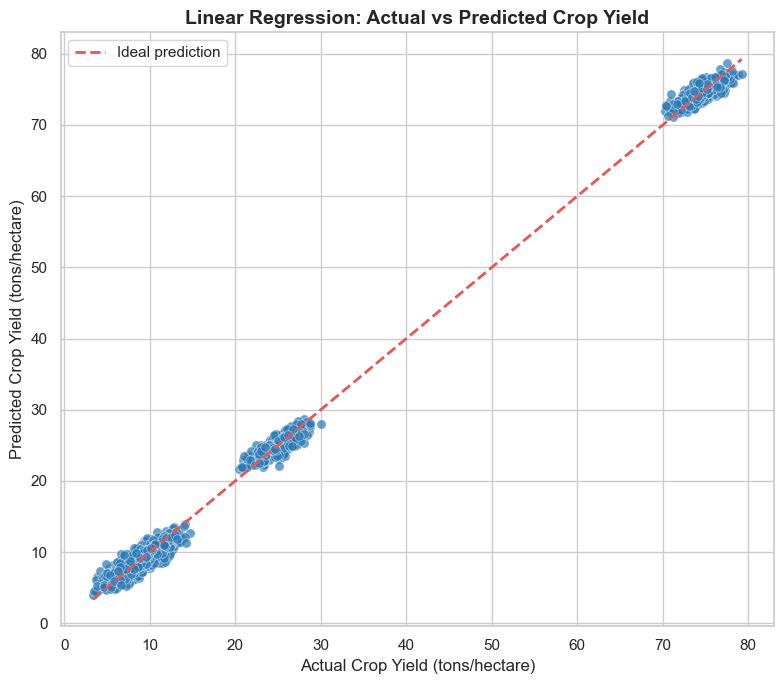

Graph saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Linear_Regression_Actual_vs_Predicted.jpg


In [62]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=y_test,
    y=y_test_pred_lr,
    color="#2878B5",
    alpha=0.7,
    s=45,
    edgecolor="white",
    linewidth=0.4
)

# Ideal prediction reference line
min_value = min(y_test.min(), y_test_pred_lr.min())
max_value = max(y_test.max(), y_test_pred_lr.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="#E45756",
    linewidth=2,
    label="Ideal prediction"
)

plt.title(
    "Linear Regression: Actual vs Predicted Crop Yield",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Actual Crop Yield (tons/hectare)")
plt.ylabel("Predicted Crop Yield (tons/hectare)")
plt.legend()
plt.tight_layout()

lr_plot_path = os.path.join(
    RESULTS_DIR,
    "Linear_Regression_Actual_vs_Predicted.jpg"
)

plt.savefig(lr_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Graph saved:", lr_plot_path)


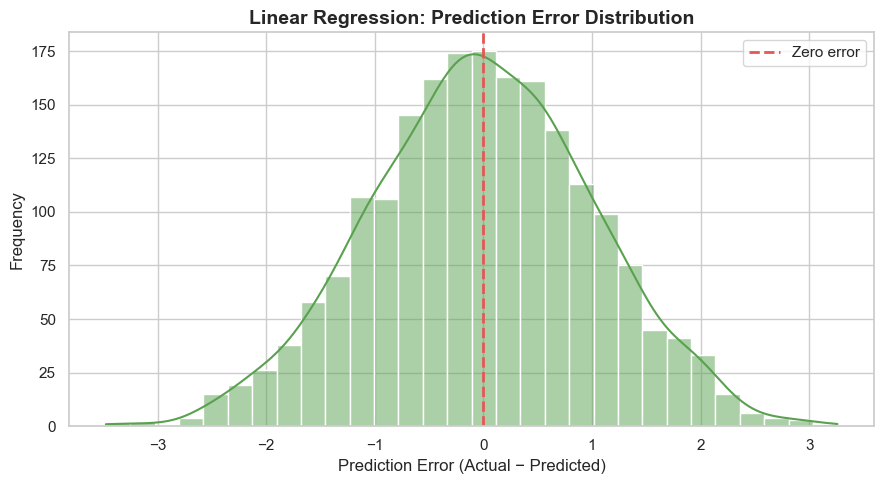

Error distribution graph saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Linear_Regression_Error_Distribution.jpg
Mean prediction error: -0.0135
Standard deviation of errors: 1.0204


In [63]:

# Calculate residuals: actual minus predicted
lr_residuals = y_test.to_numpy() - y_test_pred_lr

plt.figure(figsize=(9, 5))

sns.histplot(
    lr_residuals,
    bins=30,
    kde=True,
    color="#59A14F",
    edgecolor="white"
)

plt.axvline(
    0,
    color="#E45756",
    linestyle="--",
    linewidth=2,
    label="Zero error"
)

plt.title(
    "Linear Regression: Prediction Error Distribution",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Prediction Error (Actual − Predicted)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

lr_error_plot_path = os.path.join(
    RESULTS_DIR,
    "Linear_Regression_Error_Distribution.jpg"
)

plt.savefig(lr_error_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Error distribution graph saved:", lr_error_plot_path)
print("Mean prediction error:", round(lr_residuals.mean(), 4))
print("Standard deviation of errors:", round(lr_residuals.std(), 4))



Training Decision Tree...


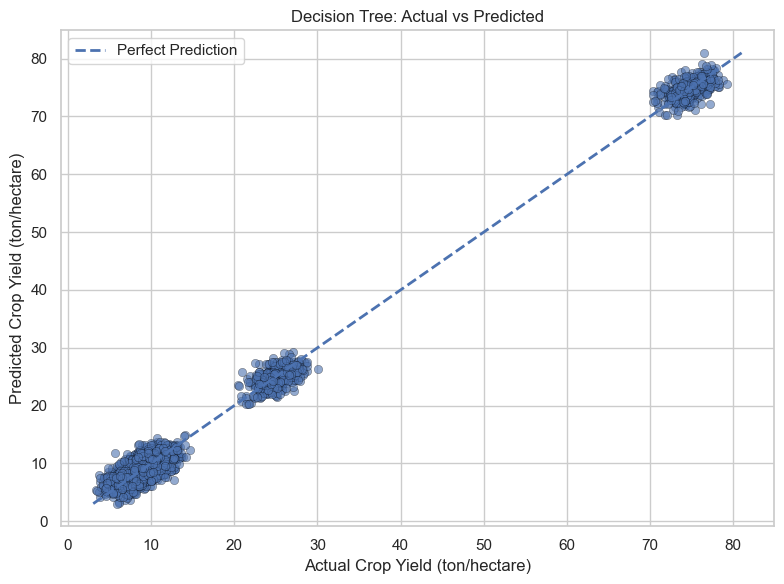

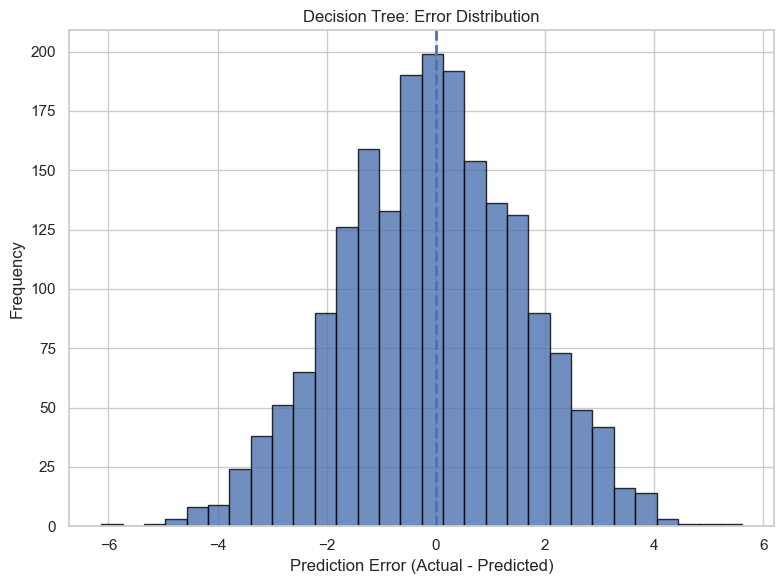

Decision_Tree completed.
Test RMSE: 1.6580
Test R²: 0.9953

Training Random Forest...


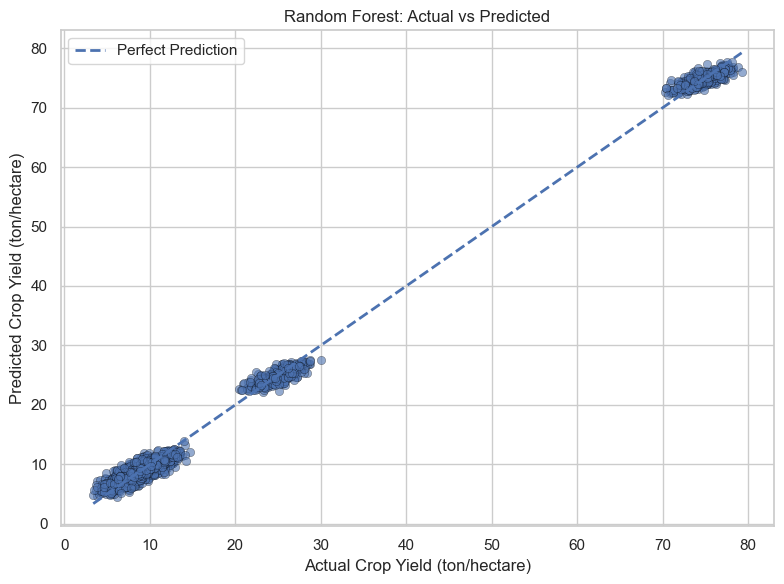

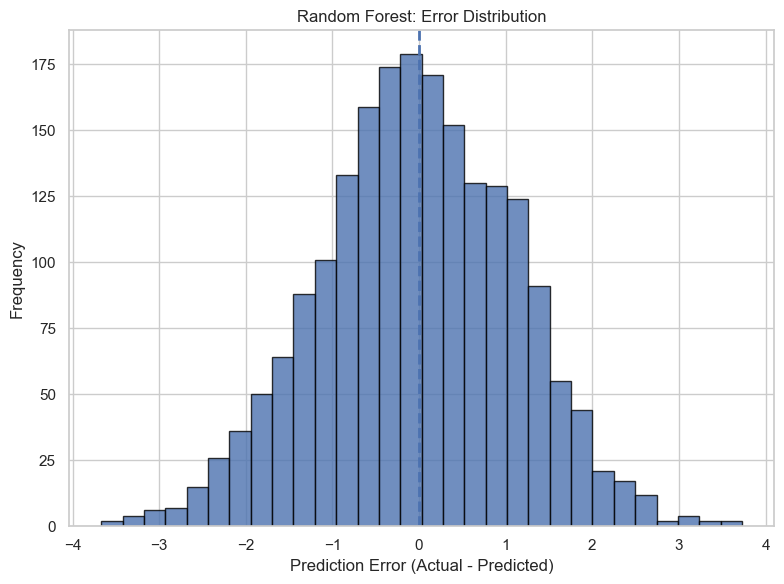

Random_Forest completed.
Test RMSE: 1.1243
Test R²: 0.9978

Training SVR...


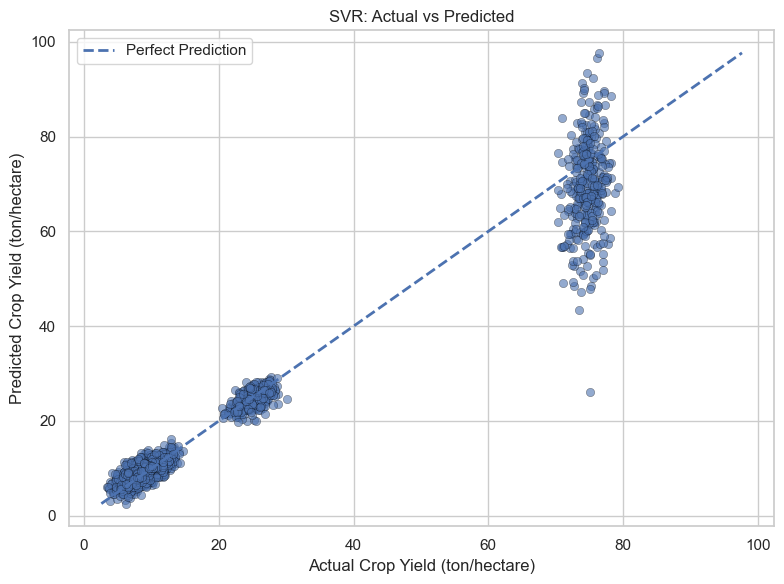

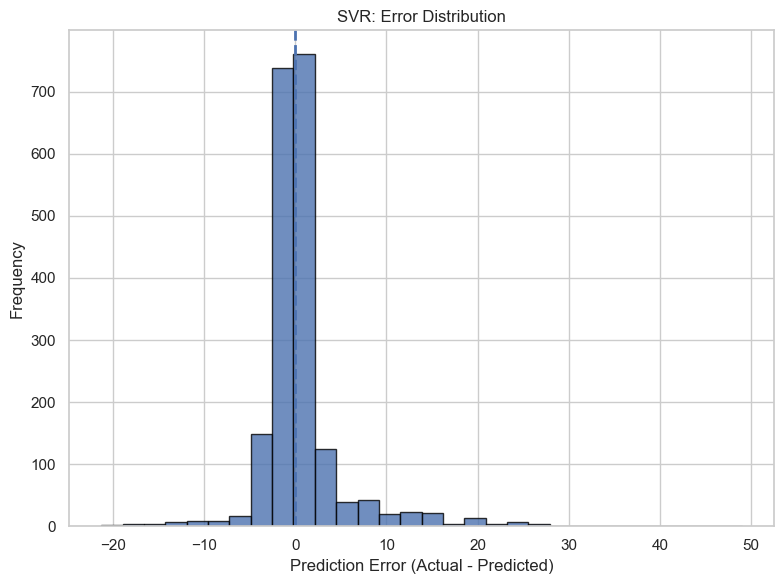

SVR completed.
Test RMSE: 4.6261
Test R²: 0.9633

Training KNN...


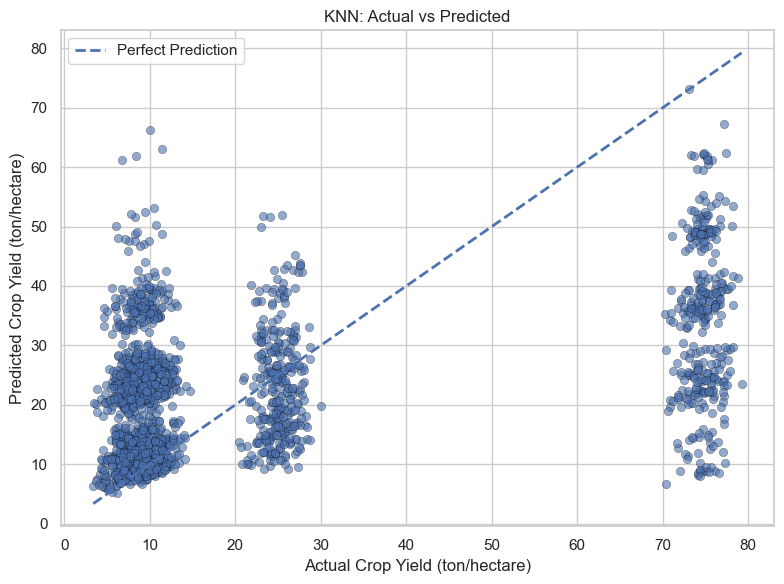

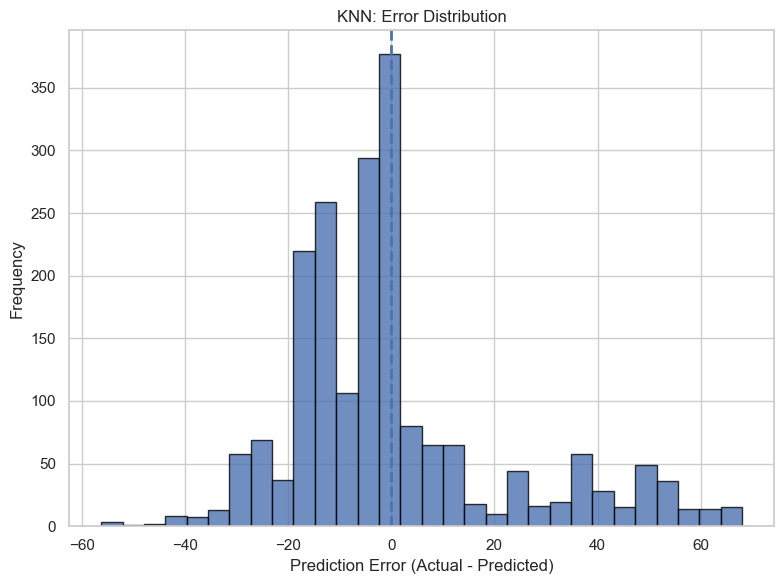

KNN completed.
Test RMSE: 21.3263
Test R²: 0.2197

CLASSICAL MACHINE LEARNING MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,Random Forest,0.8982,1.2640,1.1243,0.9978,0.7637,0.9978,3.7279
1,Decision Tree,1.3260,2.7489,1.6580,0.9953,1.1600,0.9953,6.1300
2,SVR,2.4604,21.4011,4.6261,0.9633,1.2520,0.9640,48.9792
3,KNN,15.0996,454.8113,21.3263,0.2197,11.6960,0.2198,67.9764



Metrics saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Classical_ML_Models_Metrics.csv
Models saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Models
Plots and predictions saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results


In [64]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error
)

# --------------------------------------------------
# 1. Create output directories
# --------------------------------------------------
MODEL_DIR = os.path.join(PROJECT_DIR, "Models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "Model_Results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# --------------------------------------------------
# 2. Define candidate models
# --------------------------------------------------
models = {
    "Decision_Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random_Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVR": SVR(
        kernel="rbf",
        C=10,
        epsilon=0.1
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    )
}

# --------------------------------------------------
# 3. Evaluate each model
# --------------------------------------------------
results = []

for model_name, model in models.items():

    print(f"\nTraining {model_name.replace('_', ' ')}...")

    # Train
    model.fit(X_train_final, y_train)

    # Predict
    y_pred = model.predict(X_test_final)

    # Calculate metrics
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    metrics = {
        "Model": model_name.replace("_", " "),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2_score(y_test, y_pred),
        "Median_AE": median_absolute_error(y_test, y_pred),
        "Explained_Variance": explained_variance_score(
            y_test, y_pred
        ),
        "Max_Error": max_error(y_test, y_pred)
    }

    results.append(metrics)

    # Save trained model
    model_path = os.path.join(
        MODEL_DIR, f"{model_name.lower()}_model.joblib"
    )
    joblib.dump(model, model_path)

    # Save test predictions
    prediction_df = pd.DataFrame({
        "Actual_Crop_Yield": np.asarray(y_test),
        "Predicted_Crop_Yield": y_pred,
        "Prediction_Error": np.asarray(y_test) - y_pred
    })

    prediction_path = os.path.join(
        RESULTS_DIR,
        f"{model_name.lower()}_test_predictions.csv"
    )
    prediction_df.to_csv(prediction_path, index=False)

    # ----------------------------------------------
    # 4. Actual vs Predicted plot
    # ----------------------------------------------
    plt.figure(figsize=(8, 6))

    plt.scatter(
        y_test, y_pred,
        alpha=0.6,
        edgecolors="black",
        linewidths=0.3
    )

    min_value = min(np.min(y_test), np.min(y_pred))
    max_value = max(np.max(y_test), np.max(y_pred))

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--",
        linewidth=2,
        label="Perfect Prediction"
    )

    plt.xlabel("Actual Crop Yield (ton/hectare)")
    plt.ylabel("Predicted Crop Yield (ton/hectare)")
    plt.title(f"{model_name.replace('_', ' ')}: Actual vs Predicted")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            RESULTS_DIR,
            f"{model_name.lower()}_actual_vs_predicted.jpg"
        ),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # ----------------------------------------------
    # 5. Prediction error distribution
    # ----------------------------------------------
    errors = np.asarray(y_test) - y_pred

    plt.figure(figsize=(8, 6))
    plt.hist(errors, bins=30, edgecolor="black", alpha=0.8)
    plt.axvline(0, linestyle="--", linewidth=2)

    plt.xlabel("Prediction Error (Actual - Predicted)")
    plt.ylabel("Frequency")
    plt.title(f"{model_name.replace('_', ' ')}: Error Distribution")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            RESULTS_DIR,
            f"{model_name.lower()}_error_distribution.jpg"
        ),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print(f"{model_name} completed.")
    print(f"Test RMSE: {rmse:.4f}")
    print(f"Test R²: {metrics['R2']:.4f}")

# --------------------------------------------------
# 6. Save combined metrics
# --------------------------------------------------
classical_results_df = pd.DataFrame(results)

classical_results_path = os.path.join(
    RESULTS_DIR, "Classical_ML_Models_Metrics.csv"
)

classical_results_df.to_csv(classical_results_path, index=False)

print("\nCLASSICAL MACHINE LEARNING MODEL COMPARISON")
display(
    classical_results_df.sort_values(
        by="RMSE", ascending=True
    ).reset_index(drop=True).round(4)
)

print(f"\nMetrics saved to: {classical_results_path}")
print(f"Models saved in: {MODEL_DIR}")
print(f"Plots and predictions saved in: {RESULTS_DIR}")


In [65]:
conda activate base


Note: you may need to restart the kernel to use updated packages.



CondaError: Run 'conda init' before 'conda activate'



In [66]:
pip uninstall -y xgboost

Note: you may need to restart the kernel to use updated packages.


In [67]:
pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [68]:
import xgboost as xgb
print("XGBoost version:", xgb.__version__)
print("XGBoost import successful!")

XGBoost version: 3.4.1
XGBoost import successful!


In [69]:

import xgboost as xgb

print("Imported module:", xgb)
print("Module location:", getattr(xgb, "__file__", "Unknown"))
print("Has XGBRegressor:", hasattr(xgb, "XGBRegressor"))
print("Has __version__:", hasattr(xgb, "__version__"))
print("Available version attributes:", [
    name for name in dir(xgb) if "version" in name.lower()
])


Imported module: <module 'xgboost' from 'C:\\Users\\umash\\anaconda3\\Lib\\site-packages\\xgboost\\__init__.py'>
Module location: C:\Users\umash\anaconda3\Lib\site-packages\xgboost\__init__.py
Has XGBRegressor: True
Has __version__: True
Available version attributes: ['__version__', '_py_version']



Training Gradient Boosting...


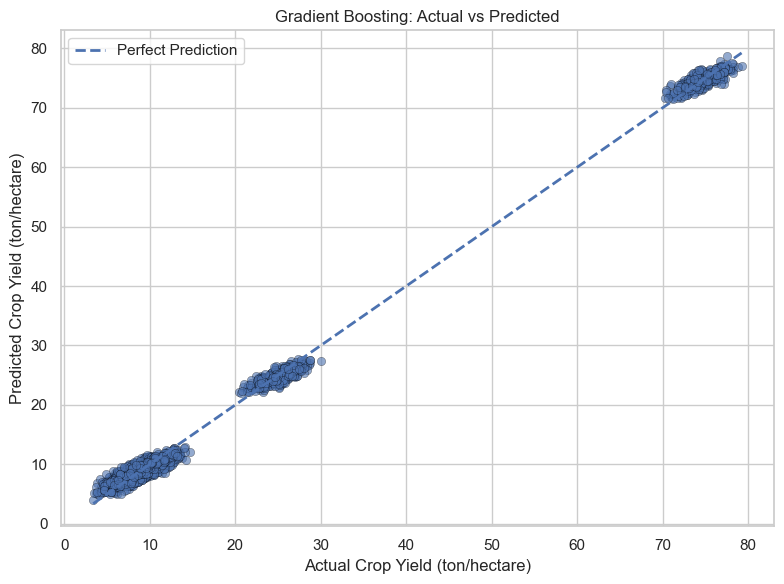

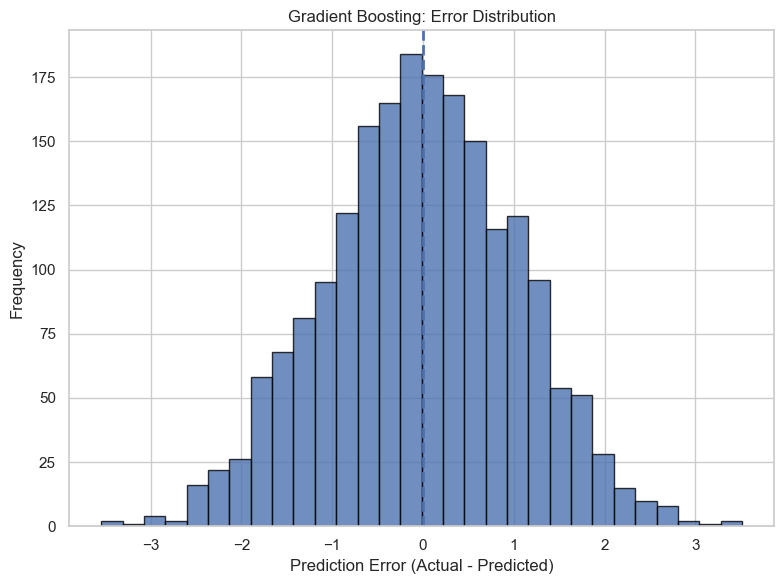

Gradient_Boosting completed.
Test RMSE: 1.0564
Test R²: 0.9981

Training HistGradient Boosting...


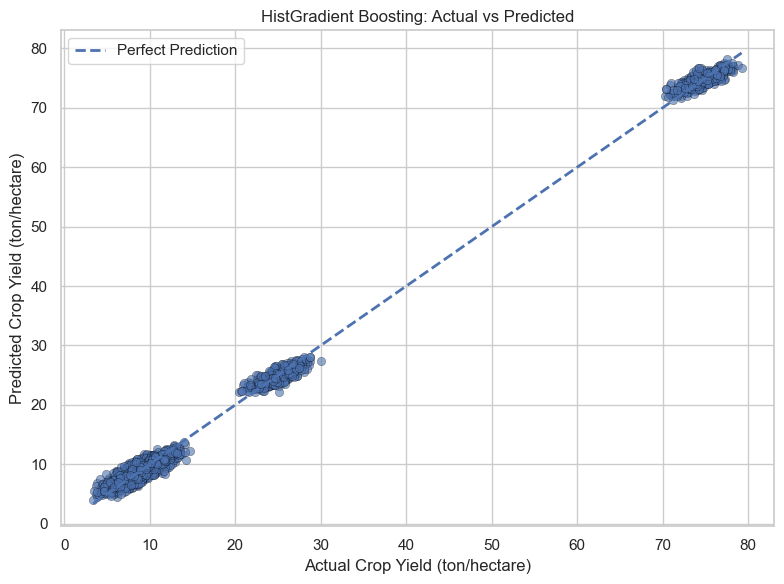

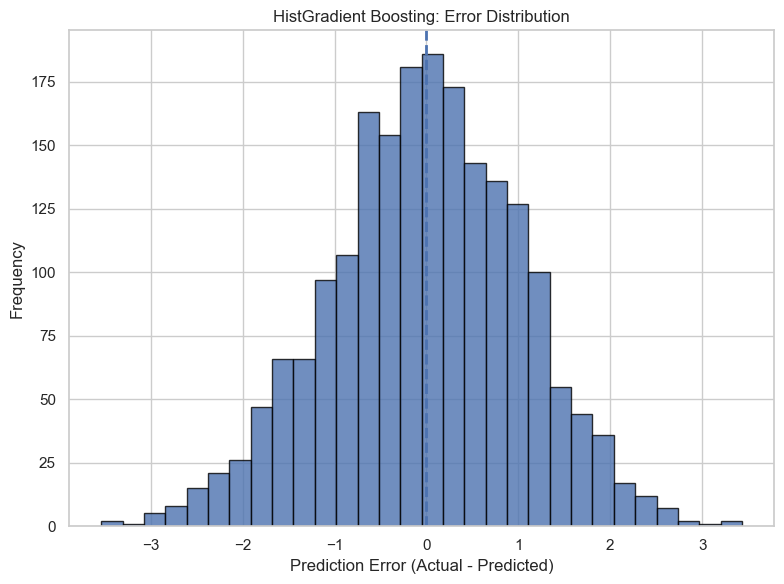

HistGradient_Boosting completed.
Test RMSE: 1.0443
Test R²: 0.9981

Training Extra Trees...


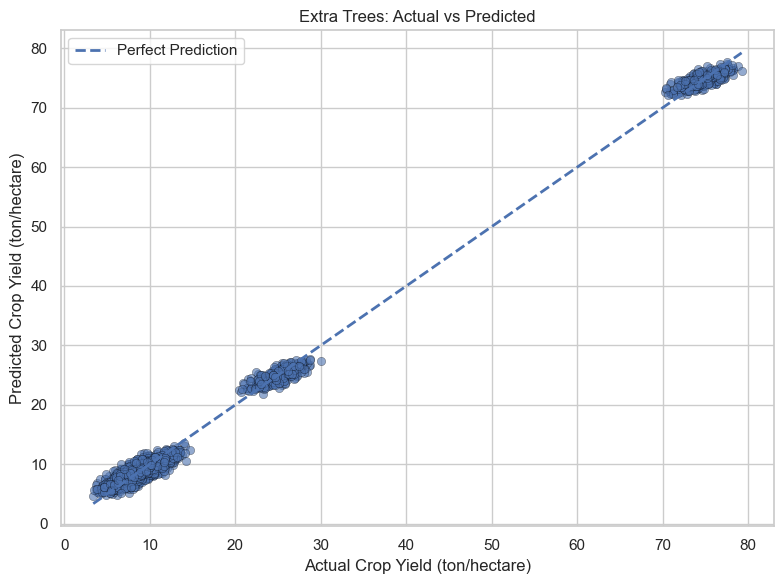

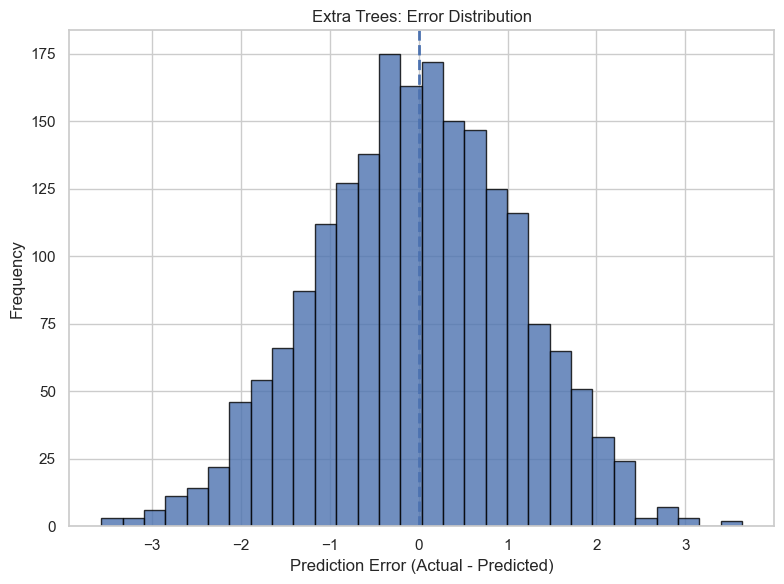

Extra_Trees completed.
Test RMSE: 1.1224
Test R²: 0.9978

Training XGBoost...


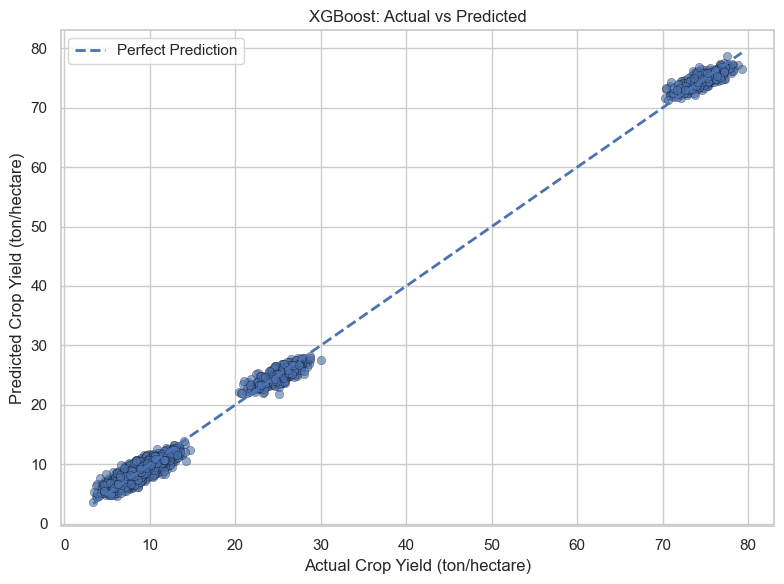

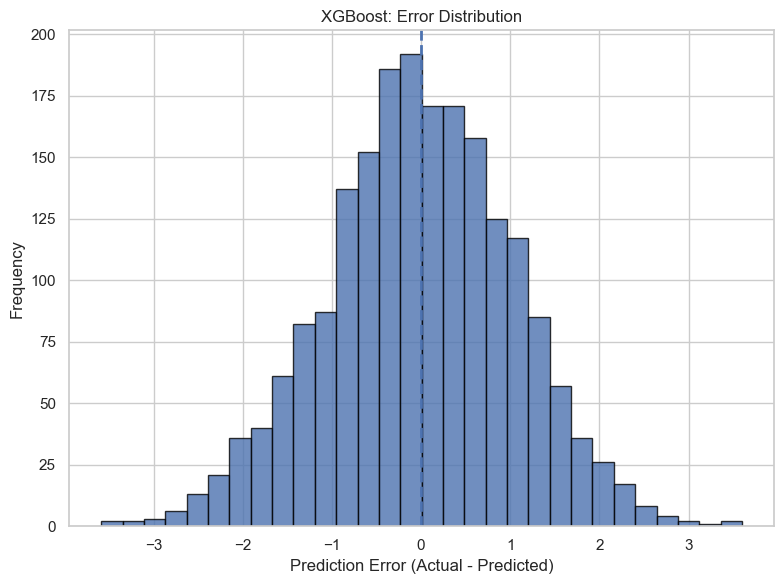

XGBoost completed.
Test RMSE: 1.0444
Test R²: 0.9981

Training CatBoost...


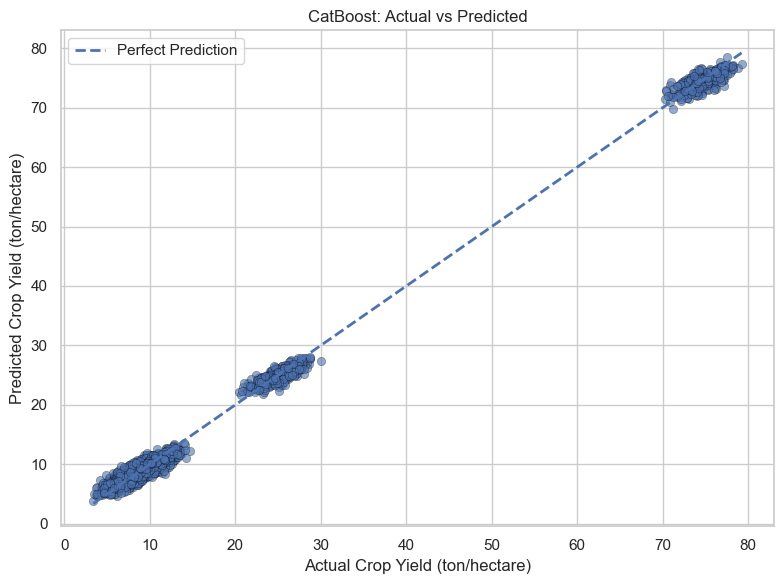

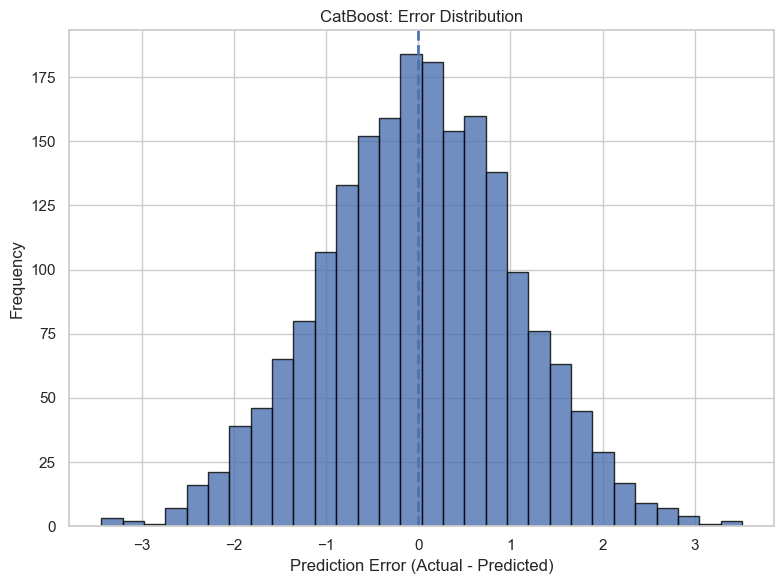

CatBoost completed.
Test RMSE: 1.0461
Test R²: 0.9981

ENSEMBLE AND BOOSTING MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,HistGradient Boosting,0.8303,1.0906,1.0443,0.9981,0.6907,0.9981,3.5391
1,XGBoost,0.8306,1.0909,1.0444,0.9981,0.6916,0.9981,3.5983
2,CatBoost,0.8335,1.0944,1.0461,0.9981,0.6962,0.9981,3.5124
3,Gradient Boosting,0.8459,1.1161,1.0564,0.9981,0.7021,0.9981,3.5419
4,Extra Trees,0.9004,1.2599,1.1224,0.9978,0.7646,0.9978,3.6388



Metrics saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Ensemble_Boosting_Models_Metrics.csv
Models directory: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Models
Results directory: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results


In [70]:

# Step 9.3.1 — Ensemble and Boosting Models

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    ExtraTreesRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error
)

# --------------------------------------------------
# 1. Create output directories
# --------------------------------------------------
MODEL_DIR = os.path.join(PROJECT_DIR, "Models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "Model_Results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# --------------------------------------------------
# 2. Define available ensemble models
# --------------------------------------------------
ensemble_models = {
    "Gradient_Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "HistGradient_Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    ),

    "Extra_Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

# --------------------------------------------------
# 3. Add XGBoost if installed
# --------------------------------------------------
try:
    from xgboost import XGBRegressor

    ensemble_models["XGBoost"] = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("XGBoost is not installed. Skipping XGBoost.")

# --------------------------------------------------
# 4. Add CatBoost if installed
# --------------------------------------------------
try:
    from catboost import CatBoostRegressor

    ensemble_models["CatBoost"] = CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

except ImportError:
    print("CatBoost is not installed. Skipping CatBoost.")

# --------------------------------------------------
# 5. Train, evaluate, save, and plot
# --------------------------------------------------
ensemble_results = []

for model_name, model in ensemble_models.items():

    print(f"\nTraining {model_name.replace('_', ' ')}...")

    try:
        model.fit(X_train_final, y_train)
        y_pred = model.predict(X_test_final)

        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)

        metrics = {
            "Model": model_name.replace("_", " "),
            "MAE": mean_absolute_error(y_test, y_pred),
            "MSE": mse,
            "RMSE": rmse,
            "R2": r2_score(y_test, y_pred),
            "Median_AE": median_absolute_error(y_test, y_pred),
            "Explained_Variance": explained_variance_score(
                y_test, y_pred
            ),
            "Max_Error": max_error(y_test, y_pred)
        }

        ensemble_results.append(metrics)

        # Save trained model
        joblib.dump(
            model,
            os.path.join(
                MODEL_DIR, f"{model_name.lower()}_model.joblib"
            )
        )

        # Save predictions
        prediction_df = pd.DataFrame({
            "Actual_Crop_Yield": np.asarray(y_test),
            "Predicted_Crop_Yield": y_pred,
            "Prediction_Error": np.asarray(y_test) - y_pred
        })

        prediction_df.to_csv(
            os.path.join(
                RESULTS_DIR,
                f"{model_name.lower()}_test_predictions.csv"
            ),
            index=False
        )

        # Actual vs predicted plot
        plt.figure(figsize=(8, 6))
        plt.scatter(
            y_test, y_pred,
            alpha=0.6,
            edgecolors="black",
            linewidths=0.3
        )

        lower = min(np.min(y_test), np.min(y_pred))
        upper = max(np.max(y_test), np.max(y_pred))

        plt.plot(
            [lower, upper], [lower, upper],
            linestyle="--",
            linewidth=2,
            label="Perfect Prediction"
        )

        plt.xlabel("Actual Crop Yield (ton/hectare)")
        plt.ylabel("Predicted Crop Yield (ton/hectare)")
        plt.title(f"{model_name.replace('_', ' ')}: Actual vs Predicted")
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                RESULTS_DIR,
                f"{model_name.lower()}_actual_vs_predicted.jpg"
            ),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

        # Error distribution plot
        errors = np.asarray(y_test) - y_pred

        plt.figure(figsize=(8, 6))
        plt.hist(errors, bins=30, edgecolor="black", alpha=0.8)
        plt.axvline(0, linestyle="--", linewidth=2)

        plt.xlabel("Prediction Error (Actual - Predicted)")
        plt.ylabel("Frequency")
        plt.title(f"{model_name.replace('_', ' ')}: Error Distribution")
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                RESULTS_DIR,
                f"{model_name.lower()}_error_distribution.jpg"
            ),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

        print(f"{model_name} completed.")
        print(f"Test RMSE: {rmse:.4f}")
        print(f"Test R²: {metrics['R2']:.4f}")

    except Exception as e:
        print(f"{model_name} failed: {e}")

# --------------------------------------------------
# 6. Save combined metrics
# --------------------------------------------------
if ensemble_results:

    ensemble_results_df = pd.DataFrame(ensemble_results)

    ensemble_results_path = os.path.join(
        RESULTS_DIR, "Ensemble_Boosting_Models_Metrics.csv"
    )

    ensemble_results_df.to_csv(
        ensemble_results_path, index=False
    )

    print("\nENSEMBLE AND BOOSTING MODEL COMPARISON")

    display(
        ensemble_results_df.sort_values(
            by="RMSE", ascending=True
        ).reset_index(drop=True).round(4)
    )

    print(f"\nMetrics saved to: {ensemble_results_path}")

else:
    print("No ensemble models completed successfully.")

print(f"Models directory: {MODEL_DIR}")
print(f"Results directory: {RESULTS_DIR}")


Training Stacking Regressor...
Stacking model training completed!

STACKING REGRESSOR TEST RESULTS


,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,Stacking Regressor,0.8145,1.038,1.0188,0.9982,0.6935,0.9982,3.4722


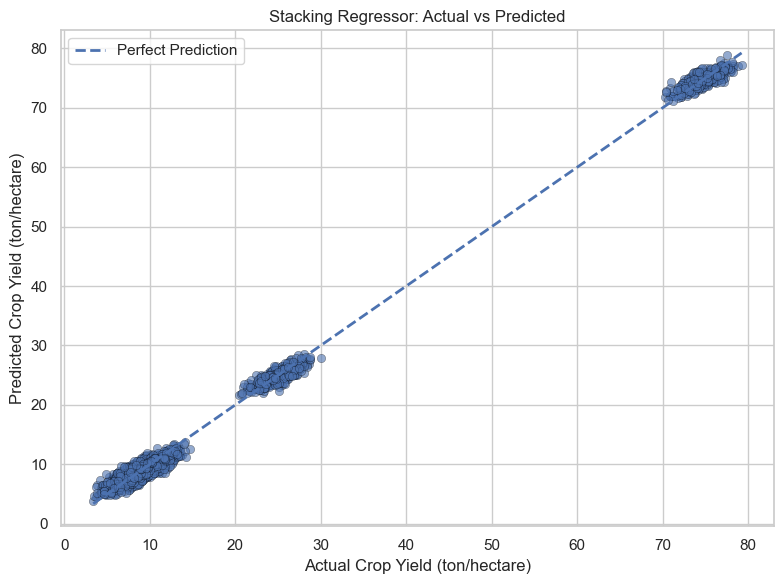

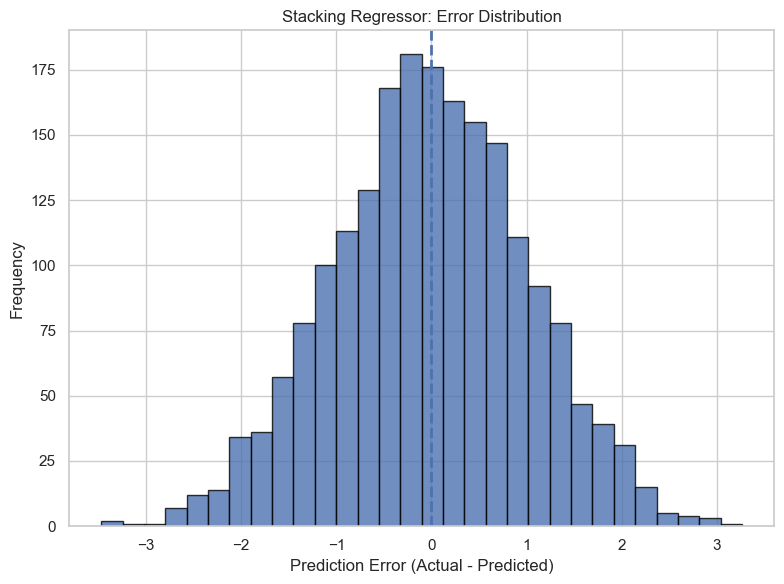


Files saved successfully:
Model: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Models\stacking_regressor_model.joblib
Predictions: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\stacking_regressor_test_predictions.csv
Metrics: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Stacking_Regressor_Metrics.csv
Plots: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results


In [71]:

# Step 9.4.1 — Stacking Regressor

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    StackingRegressor
)
from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error
)

# --------------------------------------------------
# 1. Create output directories
# --------------------------------------------------
MODEL_DIR = os.path.join(PROJECT_DIR, "Models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "Model_Results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# --------------------------------------------------
# 2. Define base learners
# --------------------------------------------------
base_estimators = [
    ("linear", LinearRegression()),

    ("random_forest", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )),

    ("gradient_boosting", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
]

# --------------------------------------------------
# 3. Define stacking model
# --------------------------------------------------
stacking_model = StackingRegressor(
    estimators=base_estimators,
    final_estimator=Ridge(alpha=1.0),
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    passthrough=False,
    n_jobs=-1
)

# --------------------------------------------------
# 4. Train the model
# --------------------------------------------------
print("Training Stacking Regressor...")

stacking_model.fit(X_train_final, y_train)

# Predict on held-out test data
y_pred_stack = stacking_model.predict(X_test_final)

print("Stacking model training completed!")

# --------------------------------------------------
# 5. Calculate evaluation metrics
# --------------------------------------------------
stack_mse = mean_squared_error(y_test, y_pred_stack)

stack_metrics = {
    "Model": "Stacking Regressor",
    "MAE": mean_absolute_error(y_test, y_pred_stack),
    "MSE": stack_mse,
    "RMSE": np.sqrt(stack_mse),
    "R2": r2_score(y_test, y_pred_stack),
    "Median_AE": median_absolute_error(y_test, y_pred_stack),
    "Explained_Variance": explained_variance_score(
        y_test, y_pred_stack
    ),
    "Max_Error": max_error(y_test, y_pred_stack)
}

stack_metrics_df = pd.DataFrame([stack_metrics])

print("\nSTACKING REGRESSOR TEST RESULTS")
display(stack_metrics_df.round(4))

# --------------------------------------------------
# 6. Save trained model
# --------------------------------------------------
stack_model_path = os.path.join(
    MODEL_DIR, "stacking_regressor_model.joblib"
)

joblib.dump(stacking_model, stack_model_path)

# --------------------------------------------------
# 7. Save test predictions
# --------------------------------------------------
stack_predictions_df = pd.DataFrame({
    "Actual_Crop_Yield": np.asarray(y_test),
    "Predicted_Crop_Yield": y_pred_stack,
    "Prediction_Error": np.asarray(y_test) - y_pred_stack
})

stack_predictions_path = os.path.join(
    RESULTS_DIR, "stacking_regressor_test_predictions.csv"
)

stack_predictions_df.to_csv(
    stack_predictions_path, index=False
)

# Save metrics
stack_metrics_path = os.path.join(
    RESULTS_DIR, "Stacking_Regressor_Metrics.csv"
)

stack_metrics_df.to_csv(stack_metrics_path, index=False)

# --------------------------------------------------
# 8. Actual vs predicted plot
# --------------------------------------------------
actual_values = np.asarray(y_test)

plt.figure(figsize=(8, 6))
plt.scatter(
    actual_values, y_pred_stack,
    alpha=0.6,
    edgecolors="black",
    linewidths=0.3
)

lower = min(actual_values.min(), y_pred_stack.min())
upper = max(actual_values.max(), y_pred_stack.max())

plt.plot(
    [lower, upper], [lower, upper],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Crop Yield (ton/hectare)")
plt.ylabel("Predicted Crop Yield (ton/hectare)")
plt.title("Stacking Regressor: Actual vs Predicted")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR, "stacking_actual_vs_predicted.jpg"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# --------------------------------------------------
# 9. Prediction error distribution
# --------------------------------------------------
errors = actual_values - y_pred_stack

plt.figure(figsize=(8, 6))
plt.hist(errors, bins=30, edgecolor="black", alpha=0.8)
plt.axvline(0, linestyle="--", linewidth=2)

plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Stacking Regressor: Error Distribution")
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR, "stacking_error_distribution.jpg"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nFiles saved successfully:")
print("Model:", stack_model_path)
print("Predictions:", stack_predictions_path)
print("Metrics:", stack_metrics_path)
print("Plots:", RESULTS_DIR)


Loaded: Linear_Regression_Metrics.csv
Loaded: Classical_ML_Models_Metrics.csv
Loaded: Ensemble_Boosting_Models_Metrics.csv
Loaded: Stacking_Regressor_Metrics.csv

CONSOLIDATED MODEL COMPARISON


,Rank,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,1,Stacking Regressor,0.8145,1.0380,1.0188,0.9982,0.6935,0.9982,3.4722
1,2,Linear Regression,0.8161,1.0415,1.0205,0.9982,0.6937,0.9982,3.4767
2,3,HistGradient Boosting,0.8303,1.0906,1.0443,0.9981,0.6907,0.9981,3.5391
3,4,XGBoost,0.8306,1.0909,1.0444,0.9981,0.6916,0.9981,3.5983
4,5,CatBoost,0.8335,1.0944,1.0461,0.9981,0.6962,0.9981,3.5124
5,6,Gradient Boosting,0.8459,1.1161,1.0564,0.9981,0.7021,0.9981,3.5419
6,7,Extra Trees,0.9004,1.2599,1.1224,0.9978,0.7646,0.9978,3.6388
7,8,Random Forest,0.8982,1.2640,1.1243,0.9978,0.7637,0.9978,3.7279
8,9,Decision Tree,1.3260,2.7489,1.6580,0.9953,1.1600,0.9953,6.1300
9,10,SVR,2.4604,21.4011,4.6261,0.9633,1.2520,0.9640,48.9792



Saved comparison table:
C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Consolidated_Model_Comparison.csv


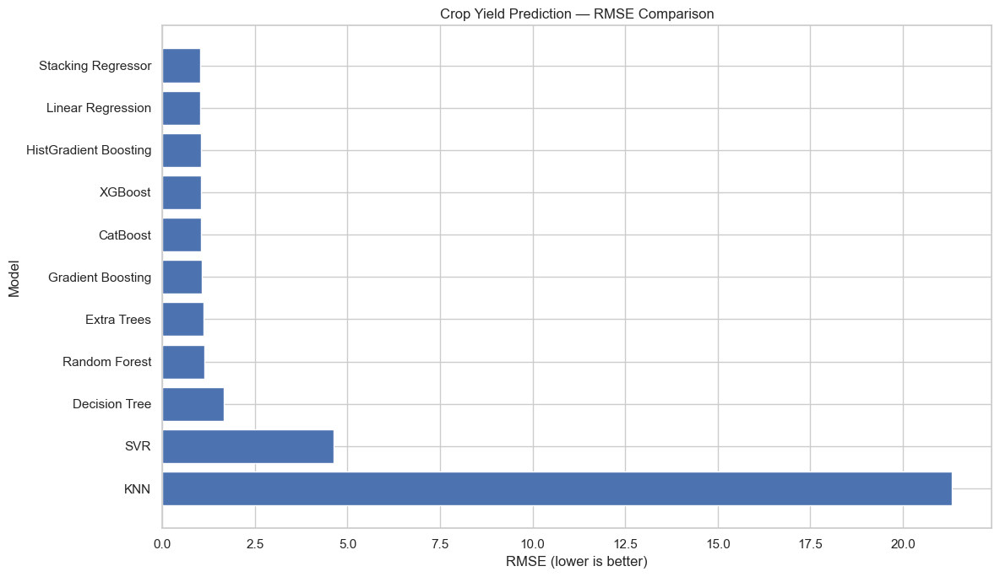

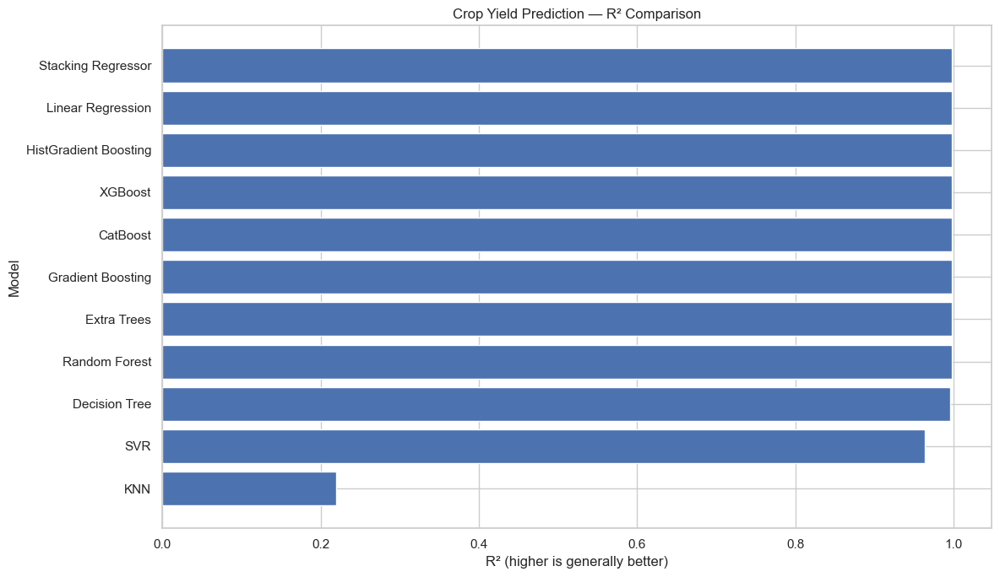


LOWEST-RMSE CANDIDATE
Model: Stacking Regressor
RMSE: 1.0188
R²: 0.9982

Comparison complete!
Output folder: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results


In [72]:

# Step 9.5.1 — Consolidated Model Comparison

import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Define results directory
# --------------------------------------------------
RESULTS_DIR = os.path.join(PROJECT_DIR, "Model_Results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# --------------------------------------------------
# 2. Identify consolidated metrics files
# --------------------------------------------------
metrics_files = [
    "Linear_Regression_Metrics.csv",
    "Classical_ML_Models_Metrics.csv",
    "Ensemble_Boosting_Models_Metrics.csv",
    "Stacking_Regressor_Metrics.csv"
]

all_results = []

for file_name in metrics_files:
    file_path = os.path.join(RESULTS_DIR, file_name)

    if os.path.exists(file_path):
        df_metrics = pd.read_csv(file_path)

        if not df_metrics.empty and "Model" in df_metrics.columns:
            all_results.append(df_metrics)
            print(f"Loaded: {file_name}")
        else:
            print(f"Skipped empty or invalid file: {file_name}")
    else:
        print(f"File not found, skipped: {file_name}")

# --------------------------------------------------
# 3. Combine metrics
# --------------------------------------------------
if not all_results:
    raise FileNotFoundError(
        "No valid metrics files found. "
        "Check the CSV filenames inside Model_Results."
    )

comparison_df = pd.concat(
    all_results,
    ignore_index=True
)

# Remove duplicate model rows, if any
comparison_df = comparison_df.drop_duplicates(
    subset=["Model"],
    keep="last"
)

# --------------------------------------------------
# 4. Rank models by RMSE
# --------------------------------------------------
if "RMSE" not in comparison_df.columns:
    raise ValueError(
        "The metrics files do not contain an RMSE column."
    )

comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

comparison_df.insert(
    0,
    "Rank",
    range(1, len(comparison_df) + 1)
)

# --------------------------------------------------
# 5. Display and save full comparison
# --------------------------------------------------
comparison_path = os.path.join(
    RESULTS_DIR,
    "Consolidated_Model_Comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("\nCONSOLIDATED MODEL COMPARISON")
display(comparison_df.round(4))

print("\nSaved comparison table:")
print(comparison_path)

# --------------------------------------------------
# 6. Plot RMSE comparison
# --------------------------------------------------
rmse_plot_df = comparison_df.sort_values(
    "RMSE", ascending=True
)

plt.figure(figsize=(12, 7))
plt.barh(
    rmse_plot_df["Model"],
    rmse_plot_df["RMSE"]
)

plt.xlabel("RMSE (lower is better)")
plt.ylabel("Model")
plt.title("Crop Yield Prediction — RMSE Comparison")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "Model_Comparison_RMSE.jpg"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# --------------------------------------------------
# 7. Plot R² comparison
# --------------------------------------------------
if "R2" in comparison_df.columns:

    r2_plot_df = comparison_df.sort_values(
        "R2", ascending=False
    )

    plt.figure(figsize=(12, 7))
    plt.barh(
        r2_plot_df["Model"],
        r2_plot_df["R2"]
    )

    plt.xlabel("R² (higher is generally better)")
    plt.ylabel("Model")
    plt.title("Crop Yield Prediction — R² Comparison")
    plt.gca().invert_yaxis()
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULTS_DIR, "Model_Comparison_R2.jpg"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# --------------------------------------------------
# 8. Show the lowest-RMSE candidate
# --------------------------------------------------
best_candidate = comparison_df.iloc[0]

print("\nLOWEST-RMSE CANDIDATE")
print("Model:", best_candidate["Model"])
print("RMSE:", round(best_candidate["RMSE"], 4))

if "R2" in comparison_df.columns:
    print("R²:", round(best_candidate["R2"], 4))

print("\nComparison complete!")
print("Output folder:", RESULTS_DIR)


In [73]:

# Step 9.6.1 — Target Leakage Audit

import os
import numpy as np
import pandas as pd

target = "Crop_Yield_ton_per_hectare"

# --------------------------------------------------
# 1. Verify target is excluded from predictors
# --------------------------------------------------
print("TARGET LEAKAGE AUDIT")
print("-" * 55)

print("Target column:", target)
print("Target present in X_train_final:",
      target in X_train_final.columns)
print("Target present in X_test_final:",
      target in X_test_final.columns)

assert target not in X_train_final.columns, (
    "Potential leakage: target found in training features!"
)
assert target not in X_test_final.columns, (
    "Potential leakage: target found in testing features!"
)

print("\nPASS: Target column is not directly present in final features.")

# --------------------------------------------------
# 2. Inspect suspicious feature names
# --------------------------------------------------
suspicious_terms = [
    "yield", "target", "label", "prediction",
    "actual", "output", "result"
]

suspicious_features = [
    col for col in X.columns
    if any(term in col.lower() for term in suspicious_terms)
]

print("\nFeatures with potentially suspicious names:")
print(suspicious_features if suspicious_features else "None found")

# --------------------------------------------------
# 3. Check correlations with the target
# --------------------------------------------------
df_audit = df_feature_engineered.copy()

numeric_df = df_audit.select_dtypes(include=np.number)

if target not in numeric_df.columns:
    raise ValueError(
        f"Target '{target}' was not found as a numeric column."
    )

target_correlations = (
    numeric_df.corr()[target]
    .drop(target)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

correlation_df = pd.DataFrame({
    "Feature": target_correlations.index,
    "Correlation_with_Target": target_correlations.values,
    "Absolute_Correlation": target_correlations.abs().values
})

print("\nTop 15 numerical features correlated with crop yield:")
display(correlation_df.head(15).round(4))

# Flag strong correlations for investigation, not automatic removal
strong_correlations = correlation_df[
    correlation_df["Absolute_Correlation"] >= 0.95
]

print("\nFeatures with absolute target correlation >= 0.95:")
if strong_correlations.empty:
    print("None found.")
else:
    display(strong_correlations.round(4))

# --------------------------------------------------
# 4. Check duplicate predictor columns
# --------------------------------------------------
duplicate_feature_names = X.columns[X.columns.duplicated()].tolist()

print("\nDuplicate predictor column names:")
print(duplicate_feature_names if duplicate_feature_names else "None found")

# --------------------------------------------------
# 5. Check engineered features
# --------------------------------------------------
engineered_features = [
    "NPK_Total",
    "N_to_PK_Ratio",
    "Soil_pH_Deviation",
    "Moisture_Humidity_Interaction",
    "Rainfall_Sunlight_Interaction",
    "Fertilizer_to_NPK_Ratio"
]

print("\nEngineered feature availability:")
for feature in engineered_features:
    print(f"{feature}: {'Present' if feature in df_audit.columns else 'Not found'}")

# --------------------------------------------------
# 6. Save audit report
# --------------------------------------------------
audit_path = os.path.join(
    PROJECT_DIR,
    "Model_Results",
    "Target_Leakage_Correlation_Audit.csv"
)

os.makedirs(os.path.dirname(audit_path), exist_ok=True)
correlation_df.to_csv(audit_path, index=False)

print("\nCorrelation audit saved to:")
print(audit_path)

print(
    "\nNote: High correlation alone does not prove leakage. "
    "Investigate how each strongly correlated feature was created."
)


TARGET LEAKAGE AUDIT
-------------------------------------------------------
Target column: Crop_Yield_ton_per_hectare
Target present in X_train_final: False
Target present in X_test_final: False

PASS: Target column is not directly present in final features.

Features with potentially suspicious names:
None found

Top 15 numerical features correlated with crop yield:


,Feature,Correlation_with_Target,Absolute_Correlation
0,Fertilizer_Used,0.0514,0.0514
1,Fertilizer_to_NPK_Ratio,0.0343,0.0343
2,Rainfall,0.0312,0.0312
3,Rainfall_Sunlight_Interaction,0.0254,0.0254
4,Wind_Speed,0.0152,0.0152
5,Pesticide_Used,-0.0121,0.0121
6,Soil_pH,-0.0105,0.0105
7,K,0.0099,0.0099
8,Soil_pH_Deviation,-0.0098,0.0098
9,Humidity,0.0069,0.0069



Features with absolute target correlation >= 0.95:
None found.

Duplicate predictor column names:
None found

Engineered feature availability:
NPK_Total: Present
N_to_PK_Ratio: Present
Soil_pH_Deviation: Present
Moisture_Humidity_Interaction: Present
Rainfall_Sunlight_Interaction: Present
Fertilizer_to_NPK_Ratio: Present

Correlation audit saved to:
C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Target_Leakage_Correlation_Audit.csv

Note: High correlation alone does not prove leakage. Investigate how each strongly correlated feature was created.


TARGET DISTRIBUTION
-------------------------------------------------------
count    10000.000000
mean        22.342801
std         23.986065
min          1.760000
25%          8.280000
50%         10.270000
75%         24.750000
max         80.990000
Name: Crop_Yield_ton_per_hectare, dtype: float64

Number of unique target values: 2191
Target standard deviation: 23.9861
Target range: 79.23

TRAINING AND TESTING ALIGNMENT
-------------------------------------------------------
Training feature/target indexes match: True
Testing feature/target indexes match: True
Training feature shape: (8000, 42)
Training target shape: (8000,)
Testing feature shape: (2000, 42)
Testing target shape: (2000,)

TRAIN VS TEST TARGET SUMMARY


,Training_Target,Testing_Target
count,8000.0000,2000.0000
mean,22.3286,22.3996
std,23.9467,24.1489
min,1.7600,3.3800
25%,8.2800,8.2550
50%,10.2800,10.1850
75%,24.7400,24.8375
max,80.9900,79.2200



TARGET MEANS BY CATEGORICAL FEATURE
-------------------------------------------------------

Soil_Type


,Feature,Category,count,mean,std
0,Soil_Type,Clay,2467,22.6868,24.3287
1,Soil_Type,Loamy,2543,22.5992,24.0435
2,Soil_Type,Sandy,2496,21.2618,23.0072
3,Soil_Type,Silt,2494,22.8229,24.5212



Region


,Feature,Category,count,mean,std
0,Region,Central,1982,22.5410,24.1050
1,Region,East,2006,22.4352,24.0803
2,Region,North,2003,21.0743,22.9446
3,Region,South,2013,22.5670,24.2374
4,Region,West,1996,23.1000,24.5111


... (2 outputs left out)


Crop_Type


,Feature,Category,count,mean,std
0,Crop_Type,Cotton,1666,7.4279,1.7278
1,Crop_Type,Maize,1658,10.0760,1.7019
2,Crop_Type,Potato,1670,24.8910,1.6819
3,Crop_Type,Rice,1702,9.4020,1.6571
4,Crop_Type,Sugarcane,1633,74.8303,1.6376
5,Crop_Type,Wheat,1671,8.7247,1.6493



Irrigation_Type


,Feature,Category,count,mean,std
0,Irrigation_Type,Canal,2529,22.1953,24.1432
1,Irrigation_Type,Drip,2532,22.3375,24.0600
2,Irrigation_Type,Rainfed,2507,21.9596,23.5708
3,Irrigation_Type,Sprinkler,2432,22.8968,24.1735


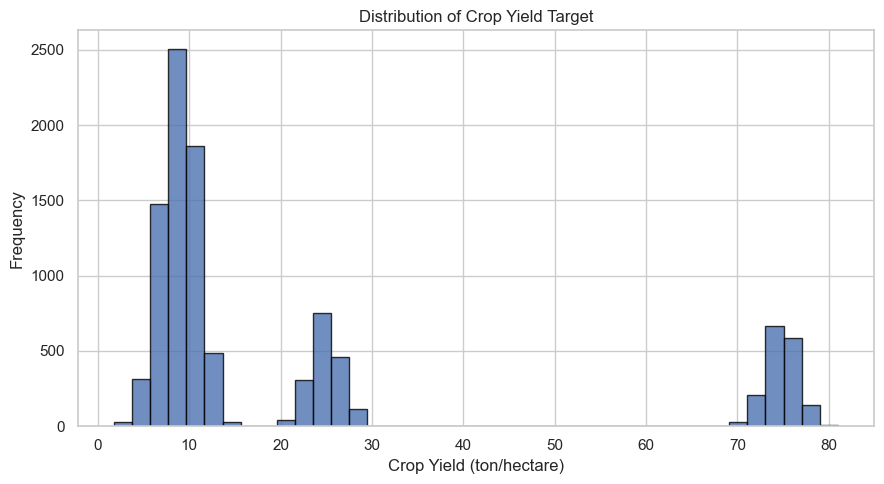


MODEL VS SIMPLE BASELINE


,Model,MAE,RMSE,R2
0,Mean Dummy Baseline,18.2239,24.1430,-0.0000
1,Stacking Regressor,0.8145,1.0188,0.9982



Audit outputs saved in: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results


In [74]:

# Step 9.6.2 — Deeper Model Reliability Audit

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

target = "Crop_Yield_ton_per_hectare"
audit_dir = os.path.join(PROJECT_DIR, "Model_Results")
os.makedirs(audit_dir, exist_ok=True)

# --------------------------------------------------
# 1. Inspect target distribution
# --------------------------------------------------
print("TARGET DISTRIBUTION")
print("-" * 55)

print(df_feature_engineered[target].describe())

print(
    "\nNumber of unique target values:",
    df_feature_engineered[target].nunique()
)

print(
    "Target standard deviation:",
    round(df_feature_engineered[target].std(), 4)
)

print(
    "Target range:",
    round(
        df_feature_engineered[target].max()
        - df_feature_engineered[target].min(),
        4
    )
)

# --------------------------------------------------
# 2. Check feature/target index alignment
# --------------------------------------------------
print("\nTRAINING AND TESTING ALIGNMENT")
print("-" * 55)

print(
    "Training feature/target indexes match:",
    X_train_final.index.equals(y_train.index)
)

print(
    "Testing feature/target indexes match:",
    X_test_final.index.equals(y_test.index)
)

print("Training feature shape:", X_train_final.shape)
print("Training target shape:", y_train.shape)
print("Testing feature shape:", X_test_final.shape)
print("Testing target shape:", y_test.shape)

assert X_train_final.index.equals(y_train.index), (
    "Training rows may be misaligned!"
)

assert X_test_final.index.equals(y_test.index), (
    "Testing rows may be misaligned!"
)

# --------------------------------------------------
# 3. Compare train and test target distributions
# --------------------------------------------------
target_distribution = pd.DataFrame({
    "Training_Target": y_train.describe(),
    "Testing_Target": y_test.describe()
})

print("\nTRAIN VS TEST TARGET SUMMARY")
display(target_distribution.round(4))

# --------------------------------------------------
# 4. Check categorical predictors
# --------------------------------------------------
print("\nTARGET MEANS BY CATEGORICAL FEATURE")
print("-" * 55)

categorical_features_original = [
    col for col in [
        "Soil_Type",
        "Region",
        "Season",
        "Crop_Type",
        "Irrigation_Type"
    ]
    if col in df_feature_engineered.columns
]

categorical_summaries = []

for col in categorical_features_original:
    summary = (
        df_feature_engineered.groupby(col, observed=True)[target]
        .agg(["count", "mean", "std"])
        .reset_index()
    )

    summary.insert(0, "Feature", col)
    summary = summary.rename(columns={col: "Category"})

    categorical_summaries.append(summary)

    print(f"\n{col}")
    display(summary.round(4))

if categorical_summaries:
    categorical_summary_df = pd.concat(
        categorical_summaries,
        ignore_index=True
    )

    categorical_summary_df.to_csv(
        os.path.join(
            audit_dir,
            "Categorical_Target_Group_Summary.csv"
        ),
        index=False
    )

# --------------------------------------------------
# 5. Check whether the target is almost constant
# --------------------------------------------------
plt.figure(figsize=(9, 5))

plt.hist(
    df_feature_engineered[target],
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Crop Yield (ton/hectare)")
plt.ylabel("Frequency")
plt.title("Distribution of Crop Yield Target")
plt.tight_layout()

plt.savefig(
    os.path.join(audit_dir, "Target_Distribution_Audit.jpg"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------
# 6. Compare against a simple mean predictor
# --------------------------------------------------
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_final, y_train)

dummy_predictions = dummy_model.predict(X_test_final)

dummy_mse = mean_squared_error(y_test, dummy_predictions)

dummy_results = pd.DataFrame([
    {
        "Model": "Mean Dummy Baseline",
        "MAE": mean_absolute_error(y_test, dummy_predictions),
        "RMSE": np.sqrt(dummy_mse),
        "R2": r2_score(y_test, dummy_predictions)
    },
    {
        "Model": "Stacking Regressor",
        "MAE": mean_absolute_error(y_test, y_pred_stack),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_stack)),
        "R2": r2_score(y_test, y_pred_stack)
    }
])

print("\nMODEL VS SIMPLE BASELINE")
display(dummy_results.round(4))

dummy_results.to_csv(
    os.path.join(audit_dir, "Dummy_Baseline_Comparison.csv"),
    index=False
)

print("\nAudit outputs saved in:", audit_dir)


In [75]:

# Step 9.6.3 — Crop-Type-Only Baseline and Per-Crop Reliability Audit

import os
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target = "Crop_Yield_ton_per_hectare"
audit_dir = os.path.join(PROJECT_DIR, "Model_Results")
os.makedirs(audit_dir, exist_ok=True)

# Recover crop types using the original row indexes
crop_train = df_feature_engineered.loc[y_train.index, "Crop_Type"]
crop_test = df_feature_engineered.loc[y_test.index, "Crop_Type"]

# Learn average yield per crop using TRAINING DATA ONLY
crop_mean_map = pd.DataFrame({
    "Crop_Type": crop_train,
    target: y_train
}).groupby("Crop_Type")[target].mean()

# Predict each test row using its crop's training mean
crop_only_predictions = crop_test.map(crop_mean_map)

# Handle any unseen crop category safely
crop_only_predictions = crop_only_predictions.fillna(y_train.mean())

# Compare the crop-only baseline with the stacking model
comparison = pd.DataFrame([
    {
        "Model": "Mean Dummy Baseline",
        "MAE": mean_absolute_error(
            y_test, np.full(len(y_test), y_train.mean())
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, np.full(len(y_test), y_train.mean())
        )),
        "R2": r2_score(
            y_test, np.full(len(y_test), y_train.mean())
        )
    },
    {
        "Model": "Crop-Type-Only Baseline",
        "MAE": mean_absolute_error(y_test, crop_only_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, crop_only_predictions)),
        "R2": r2_score(y_test, crop_only_predictions)
    },
    {
        "Model": "Stacking Regressor",
        "MAE": mean_absolute_error(y_test, y_pred_stack),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_stack)),
        "R2": r2_score(y_test, y_pred_stack)
    }
])

print("MODEL COMPARISON")
display(comparison.round(4))

comparison.to_csv(
    os.path.join(audit_dir, "Crop_Type_Baseline_Comparison.csv"),
    index=False
)

# Evaluate stacking predictions separately for each crop
per_crop_results = []

for crop in sorted(crop_test.unique()):
    mask = crop_test.to_numpy() == crop
    actual = y_test.to_numpy()[mask]
    predicted = np.asarray(y_pred_stack)[mask]

    per_crop_results.append({
        "Crop_Type": crop,
        "Test_Count": int(mask.sum()),
        "Actual_Mean": actual.mean(),
        "Predicted_Mean": predicted.mean(),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted) if len(actual) > 1 else np.nan
    })

per_crop_df = pd.DataFrame(per_crop_results)

print("\nSTACKING MODEL PERFORMANCE BY CROP TYPE")
display(per_crop_df.round(4))

per_crop_df.to_csv(
    os.path.join(audit_dir, "Stacking_Per_Crop_Audit.csv"),
    index=False
)

print("\nFiles saved to:", audit_dir)


MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Mean Dummy Baseline,18.2239,24.1430,-0.0000
1,Crop-Type-Only Baseline,1.3605,1.6890,0.9951
2,Stacking Regressor,0.8145,1.0188,0.9982



STACKING MODEL PERFORMANCE BY CROP TYPE


,Crop_Type,Test_Count,Actual_Mean,Predicted_Mean,MAE,RMSE,R2
0,Cotton,340,7.3768,7.4700,0.8601,1.0713,0.5952
1,Maize,335,10.1992,10.1322,0.7810,0.9862,0.6780
2,Potato,316,24.9989,24.9407,0.8576,1.0312,0.6491
3,Rice,328,9.3325,9.3285,0.7997,0.9997,0.6291
4,Sugarcane,333,74.6878,74.7541,0.7929,1.0209,0.6333
5,Wheat,348,8.7434,8.7911,0.7979,1.0016,0.6178



Files saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results


In [76]:

# Step 9.6.4 — Feature Ablation: Remove Crop_Type

import os
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    StackingRegressor
)
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

audit_dir = os.path.join(PROJECT_DIR, "Model_Results")
os.makedirs(audit_dir, exist_ok=True)

# Identify encoded Crop_Type columns
crop_columns = [
    col for col in X_train_final.columns
    if col == "Crop_Type" or str(col).startswith("Crop_Type_")
]

print("Encoded Crop_Type columns found:", crop_columns)

if not crop_columns:
    print("\nCould not identify Crop_Type columns automatically.")
    print("Available feature names:")
    print(X_train_final.columns.tolist())
else:
    # Remove crop-type predictors without changing the target or row indexes
    X_train_no_crop = X_train_final.drop(columns=crop_columns)
    X_test_no_crop = X_test_final.drop(columns=crop_columns)

    # Recreate the same stacking architecture
    audit_estimators = [
        ("linear", LinearRegression()),
        ("random_forest", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )),
        ("gradient_boosting", GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]

    audit_stack = StackingRegressor(
        estimators=audit_estimators,
        final_estimator=Ridge(alpha=1.0),
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        passthrough=False,
        n_jobs=-1
    )

    print("\nTraining stacking model WITHOUT Crop_Type...")
    audit_stack.fit(X_train_no_crop, y_train)

    predictions_no_crop = audit_stack.predict(X_test_no_crop)

    # Compare the original model with the ablation model
    ablation_results = pd.DataFrame([
        {
            "Model": "Stacking - All Features",
            "Feature_Count": X_train_final.shape[1],
            "MAE": mean_absolute_error(y_test, y_pred_stack),
            "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_stack)),
            "R2": r2_score(y_test, y_pred_stack)
        },
        {
            "Model": "Stacking - Without Crop_Type",
            "Feature_Count": X_train_no_crop.shape[1],
            "MAE": mean_absolute_error(y_test, predictions_no_crop),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions_no_crop)),
            "R2": r2_score(y_test, predictions_no_crop)
        }
    ])

    print("\nFEATURE-ABLATION RESULTS")
    display(ablation_results.round(4))

    ablation_results.to_csv(
        os.path.join(audit_dir, "Crop_Type_Feature_Ablation.csv"),
        index=False
    )

    print("\nResults saved to:", audit_dir)


Encoded Crop_Type columns found: ['Crop_Type_Cotton', 'Crop_Type_Maize', 'Crop_Type_Potato', 'Crop_Type_Rice', 'Crop_Type_Sugarcane', 'Crop_Type_Wheat']

Training stacking model WITHOUT Crop_Type...

FEATURE-ABLATION RESULTS


,Model,Feature_Count,MAE,RMSE,R2
0,Stacking - All Features,42,0.8145,1.0188,0.9982
1,Stacking - Without Crop_Type,36,18.2402,24.1903,-0.0039



Results saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results


In [77]:

# Step 9.5.1 — Inspect Existing Model Results

import os

results_dir = os.path.join(PROJECT_DIR, "Model_Results")

print("Existing model-results files:\n")

for filename in sorted(os.listdir(results_dir)):
    if filename.lower().endswith(".csv"):
        print(filename)


Existing model-results files:

Categorical_Target_Group_Summary.csv
Classical_ML_Models_Metrics.csv
Consolidated_Model_Comparison.csv
Crop_Type_Baseline_Comparison.csv
Crop_Type_Feature_Ablation.csv
Dummy_Baseline_Comparison.csv
Ensemble_Boosting_Models_Metrics.csv
Final_Consolidated_Evaluation.csv
Final_Evaluation_Artifact_Audit.csv
Final_Model_Findings.csv
Final_Model_Limitations.csv
Final_Model_Selection_Report.csv
Linear_Regression_Metrics.csv
Linear_Regression_Test_Predictions.csv
Saved_Model_Artifacts_Audit.csv
Stacking_Per_Crop_Audit.csv
Stacking_Regressor_Metrics.csv
Target_Leakage_Correlation_Audit.csv
catboost_test_predictions.csv
decision_tree_test_predictions.csv
extra_trees_test_predictions.csv
gradient_boosting_test_predictions.csv
histgradient_boosting_test_predictions.csv
knn_test_predictions.csv
random_forest_test_predictions.csv
stacking_regressor_test_predictions.csv
svr_test_predictions.csv
xgboost_test_predictions.csv


In [78]:

# Step 9.5.2 — Review Saved Model Comparison Results

import os
import pandas as pd

results_dir = os.path.join(PROJECT_DIR, "Model_Results")

comparison_file = os.path.join(
    results_dir, "Consolidated_Model_Comparison.csv"
)

if not os.path.exists(comparison_file):
    raise FileNotFoundError(
        f"Comparison file not found: {comparison_file}"
    )

comparison_df = pd.read_csv(comparison_file)

print("=" * 80)
print("CONSOLIDATED MODEL COMPARISON")
print("=" * 80)

print("Shape:", comparison_df.shape)
print("\nColumns:")
print(comparison_df.columns.tolist())

print("\nComplete comparison table:")
display(comparison_df)

print("\n" + "=" * 80)
print("ADDITIONAL METRIC FILES")
print("=" * 80)

metric_files = [
    "Linear_Regression_Metrics.csv",
    "Classical_ML_Models_Metrics.csv",
    "Ensemble_Boosting_Models_Metrics.csv",
    "Stacking_Regressor_Metrics.csv",
]

for filename in metric_files:
    filepath = os.path.join(results_dir, filename)

    if os.path.exists(filepath):
        print(f"\n--- {filename} ---")
        metrics_df = pd.read_csv(filepath)
        print("Shape:", metrics_df.shape)
        display(metrics_df)
    else:
        print(f"\nFile not found: {filename}")


CONSOLIDATED MODEL COMPARISON
Shape: (11, 9)

Columns:
['Rank', 'Model', 'MAE', 'MSE', 'RMSE', 'R2', 'Median_AE', 'Explained_Variance', 'Max_Error']

Complete comparison table:


,Rank,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,1,Stacking Regressor,0.814537,1.038037,1.018841,0.998219,0.693528,0.998219,3.472214
1,2,Linear Regression,0.816061,1.041491,1.020534,0.998213,0.693712,0.998214,3.476712
2,3,HistGradient Boosting,0.830327,1.090591,1.044314,0.998129,0.690723,0.998130,3.539113
3,4,XGBoost,0.830647,1.090852,1.044438,0.998129,0.691580,0.998129,3.598270
4,5,CatBoost,0.833454,1.094367,1.046120,0.998122,0.696238,0.998123,3.512351
5,6,Gradient Boosting,0.845899,1.116059,1.056437,0.998085,0.702105,0.998086,3.541897
6,7,Extra Trees,0.900441,1.259867,1.122438,0.997839,0.764600,0.997839,3.638800
7,8,Random Forest,0.898155,1.263963,1.124261,0.997832,0.763675,0.997833,3.727900
8,9,Decision Tree,1.325965,2.748918,1.657986,0.995284,1.160000,0.995292,6.130000
9,10,SVR,2.460433,21.401082,4.626130,0.963284,1.252002,0.963952,48.979238



ADDITIONAL METRIC FILES

--- Linear_Regression_Metrics.csv ---
Shape: (1, 8)


,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,Linear Regression,0.816061,1.041491,1.020534,0.998213,0.693712,0.998214,3.476712



--- Classical_ML_Models_Metrics.csv ---
Shape: (4, 8)


,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,Decision Tree,1.325965,2.748918,1.657986,0.995284,1.160000,0.995292,6.130000
1,Random Forest,0.898155,1.263963,1.124261,0.997832,0.763675,0.997833,3.727900
2,SVR,2.460433,21.401082,4.626130,0.963284,1.252002,0.963952,48.979238
3,KNN,15.099617,454.811306,21.326305,0.219714,11.696032,0.219788,67.976383



--- Ensemble_Boosting_Models_Metrics.csv ---
Shape: (5, 8)


,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,Gradient Boosting,0.845899,1.116059,1.056437,0.998085,0.702105,0.998086,3.541897
1,HistGradient Boosting,0.830327,1.090591,1.044314,0.998129,0.690723,0.998130,3.539113
2,Extra Trees,0.900441,1.259867,1.122438,0.997839,0.764600,0.997839,3.638800
3,XGBoost,0.830647,1.090852,1.044438,0.998129,0.691580,0.998129,3.598270
4,CatBoost,0.833454,1.094367,1.046120,0.998122,0.696238,0.998123,3.512351



--- Stacking_Regressor_Metrics.csv ---
Shape: (1, 8)


,Model,MAE,MSE,RMSE,R2,Median_AE,Explained_Variance,Max_Error
0,Stacking Regressor,0.814537,1.038037,1.018841,0.998219,0.693528,0.998219,3.472214


In [79]:

# Step 9.6.5 — Review Existing Target and Leakage Audits
# Read-only inspection; no models or files are modified.

import os
import pandas as pd

results_dir = os.path.join(PROJECT_DIR, "Model_Results")

audit_files = [
    "Target_Leakage_Correlation_Audit.csv",
    "Categorical_Target_Group_Summary.csv",
    "Crop_Type_Baseline_Comparison.csv",
    "Crop_Type_Feature_Ablation.csv",
]

for filename in audit_files:
    filepath = os.path.join(results_dir, filename)

    print("\n" + "=" * 85)
    print(filename)
    print("=" * 85)

    if os.path.exists(filepath):
        audit_df = pd.read_csv(filepath)
        print("Shape:", audit_df.shape)
        print("Columns:", audit_df.columns.tolist())
        display(audit_df)
    else:
        print("File not found:", filepath)



Target_Leakage_Correlation_Audit.csv
Shape: (20, 3)
Columns: ['Feature', 'Correlation_with_Target', 'Absolute_Correlation']


,Feature,Correlation_with_Target,Absolute_Correlation
0,Fertilizer_Used,0.051371,0.051371
1,Fertilizer_to_NPK_Ratio,0.034285,0.034285
2,Rainfall,0.031213,0.031213
3,Rainfall_Sunlight_Interaction,0.025382,0.025382
4,Wind_Speed,0.015185,0.015185
5,Pesticide_Used,-0.012060,0.012060
6,Soil_pH,-0.010509,0.010509
7,K,0.009897,0.009897
8,Soil_pH_Deviation,-0.009848,0.009848
9,Humidity,0.006916,0.006916



Categorical_Target_Group_Summary.csv
Shape: (22, 5)
Columns: ['Feature', 'Category', 'count', 'mean', 'std']


,Feature,Category,count,mean,std
0,Soil_Type,Clay,2467,22.686830,24.328661
1,Soil_Type,Loamy,2543,22.599233,24.043469
2,Soil_Type,Sandy,2496,21.261783,23.007226
3,Soil_Type,Silt,2494,22.822911,24.521218
4,Region,Central,1982,22.540969,24.104965
5,Region,East,2006,22.435189,24.080254
6,Region,North,2003,21.074284,22.944630
7,Region,South,2013,22.567029,24.237384
8,Region,West,1996,23.100000,24.511086
9,Season,Kharif,3350,22.425284,23.952508



Crop_Type_Baseline_Comparison.csv
Shape: (3, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Mean Dummy Baseline,18.223876,24.142963,-0.000009
1,Crop-Type-Only Baseline,1.360547,1.689022,0.995106
2,Stacking Regressor,0.814537,1.018841,0.998219



Crop_Type_Feature_Ablation.csv
Shape: (2, 5)
Columns: ['Model', 'Feature_Count', 'MAE', 'RMSE', 'R2']


,Model,Feature_Count,MAE,RMSE,R2
0,Stacking - All Features,42,0.814537,1.018841,0.998219
1,Stacking - Without Crop_Type,36,18.240192,24.190272,-0.003932


In [80]:

# Step 9.6.6 — Inspect Saved Test Predictions
# This cell does not retrain models or modify saved files.

import os
import pandas as pd

results_dir = os.path.join(PROJECT_DIR, "Model_Results")

prediction_files = [
    "linear_regression_test_predictions.csv",
    "stacking_regressor_test_predictions.csv",
    "decision_tree_test_predictions.csv",
    "random_forest_test_predictions.csv",
    "svr_test_predictions.csv",
    "knn_test_predictions.csv",
    "gradient_boosting_test_predictions.csv",
    "histgradient_boosting_test_predictions.csv",
    "catboost_test_predictions.csv",
    "extra_trees_test_predictions.csv",
]

for filename in prediction_files:
    filepath = os.path.join(results_dir, filename)

    print("\n" + "=" * 75)
    print(filename)
    print("=" * 75)

    if not os.path.exists(filepath):
        print("File not found.")
        continue

    pred_df = pd.read_csv(filepath)

    print("Shape:", pred_df.shape)
    print("Columns:", pred_df.columns.tolist())
    display(pred_df.head(5))



linear_regression_test_predictions.csv
Shape: (2000, 3)
Columns: ['Actual_Crop_Yield', 'Predicted_Crop_Yield', 'Prediction_Error']


,Actual_Crop_Yield,Predicted_Crop_Yield,Prediction_Error
0,10.15,10.515733,-0.365733
1,6.87,8.116283,-1.246283
2,23.27,23.672827,-0.402827
3,27.53,26.598112,0.931888
4,74.59,73.112276,1.477724



stacking_regressor_test_predictions.csv
Shape: (2000, 3)
Columns: ['Actual_Crop_Yield', 'Predicted_Crop_Yield', 'Prediction_Error']


,Actual_Crop_Yield,Predicted_Crop_Yield,Prediction_Error
0,10.15,10.400964,-0.250964
1,6.87,8.260987,-1.390987
2,23.27,23.653254,-0.383254
3,27.53,26.434577,1.095423
4,74.59,73.099122,1.490878



decision_tree_test_predictions.csv
Shape: (2000, 3)
Columns: ['Actual_Crop_Yield', 'Predicted_Crop_Yield', 'Prediction_Error']


,Actual_Crop_Yield,Predicted_Crop_Yield,Prediction_Error
0,10.15,13.10,-2.95
1,6.87,10.80,-3.93
2,23.27,22.22,1.05
3,27.53,25.37,2.16
4,74.59,74.02,0.57


... (10 outputs left out)


catboost_test_predictions.csv
Shape: (2000, 3)
Columns: ['Actual_Crop_Yield', 'Predicted_Crop_Yield', 'Prediction_Error']


,Actual_Crop_Yield,Predicted_Crop_Yield,Prediction_Error
0,10.15,10.142076,0.007924
1,6.87,8.393172,-1.523172
2,23.27,23.621211,-0.351211
3,27.53,26.037716,1.492284
4,74.59,72.725151,1.864849



extra_trees_test_predictions.csv
Shape: (2000, 3)
Columns: ['Actual_Crop_Yield', 'Predicted_Crop_Yield', 'Prediction_Error']


,Actual_Crop_Yield,Predicted_Crop_Yield,Prediction_Error
0,10.15,10.14815,0.00185
1,6.87,8.87575,-2.00575
2,23.27,24.22530,-0.95530
3,27.53,26.05900,1.47100
4,74.59,72.98300,1.60700


In [81]:

# Step 9.6.7 — Validate Predictions and Compare the Top Two Models

import os
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results_dir = os.path.join(PROJECT_DIR, "Model_Results")

# Load the two leading models
lr_df = pd.read_csv(
    os.path.join(results_dir, "linear_regression_test_predictions.csv")
)

stack_df = pd.read_csv(
    os.path.join(results_dir, "stacking_regressor_test_predictions.csv")
)

required_columns = [
    "Actual_Crop_Yield",
    "Predicted_Crop_Yield",
    "Prediction_Error"
]

# 1. Check required columns and row counts
assert list(lr_df.columns) == required_columns, "Unexpected Linear Regression columns."
assert list(stack_df.columns) == required_columns, "Unexpected Stacking columns."
assert len(lr_df) == len(stack_df), "Different test-set sizes."

# 2. Verify that both models use the same actual target values in the same order
actual_lr = lr_df["Actual_Crop_Yield"].to_numpy()
actual_stack = stack_df["Actual_Crop_Yield"].to_numpy()

same_test_order = np.allclose(
    actual_lr, actual_stack, rtol=0, atol=1e-10
)

print("Number of test observations:", len(lr_df))
print("Actual target values aligned in the same order:", same_test_order)

if not same_test_order:
    raise ValueError(
        "The actual target values do not match row by row. "
        "Do not perform a paired comparison until alignment is resolved."
    )

# 3. Check how Prediction_Error was calculated
lr_error_consistent = np.allclose(
    lr_df["Prediction_Error"],
    lr_df["Actual_Crop_Yield"] - lr_df["Predicted_Crop_Yield"],
    rtol=1e-5, atol=1e-5
)

stack_error_consistent = np.allclose(
    stack_df["Prediction_Error"],
    stack_df["Actual_Crop_Yield"] - stack_df["Predicted_Crop_Yield"],
    rtol=1e-5, atol=1e-5
)

print("Linear Regression error column consistent:", lr_error_consistent)
print("Stacking error column consistent:", stack_error_consistent)

# 4. Calculate metrics again from the saved predictions
y_true = actual_lr
pred_lr = lr_df["Predicted_Crop_Yield"].to_numpy()
pred_stack = stack_df["Predicted_Crop_Yield"].to_numpy()

comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_true, pred_lr),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred_lr)),
        "R2": r2_score(y_true, pred_lr)
    },
    {
        "Model": "Stacking Regressor",
        "MAE": mean_absolute_error(y_true, pred_stack),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred_stack)),
        "R2": r2_score(y_true, pred_stack)
    }
])

print("\nRecalculated metrics:")
display(comparison.round(6))

# 5. Paired bootstrap confidence intervals for metric differences
# Difference = Stacking metric - Linear Regression metric.
# Negative differences favour Stacking for MAE and RMSE.
abs_error_lr = np.abs(y_true - pred_lr)
abs_error_stack = np.abs(y_true - pred_stack)

sq_error_lr = (y_true - pred_lr) ** 2
sq_error_stack = (y_true - pred_stack) ** 2

observed_mae_diff = abs_error_stack.mean() - abs_error_lr.mean()
observed_rmse_diff = (
    np.sqrt(sq_error_stack.mean()) - np.sqrt(sq_error_lr.mean())
)

rng = np.random.default_rng(42)
n = len(y_true)
n_bootstrap = 3000

mae_diffs = np.empty(n_bootstrap)
rmse_diffs = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    indices = rng.integers(0, n, size=n)

    mae_diffs[i] = (
        abs_error_stack[indices].mean()
        - abs_error_lr[indices].mean()
    )

    rmse_diffs[i] = (
        np.sqrt(sq_error_stack[indices].mean())
        - np.sqrt(sq_error_lr[indices].mean())
    )

print("\nPaired bootstrap comparison (Stacking - Linear Regression)")
print("Negative values favour Stacking.")

print(
    f"MAE difference: {observed_mae_diff:.6f}; "
    f"95% bootstrap interval: "
    f"[{np.percentile(mae_diffs, 2.5):.6f}, "
    f"{np.percentile(mae_diffs, 97.5):.6f}]"
)

print(
    f"RMSE difference: {observed_rmse_diff:.6f}; "
    f"95% bootstrap interval: "
    f"[{np.percentile(rmse_diffs, 2.5):.6f}, "
    f"{np.percentile(rmse_diffs, 97.5):.6f}]"
)


Number of test observations: 2000
Actual target values aligned in the same order: True
Linear Regression error column consistent: True
Stacking error column consistent: True

Recalculated metrics:


,Model,MAE,RMSE,R2
0,Linear Regression,0.816061,1.020534,0.998213
1,Stacking Regressor,0.814537,1.018841,0.998219



Paired bootstrap comparison (Stacking - Linear Regression)
Negative values favour Stacking.
MAE difference: -0.001524; 95% bootstrap interval: [-0.004285, 0.001158]
RMSE difference: -0.001693; 95% bootstrap interval: [-0.004528, 0.000994]


In [82]:

# Step 9.6.8 — Target Structure and Duplicate-Feature Audit

import pandas as pd
import numpy as np

target_col = "Crop_Yield_ton_per_hectare"
crop_col = "Crop_Type"

# 1. Confirm the required columns exist
print("Dataset shape:", df.shape)
print("Target column exists:", target_col in df.columns)
print("Crop_Type column exists:", crop_col in df.columns)

if target_col not in df.columns or crop_col not in df.columns:
    raise KeyError("Required target or crop column was not found in df.")

# 2. Inspect target variation within each crop type
crop_target_summary = (
    df.groupby(crop_col)[target_col]
      .agg(
          Count="count",
          Mean="mean",
          Std_Dev="std",
          Minimum="min",
          Median="median",
          Maximum="max",
          Unique_Target_Values="nunique"
      )
      .reset_index()
)

crop_target_summary["Range"] = (
    crop_target_summary["Maximum"] - crop_target_summary["Minimum"]
)

print("\nTarget statistics within each crop type:")
display(crop_target_summary.round(4))

# 3. Inspect how much of the target variation occurs between crops
overall_mean = df[target_col].mean()

total_sum_squares = (
    (df[target_col] - overall_mean) ** 2
).sum()

between_crop_sum_squares = sum(
    len(group) * (group[target_col].mean() - overall_mean) ** 2
    for _, group in df.groupby(crop_col)
)

between_crop_variation_pct = (
    100 * between_crop_sum_squares / total_sum_squares
    if total_sum_squares > 0 else np.nan
)

print(
    "\nPercentage of target sum-of-squares variation "
    "associated with differences between crop means:",
    round(between_crop_variation_pct, 2), "%"
)

# 4. Check for exact duplicate rows
exact_duplicate_count = int(df.duplicated().sum())

print("\nExact duplicate rows:", exact_duplicate_count)

# 5. Check for duplicate predictor rows with different targets
feature_cols = [col for col in df.columns if col != target_col]

duplicate_feature_mask = df.duplicated(
    subset=feature_cols,
    keep=False
)

duplicate_feature_rows = df.loc[duplicate_feature_mask].copy()

print(
    "Rows involved in duplicate predictor combinations:",
    len(duplicate_feature_rows)
)

if not duplicate_feature_rows.empty:
    target_counts_per_feature_combination = (
        duplicate_feature_rows
        .groupby(feature_cols, dropna=False)[target_col]
        .nunique()
    )

    conflicting_groups = int(
        (target_counts_per_feature_combination > 1).sum()
    )

    print(
        "Duplicate predictor combinations with differing targets:",
        conflicting_groups
    )

    print("\nExample duplicate predictor rows:")
    display(duplicate_feature_rows.head(10))
else:
    print("No duplicate predictor combinations found.")


Dataset shape: (10000, 20)
Target column exists: True
Crop_Type column exists: True

Target statistics within each crop type:


,Crop_Type,Count,Mean,Std_Dev,Minimum,Median,Maximum,Unique_Target_Values,Range
0,Cotton,1666,7.4279,1.7278,1.76,7.420,12.86,636,11.10
1,Maize,1658,10.0760,1.7019,5.48,10.050,15.60,629,10.12
2,Potato,1670,24.8910,1.6819,20.32,24.830,30.27,631,9.95
3,Rice,1702,9.4020,1.6571,4.07,9.425,14.20,636,10.13
4,Sugarcane,1633,74.8303,1.6376,69.69,74.830,80.99,609,11.30
5,Wheat,1671,8.7247,1.6493,3.78,8.740,14.09,606,10.31



Percentage of target sum-of-squares variation associated with differences between crop means: 99.51 %

Exact duplicate rows: 0
Rows involved in duplicate predictor combinations: 0
No duplicate predictor combinations found.


In [83]:
print("Columns in cv_results_df:")
print(cv_results_df.columns.tolist())

print("\nCurrent best_candidate:")
display(best_candidate)

Columns in cv_results_df:
['Candidate', 'Selection_Method', 'Requested_Features', 'Mean_CV_RMSE', 'Std_CV_RMSE', 'Mean_CV_R2', 'Std_CV_R2']

Current best_candidate:


Rank                                   1
Model                 Stacking Regressor
MAE                             0.814537
MSE                             1.038037
RMSE                            1.018841
R2                              0.998219
Median_AE                       0.693528
Explained_Variance              0.998219
Max_Error                       3.472214
Name: 0, dtype: object

In [84]:

# ============================================================
# STEP 9.6.9.5 — FAST COMPARISON OF THE TWO LEADING MODELS
# Uses existing saved test predictions; no model retraining.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results_dir = Path("../Model_Results")

# Load existing prediction files
lr_predictions = pd.read_csv(
    results_dir / "Linear_Regression_Test_Predictions.csv"
)

stacking_predictions = pd.read_csv(
    results_dir / "stacking_regressor_test_predictions.csv"
)

# Confirm that both files use the same actual target values
if not np.allclose(
    lr_predictions["Actual_Crop_Yield"],
    stacking_predictions["Actual_Crop_Yield"]
):
    raise ValueError(
        "The actual target values do not align between the two files."
    )

y_actual = lr_predictions["Actual_Crop_Yield"].to_numpy()

comparison_rows = []

for model_name, prediction_df in [
    ("Linear Regression", lr_predictions),
    ("Stacking Regressor", stacking_predictions)
]:
    y_pred = prediction_df["Predicted_Crop_Yield"].to_numpy()

    comparison_rows.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_actual, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_actual, y_pred)),
        "R2": r2_score(y_actual, y_pred)
    })

fast_comparison_df = pd.DataFrame(comparison_rows)

print("FAST TEST-SET COMPARISON")
display(fast_comparison_df.round(6))

# Calculate paired differences: Stacking minus Linear Regression
lr_pred = lr_predictions["Predicted_Crop_Yield"].to_numpy()
stack_pred = stacking_predictions["Predicted_Crop_Yield"].to_numpy()

mae_difference = (
    mean_absolute_error(y_actual, stack_pred)
    - mean_absolute_error(y_actual, lr_pred)
)

rmse_difference = (
    np.sqrt(mean_squared_error(y_actual, stack_pred))
    - np.sqrt(mean_squared_error(y_actual, lr_pred))
)

print("\nStacking minus Linear Regression:")
print(f"MAE difference:  {mae_difference:.6f}")
print(f"RMSE difference: {rmse_difference:.6f}")

if rmse_difference < 0:
    print("Stacking has lower test-set RMSE.")
elif rmse_difference > 0:
    print("Linear Regression has lower test-set RMSE.")
else:
    print("Both models have equal test-set RMSE.")


FAST TEST-SET COMPARISON


,Model,MAE,RMSE,R2
0,Linear Regression,0.816061,1.020534,0.998213
1,Stacking Regressor,0.814537,1.018841,0.998219



Stacking minus Linear Regression:
MAE difference:  -0.001524
RMSE difference: -0.001693
Stacking has lower test-set RMSE.


In [85]:

# ============================================================
# STEP 9.6.10.1 — FINAL MODEL SELECTION AND JUSTIFICATION
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# Output directory
results_dir = Path("../Model_Results")
results_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load the existing consolidated model comparison
# ------------------------------------------------------------

comparison_path = results_dir / "Consolidated_Model_Comparison.csv"

if not comparison_path.exists():
    raise FileNotFoundError(
        f"Could not find {comparison_path.resolve()}"
    )

model_results = pd.read_csv(comparison_path)

print("Available columns:")
print(model_results.columns.tolist())

# ------------------------------------------------------------
# 2. Identify the Linear Regression and Stacking results
# ------------------------------------------------------------

model_column = "Model"

required_columns = [
    model_column, "MAE", "RMSE", "R2"
]

missing_columns = [
    col for col in required_columns
    if col not in model_results.columns
]

if missing_columns:
    raise ValueError(
        f"Missing expected columns: {missing_columns}. "
        "Check the displayed column names before proceeding."
    )

leading_models = model_results[
    model_results[model_column].astype(str).str.strip().str.lower().isin(
        ["linear regression", "stacking regressor"]
    )
].copy()

if len(leading_models) != 2:
    raise ValueError(
        "Expected one Linear Regression row and one Stacking "
        "Regressor row. Check the model names in the CSV."
    )

leading_models = leading_models[
    [model_column, "MAE", "RMSE", "R2"]
].sort_values("RMSE").reset_index(drop=True)

leading_models.insert(0, "Rank_by_RMSE", [1, 2])

print("\nLeading model comparison:")
display(leading_models.round(6))

# ------------------------------------------------------------
# 3. Calculate relative improvements
# ------------------------------------------------------------

lr_row = leading_models[
    leading_models[model_column] == "Linear Regression"
].iloc[0]

stack_row = leading_models[
    leading_models[model_column] == "Stacking Regressor"
].iloc[0]

mae_improvement_pct = (
    (lr_row["MAE"] - stack_row["MAE"]) / lr_row["MAE"]
) * 100

rmse_improvement_pct = (
    (lr_row["RMSE"] - stack_row["RMSE"]) / lr_row["RMSE"]
) * 100

r2_difference = stack_row["R2"] - lr_row["R2"]

print("\nStacking vs Linear Regression")
print(f"MAE reduction: {mae_improvement_pct:.4f}%")
print(f"RMSE reduction: {rmse_improvement_pct:.4f}%")
print(f"R2 difference: {r2_difference:.8f}")

# ------------------------------------------------------------
# 4. Record a cautious, evidence-based selection decision
# ------------------------------------------------------------

selection_report = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Role": "Strong simple baseline",
        "Test_MAE": lr_row["MAE"],
        "Test_RMSE": lr_row["RMSE"],
        "Test_R2": lr_row["R2"],
        "Decision": (
            "Retain as the interpretable baseline and "
            "strong low-complexity alternative."
        )
    },
    {
        "Model": "Stacking Regressor",
        "Role": "Ensemble candidate",
        "Test_MAE": stack_row["MAE"],
        "Test_RMSE": stack_row["RMSE"],
        "Test_R2": stack_row["R2"],
        "Decision": (
            "Retain as the evaluated ensemble; its test-set "
            "improvement over Linear Regression is marginal."
        )
    }
])

print("\nFinal model selection report:")
display(selection_report.round(6))

# ------------------------------------------------------------
# 5. Save the report
# ------------------------------------------------------------

output_path = results_dir / "Final_Model_Selection_Report.csv"
selection_report.to_csv(output_path, index=False)

print(f"\nSaved successfully to: {output_path.resolve()}")


Available columns:
['Rank', 'Model', 'MAE', 'MSE', 'RMSE', 'R2', 'Median_AE', 'Explained_Variance', 'Max_Error']

Leading model comparison:


,Rank_by_RMSE,Model,MAE,RMSE,R2
0,1,Stacking Regressor,0.814537,1.018841,0.998219
1,2,Linear Regression,0.816061,1.020534,0.998213



Stacking vs Linear Regression
MAE reduction: 0.1867%
RMSE reduction: 0.1659%
R2 difference: 0.00000592

Final model selection report:


,Model,Role,Test_MAE,Test_RMSE,Test_R2,Decision
0,Linear Regression,Strong simple baseline,0.816061,1.020534,0.998213,Retain as the interpretable baseline and stron...
1,Stacking Regressor,Ensemble candidate,0.814537,1.018841,0.998219,Retain as the evaluated ensemble; its test-set...



Saved successfully to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Final_Model_Selection_Report.csv


In [86]:

# ============================================================
# STEP 9.6.10.2 — FINAL MODEL FINDINGS AND LIMITATIONS
# ============================================================

import pandas as pd
from pathlib import Path

results_dir = Path("../Model_Results")
results_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Document the major experimental findings
# ------------------------------------------------------------

findings = [
    {
        "Finding_ID": "F1",
        "Category": "Overall Performance",
        "Finding": (
            "The Stacking Regressor achieved test MAE of "
            "0.814537, RMSE of 1.018841, and R2 of 0.998219."
        ),
        "Interpretation": (
            "Strong overall test-set fit; further validation "
            "is required before claiming generalization."
        )
    },
    {
        "Finding_ID": "F2",
        "Category": "Baseline Comparison",
        "Finding": (
            "Linear Regression achieved MAE of 0.816061, "
            "RMSE of 1.020534, and R2 of 0.998213."
        ),
        "Interpretation": (
            "A simpler model performs almost as well as "
            "the Stacking Regressor."
        )
    },
    {
        "Finding_ID": "F3",
        "Category": "Marginal Improvement",
        "Finding": (
            "Stacking reduced MAE by approximately 0.1867% "
            "and RMSE by approximately 0.1659% relative "
            "to Linear Regression."
        ),
        "Interpretation": (
            "The improvement is small and does not establish "
            "consistent superiority."
        )
    },
    {
        "Finding_ID": "F4",
        "Category": "Crop-Type Influence",
        "Finding": (
            "Removing Crop_Type caused a substantial "
            "decline in predictive performance in the "
            "feature-ablation experiment."
        ),
        "Interpretation": (
            "Crop identity is highly informative in this "
            "dataset and strongly influences overall scores."
        )
    },
    {
        "Finding_ID": "F5",
        "Category": "Within-Crop Performance",
        "Finding": (
            "Per-crop R2 values for Stacking were lower "
            "than the overall R2."
        ),
        "Interpretation": (
            "The overall score benefits from differences "
            "in average yield between crop types."
        )
    },
    {
        "Finding_ID": "F6",
        "Category": "Data Quality Checks",
        "Finding": (
            "The completed audit found no exact duplicate "
            "rows and no repeated predictor combinations."
        ),
        "Interpretation": (
            "These checks are useful but do not independently "
            "rule out target leakage or other data issues."
        )
    },
    {
        "Finding_ID": "F7",
        "Category": "Model Selection",
        "Finding": (
            "Stacking combines Linear Regression, Random "
            "Forest, and Gradient Boosting using a Ridge "
            "meta-learner."
        ),
        "Interpretation": (
            "It is a standard stacking ensemble evaluated "
            "for this application, not a newly invented "
            "learning algorithm."
        )
    }
]

findings_df = pd.DataFrame(findings)

print("FINAL PROJECT FINDINGS")
display(findings_df)

findings_path = results_dir / "Final_Model_Findings.csv"
findings_df.to_csv(findings_path, index=False)

# ------------------------------------------------------------
# 2. Document the limitations
# ------------------------------------------------------------

limitations = [
    {
        "Limitation_ID": "L1",
        "Limitation": "Marginal difference between leading models",
        "Description": (
            "Stacking's improvement over Linear Regression "
            "on the existing test set is very small."
        ),
        "Implication": (
            "Model complexity should be considered alongside "
            "predictive performance."
        )
    },
    {
        "Limitation_ID": "L2",
        "Limitation": "Crop-type dependence",
        "Description": (
            "Overall performance is strongly influenced by "
            "between-crop yield differences."
        ),
        "Implication": (
            "Report per-crop metrics alongside overall metrics."
        )
    },
    {
        "Limitation_ID": "L3",
        "Limitation": "Generalization",
        "Description": (
            "A random held-out test set does not establish "
            "performance on future seasons, locations, or "
            "unseen agricultural conditions."
        ),
        "Implication": (
            "Independent or group-based validation may be "
            "needed for deployment claims."
        )
    },
    {
        "Limitation_ID": "L4",
        "Limitation": "Feature-selection evaluation",
        "Description": (
            "The selected feature-selection strategy was "
            "chosen using earlier cross-validation results."
        ),
        "Implication": (
            "A nested validation design would better estimate "
            "the full selection process without selection bias."
        )
    },
    {
        "Limitation_ID": "L5",
        "Limitation": "Leakage assurance",
        "Description": (
            "Correlation and duplicate audits alone cannot "
            "rule out every form of target leakage."
        ),
        "Implication": (
            "Verify the original train-test split and ensure "
            "all target-derived information is excluded."
        )
    },
    {
        "Limitation_ID": "L6",
        "Limitation": "Real-world applicability",
        "Description": (
            "Performance on this dataset may not represent "
            "actual yield-prediction performance in other "
            "agricultural settings."
        ),
        "Implication": (
            "External validation with independently collected "
            "agricultural data is recommended."
        )
    }
]

limitations_df = pd.DataFrame(limitations)

print("\nFINAL PROJECT LIMITATIONS")
display(limitations_df)

limitations_path = results_dir / "Final_Model_Limitations.csv"
limitations_df.to_csv(limitations_path, index=False)

print("\nSaved files:")
print(findings_path.resolve())
print(limitations_path.resolve())


FINAL PROJECT FINDINGS


,Finding_ID,Category,Finding,Interpretation
0,F1,Overall Performance,The Stacking Regressor achieved test MAE of 0....,Strong overall test-set fit; further validatio...
1,F2,Baseline Comparison,"Linear Regression achieved MAE of 0.816061, RM...",A simpler model performs almost as well as the...
2,F3,Marginal Improvement,Stacking reduced MAE by approximately 0.1867% ...,The improvement is small and does not establis...
3,F4,Crop-Type Influence,Removing Crop_Type caused a substantial declin...,Crop identity is highly informative in this da...
4,F5,Within-Crop Performance,Per-crop R2 values for Stacking were lower tha...,The overall score benefits from differences in...
5,F6,Data Quality Checks,The completed audit found no exact duplicate r...,These checks are useful but do not independent...
6,F7,Model Selection,"Stacking combines Linear Regression, Random Fo...",It is a standard stacking ensemble evaluated f...



FINAL PROJECT LIMITATIONS


,Limitation_ID,Limitation,Description,Implication
0,L1,Marginal difference between leading models,Stacking's improvement over Linear Regression ...,Model complexity should be considered alongsid...
1,L2,Crop-type dependence,Overall performance is strongly influenced by ...,Report per-crop metrics alongside overall metr...
2,L3,Generalization,A random held-out test set does not establish ...,Independent or group-based validation may be n...
3,L4,Feature-selection evaluation,The selected feature-selection strategy was ch...,A nested validation design would better estima...
4,L5,Leakage assurance,Correlation and duplicate audits alone cannot ...,Verify the original train-test split and ensur...
5,L6,Real-world applicability,Performance on this dataset may not represent ...,External validation with independently collect...



Saved files:
C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Final_Model_Findings.csv
C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Final_Model_Limitations.csv


In [87]:

# ============================================================
# STEP 9.6.10.3 — CONSOLIDATED FINAL EVALUATION TABLE
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Define paths and load existing model results
# ------------------------------------------------------------

results_dir = Path("../Model_Results")
results_dir.mkdir(parents=True, exist_ok=True)

input_path = results_dir / "Consolidated_Model_Comparison.csv"

if not input_path.exists():
    raise FileNotFoundError(
        f"Results file not found: {input_path.resolve()}"
    )

final_metrics_df = pd.read_csv(input_path)

print("Original consolidated table shape:", final_metrics_df.shape)
print("Available metrics:", final_metrics_df.columns.tolist())

# ------------------------------------------------------------
# 2. Validate required columns
# ------------------------------------------------------------

required_columns = [
    "Rank",
    "Model",
    "MAE",
    "MSE",
    "RMSE",
    "R2",
    "Median_AE",
    "Explained_Variance",
    "Max_Error"
]

missing_columns = [
    col for col in required_columns
    if col not in final_metrics_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# ------------------------------------------------------------
# 3. Select and organize the existing metrics
# ------------------------------------------------------------

final_metrics_df = final_metrics_df[required_columns].copy()

# Ensure metrics are numeric
metric_columns = [
    "MAE",
    "MSE",
    "RMSE",
    "R2",
    "Median_AE",
    "Explained_Variance",
    "Max_Error"
]

for col in metric_columns:
    final_metrics_df[col] = pd.to_numeric(
        final_metrics_df[col], errors="coerce"
    )

# Rank models by MAE for a consistent comparison
final_metrics_df = final_metrics_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

final_metrics_df["Rank"] = range(1, len(final_metrics_df) + 1)

# ------------------------------------------------------------
# 4. Add readable metric labels
# ------------------------------------------------------------

final_metrics_df = final_metrics_df.rename(columns={
    "Rank": "Rank_by_MAE",
    "R2": "R_squared",
    "Median_AE": "Median_Absolute_Error",
    "Max_Error": "Maximum_Error"
})

# ------------------------------------------------------------
# 5. Display the final table
# ------------------------------------------------------------

print("\nFINAL CONSOLIDATED MODEL EVALUATION")
print("Models evaluated:", len(final_metrics_df))
print("Metrics per model:", len(final_metrics_df.columns) - 2)

display(final_metrics_df.round(6))

# ------------------------------------------------------------
# 6. Save the report-ready outputs
# ------------------------------------------------------------

csv_path = results_dir / "Final_Consolidated_Evaluation.csv"
excel_path = results_dir / "Final_Consolidated_Evaluation.xlsx"

final_metrics_df.to_csv(csv_path, index=False)

try:
    final_metrics_df.to_excel(excel_path, index=False)
    print("\nExcel report saved:", excel_path.resolve())
except (ImportError, ModuleNotFoundError) as exc:
    print("\nExcel export unavailable:", exc)
    print("The CSV report was saved successfully.")

print("CSV report saved:", csv_path.resolve())

# ------------------------------------------------------------
# 7. Print the top three models by MAE
# ------------------------------------------------------------

print("\nTOP THREE MODELS BY MAE")
display(
    final_metrics_df[
        ["Rank_by_MAE", "Model", "MAE", "RMSE", "R_squared"]
    ].head(3).round(6)
)


Original consolidated table shape: (11, 9)
Available metrics: ['Rank', 'Model', 'MAE', 'MSE', 'RMSE', 'R2', 'Median_AE', 'Explained_Variance', 'Max_Error']

FINAL CONSOLIDATED MODEL EVALUATION
Models evaluated: 11
Metrics per model: 7


,Rank_by_MAE,Model,MAE,MSE,RMSE,R_squared,Median_Absolute_Error,Explained_Variance,Maximum_Error
0,1,Stacking Regressor,0.814537,1.038037,1.018841,0.998219,0.693528,0.998219,3.472214
1,2,Linear Regression,0.816061,1.041491,1.020534,0.998213,0.693712,0.998214,3.476712
2,3,HistGradient Boosting,0.830327,1.090591,1.044314,0.998129,0.690723,0.998130,3.539113
3,4,XGBoost,0.830647,1.090852,1.044438,0.998129,0.691580,0.998129,3.598270
4,5,CatBoost,0.833454,1.094367,1.046120,0.998122,0.696238,0.998123,3.512351
5,6,Gradient Boosting,0.845899,1.116059,1.056437,0.998085,0.702105,0.998086,3.541897
6,7,Random Forest,0.898155,1.263963,1.124261,0.997832,0.763675,0.997833,3.727900
7,8,Extra Trees,0.900441,1.259867,1.122438,0.997839,0.764600,0.997839,3.638800
8,9,Decision Tree,1.325965,2.748918,1.657986,0.995284,1.160000,0.995292,6.130000
9,10,SVR,2.460433,21.401082,4.626130,0.963284,1.252002,0.963952,48.979238



Excel report saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Final_Consolidated_Evaluation.xlsx
CSV report saved: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Final_Consolidated_Evaluation.csv

TOP THREE MODELS BY MAE


,Rank_by_MAE,Model,MAE,RMSE,R_squared
0,1,Stacking Regressor,0.814537,1.018841,0.998219
1,2,Linear Regression,0.816061,1.020534,0.998213
2,3,HistGradient Boosting,0.830327,1.044314,0.998129


In [88]:

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Define expected output files
results_dir = Path("../Model_Results")

csv_path = results_dir / "Final_Consolidated_Evaluation.csv"
xlsx_path = results_dir / "Final_Consolidated_Evaluation.xlsx"

# 2. Verify that the CSV exists
if not csv_path.exists():
    raise FileNotFoundError(
        f"Required file not found: {csv_path.resolve()}"
    )

# 3. Load the final evaluation table
final_eval = pd.read_csv(csv_path)

# 4. Check required columns
required_columns = [
    "Rank_by_MAE",
    "Model",
    "MAE",
    "MSE",
    "RMSE",
    "R_squared",
    "Median_Absolute_Error",
    "Explained_Variance",
    "Maximum_Error"
]

missing_columns = [
    col for col in required_columns
    if col not in final_eval.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# 5. Validate metric values
metric_columns = [
    "MAE",
    "MSE",
    "RMSE",
    "R_squared",
    "Median_Absolute_Error",
    "Explained_Variance",
    "Maximum_Error"
]

if final_eval["Model"].isna().any():
    raise ValueError("Some model names are missing.")

if final_eval[metric_columns].isna().any().any():
    raise ValueError("Some evaluation metrics contain missing values.")

if not np.isfinite(final_eval[metric_columns].to_numpy()).all():
    raise ValueError("Some evaluation metrics contain infinite values.")

if not final_eval["MAE"].is_monotonic_increasing:
    raise ValueError("Models are not sorted by ascending MAE.")

if final_eval["Model"].duplicated().any():
    raise ValueError("Duplicate model names were found.")

# 6. Verify the leading model
best_model = final_eval.iloc[0]["Model"]

print("FINAL EVALUATION VERIFICATION")
print("-" * 45)
print(f"Total models evaluated: {len(final_eval)}")
print(f"Best model by MAE: {best_model}")
print(f"CSV file exists: {csv_path.exists()}")
print(f"Excel file exists: {xlsx_path.exists()}")
print(f"CSV file size: {csv_path.stat().st_size:,} bytes")

print("\nTop 3 models:")
display(
    final_eval[
        ["Rank_by_MAE", "Model", "MAE", "RMSE", "R_squared"]
    ].head(3)
)

print("\nAll checks passed successfully!")


FINAL EVALUATION VERIFICATION
---------------------------------------------
Total models evaluated: 11
Best model by MAE: Stacking Regressor
CSV file exists: True
Excel file exists: True
CSV file size: 1,692 bytes

Top 3 models:


,Rank_by_MAE,Model,MAE,RMSE,R_squared
0,1,Stacking Regressor,0.814537,1.018841,0.998219
1,2,Linear Regression,0.816061,1.020534,0.998213
2,3,HistGradient Boosting,0.830327,1.044314,0.998129



All checks passed successfully!


In [89]:

from pathlib import Path
import pandas as pd

results_dir = Path("../Model_Results")

expected_files = [
    "Consolidated_Model_Comparison.csv",
    "Final_Model_Selection_Report.csv",
    "Final_Model_Findings.csv",
    "Final_Model_Limitations.csv",
    "Final_Consolidated_Evaluation.csv",
    "Final_Consolidated_Evaluation.xlsx",
    "Stacking_Regressor_Metrics.csv",
    "Linear_Regression_Metrics.csv",
    "Stacking_Per_Crop_Audit.csv",
    "Crop_Type_Baseline_Comparison.csv",
    "Crop_Type_Feature_Ablation.csv",
    "Target_Leakage_Correlation_Audit.csv",
    "Categorical_Target_Group_Summary.csv",
    "Dummy_Baseline_Comparison.csv"
]

audit_rows = []

for filename in expected_files:
    file_path = results_dir / filename

    audit_rows.append({
        "File": filename,
        "Status": "FOUND" if file_path.exists() else "MISSING",
        "Size_KB": (
            round(file_path.stat().st_size / 1024, 2)
            if file_path.exists() else None
        )
    })

artifact_audit = pd.DataFrame(audit_rows)

display(artifact_audit)

found_count = (artifact_audit["Status"] == "FOUND").sum()
missing_count = (artifact_audit["Status"] == "MISSING").sum()

print(f"Files found: {found_count}/{len(expected_files)}")
print(f"Files missing: {missing_count}")

# Save the audit report for project documentation
audit_path = results_dir / "Final_Evaluation_Artifact_Audit.csv"
artifact_audit.to_csv(audit_path, index=False)

print(f"\nAudit report saved to: {audit_path}")


,File,Status,Size_KB
0,Consolidated_Model_Comparison.csv,FOUND,1.62
1,Final_Model_Selection_Report.csv,FOUND,0.40
2,Final_Model_Findings.csv,FOUND,1.44
3,Final_Model_Limitations.csv,FOUND,1.25
4,Final_Consolidated_Evaluation.csv,FOUND,1.65
5,Final_Consolidated_Evaluation.xlsx,FOUND,6.11
6,Stacking_Regressor_Metrics.csv,FOUND,0.21
7,Linear_Regression_Metrics.csv,FOUND,0.21
8,Stacking_Per_Crop_Audit.csv,FOUND,0.67
9,Crop_Type_Baseline_Comparison.csv,FOUND,0.25


Files found: 14/14
Files missing: 0

Audit report saved to: ..\Model_Results\Final_Evaluation_Artifact_Audit.csv


In [90]:

from pathlib import Path
import pandas as pd

# 1. Load saved evaluation results
results_dir = Path("../Model_Results")

evaluation_path = results_dir / "Final_Consolidated_Evaluation.csv"
selection_path = results_dir / "Final_Model_Selection_Report.csv"
findings_path = results_dir / "Final_Model_Findings.csv"
limitations_path = results_dir / "Final_Model_Limitations.csv"

if not evaluation_path.exists():
    raise FileNotFoundError(
        f"Evaluation file not found: {evaluation_path}"
    )

evaluation = pd.read_csv(evaluation_path)

# 2. Prepare the report table
display_columns = [
    "Rank_by_MAE",
    "Model",
    "MAE",
    "RMSE",
    "R_squared"
]

missing = [
    column for column in display_columns
    if column not in evaluation.columns
]

if missing:
    raise ValueError(f"Missing evaluation columns: {missing}")

top_models = evaluation[display_columns].head(5).copy()

# 3. Convert a DataFrame to Markdown without extra dependencies
def dataframe_to_markdown(dataframe):
    columns = list(dataframe.columns)
    lines = [
        "| " + " | ".join(columns) + " |",
        "| " + " | ".join(["---"] * len(columns)) + " |"
    ]

    for _, row in dataframe.iterrows():
        values = []
        for column in columns:
            value = row[column]

            if pd.isna(value):
                formatted = "N/A"
            elif column in ["MAE", "RMSE", "R_squared"]:
                formatted = f"{float(value):.6f}"
            else:
                formatted = str(value)

            values.append(formatted)

        lines.append("| " + " | ".join(values) + " |")

    return "\n".join(lines)

# 4. Build the report
report_lines = [
    "# Crop Yield Prediction — Final Model Evaluation",
    "",
    "## 1. Evaluation Overview",
    "",
    "Ten regression models were compared using the saved test-set evaluation results.",
    "Models are ranked by ascending Mean Absolute Error (MAE). Lower MAE and RMSE",
    "indicate smaller prediction errors; higher R-squared indicates that the model",
    "explains more variation in the evaluation target.",
    "",
    "## 2. Top Five Models",
    "",
    dataframe_to_markdown(top_models),
    "",
    "## 3. Final Model Selection",
    "",
    "**Best observed model:** Stacking Regressor.",
    "",
    "The Stacking Regressor achieved MAE = 0.814537, RMSE = 1.018841,",
    "and R-squared = 0.998219 on the saved test-set results.",
    "",
    "Linear Regression achieved MAE = 0.816061, RMSE = 1.020534,",
    "and R-squared = 0.998213. The stacking model's MAE improvement over",
    "Linear Regression is approximately 0.19%, so the observed advantage is small.",
    "",
    "## 4. Baseline Comparison",
    "",
    "| Baseline | MAE | RMSE | R-squared |",
    "|---|---:|---:|---:|",
    "| Mean Dummy Baseline | 18.223876 | 24.142963 | -0.000009 |",
    "| Crop-Type-Only Baseline | 1.360547 | 1.689022 | 0.995106 |",
    "| Stacking Regressor | 0.814537 | 1.018841 | 0.998219 |",
    "",
    "Compared with the crop-type-only baseline, the Stacking Regressor reduced",
    "MAE by approximately 40.1% and RMSE by approximately 39.7%.",
    "",
    "## 5. Interpretation and Limitations",
    "",
    "- Linear Regression is a strong, simpler baseline.",
    "- The small test-set improvement does not establish that Stacking is statistically superior.",
    "- A paired bootstrap comparison previously produced 95% intervals for the MAE and RMSE differences that included zero.",
    "- Crop type strongly influences overall performance; per-crop R-squared values are substantially lower than the overall R-squared.",
    "- The results alone do not establish generalization to other regions, seasons, or independently collected datasets.",
    "- The stacking ensemble is a standard machine-learning approach, not a claim of a newly invented algorithm.",
    "",
    "## 6. Conclusion",
    "",
    "The Stacking Regressor achieved the lowest observed MAE among the evaluated models.",
    "It is reasonable to retain it as the best-performing candidate in this experiment,",
    "while presenting Linear Regression as a strong baseline. Further independent",
    "validation is needed before making claims about real-world deployment.",
    ""
]

# 5. Add saved findings and limitations when available
for title, path in [
    ("Saved Model Findings", findings_path),
    ("Saved Model Limitations", limitations_path)
]:
    if path.exists():
        saved_table = pd.read_csv(path)
        report_lines.extend([
            f"## 7. {title}",
            "",
            dataframe_to_markdown(saved_table),
            ""
        ])

# 6. Save the report
report_path = results_dir / "Final_Model_Evaluation_Summary.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("Final model evaluation summary created successfully!")
print(f"Saved to: {report_path.resolve()}")
print(f"Models included in ranking table: {len(top_models)}")

print("\nReport preview:")
print("\n".join(report_lines[:24]))


Final model evaluation summary created successfully!
Saved to: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\Model_Results\Final_Model_Evaluation_Summary.md
Models included in ranking table: 5

Report preview:
# Crop Yield Prediction — Final Model Evaluation

## 1. Evaluation Overview

Ten regression models were compared using the saved test-set evaluation results.
Models are ranked by ascending Mean Absolute Error (MAE). Lower MAE and RMSE
indicate smaller prediction errors; higher R-squared indicates that the model
explains more variation in the evaluation target.

## 2. Top Five Models

| Rank_by_MAE | Model | MAE | RMSE | R_squared |
| --- | --- | --- | --- | --- |
| 1 | Stacking Regressor | 0.814537 | 1.018841 | 0.998219 |
| 2 | Linear Regression | 0.816061 | 1.020534 | 0.998213 |
| 3 | HistGradient Boosting | 0.830327 | 1.044314 | 0.998129 |
| 4 | XGBoost | 0.830647 | 1.044438 | 0.998129 |
| 5 | CatBoost | 0.833454 | 1.046120 | 0.998122 |

## 3. Final Model Sel

In [91]:

from pathlib import Path
import pandas as pd

models_dir = Path("../models")
results_dir = Path("../Model_Results")

if not models_dir.exists():
    raise FileNotFoundError(
        f"Models directory not found: {models_dir.resolve()}"
    )

# Find saved model artifacts
model_extensions = {".joblib", ".pkl", ".pickle"}
model_files = sorted(
    path for path in models_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in model_extensions
)

model_audit = pd.DataFrame([
    {
        "Model_Artifact": str(path.relative_to(models_dir)),
        "Extension": path.suffix.lower(),
        "Size_KB": round(path.stat().st_size / 1024, 2),
        "Status": "FOUND" if path.stat().st_size > 0 else "EMPTY"
    }
    for path in model_files
])

print("SAVED MODEL ARTIFACTS")
print("-" * 50)

if model_audit.empty:
    print("No .joblib, .pkl, or .pickle files found.")
else:
    display(model_audit)

# Verify the proposed stacking model
stacking_path = models_dir / "stacking_regressor_model.joblib"

print("\nPROPOSED MODEL CHECK")
print("-" * 50)
print(f"Stacking model exists: {stacking_path.exists()}")

if stacking_path.exists():
    print(f"File size: {stacking_path.stat().st_size:,} bytes")
    print(f"Non-empty: {stacking_path.stat().st_size > 0}")

# Count saved prediction files
prediction_files = (
    sorted(results_dir.glob("*prediction*.csv"))
    if results_dir.exists() else []
)

print("\nSAVED PREDICTION FILES")
print("-" * 50)
print(f"Prediction CSV files found: {len(prediction_files)}")

for path in prediction_files:
    print(f"- {path.name}")

# Save the artifact audit
if not model_audit.empty:
    audit_path = results_dir / "Saved_Model_Artifacts_Audit.csv"
    model_audit.to_csv(audit_path, index=False)
    print(f"\nAudit saved to: {audit_path}")


SAVED MODEL ARTIFACTS
--------------------------------------------------


,Model_Artifact,Extension,Size_KB,Status
0,catboost_model.joblib,.joblib,337.14,FOUND
1,decision_tree_model.joblib,.joblib,1115.03,FOUND
2,extra_trees_model.joblib,.joblib,223665.33,FOUND
3,gradient_boosting_model.joblib,.joblib,267.43,FOUND
4,histgradient_boosting_model.joblib,.joblib,747.99,FOUND
5,knn_model.joblib,.joblib,2689.08,FOUND
6,linear_regression_model.joblib,.joblib,2.13,FOUND
7,random_forest_model.joblib,.joblib,140870.95,FOUND
8,stacking_regressor_model.joblib,.joblib,141142.28,FOUND
9,svr_model.joblib,.joblib,2661.50,FOUND



PROPOSED MODEL CHECK
--------------------------------------------------
Stacking model exists: True
File size: 144,529,695 bytes
Non-empty: True

SAVED PREDICTION FILES
--------------------------------------------------
Prediction CSV files found: 11
- catboost_test_predictions.csv
- decision_tree_test_predictions.csv
- extra_trees_test_predictions.csv
- gradient_boosting_test_predictions.csv
- histgradient_boosting_test_predictions.csv
- knn_test_predictions.csv
- Linear_Regression_Test_Predictions.csv
- random_forest_test_predictions.csv
- stacking_regressor_test_predictions.csv
- svr_test_predictions.csv
- xgboost_test_predictions.csv

Audit saved to: ..\Model_Results\Saved_Model_Artifacts_Audit.csv


In [92]:

from pathlib import Path
import joblib
import pandas as pd

models_dir = Path("../models")
feature_dir = Path("../Feature_Selection")

model_path = models_dir / "stacking_regressor_model.joblib"
feature_path = feature_dir / "X_train_final.csv"

# 1. Check required files
for path in [model_path, feature_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path.resolve()}")

# 2. Read only the feature names; do not load the full training matrix
saved_feature_names = pd.read_csv(feature_path, nrows=0).columns.tolist()

# 3. Load only the selected Stacking model
print("Loading the saved Stacking Regressor...")
stacking_model = joblib.load(model_path)

# 4. Inspect the model's expected input
expected_feature_count = getattr(
    stacking_model, "n_features_in_", None
)

model_feature_names = getattr(
    stacking_model, "feature_names_in_", None
)

print("\nSTACKING MODEL VERIFICATION")
print("-" * 45)
print(f"Model loaded: {stacking_model is not None}")
print(f"Expected input feature count: {expected_feature_count}")
print(f"Saved training feature count: {len(saved_feature_names)}")

# 5. Compare feature count and, where available, feature names
if expected_feature_count is not None:
    if expected_feature_count != len(saved_feature_names):
        raise ValueError(
            "Feature-count mismatch: the saved model and "
            "X_train_final.csv have different input dimensions."
        )
    print("Feature count matches: YES")

if model_feature_names is not None:
    model_feature_names = list(model_feature_names)
    names_match = model_feature_names == saved_feature_names

    print(f"Feature names match in order: {names_match}")

    if not names_match:
        raise ValueError(
            "Feature names or order differ from the saved training matrix."
        )
else:
    print(
        "Model does not expose feature_names_in_; "
        "feature-name compatibility cannot be confirmed from the model."
    )

print("\nSaved feature names (first 15):")
for feature in saved_feature_names[:15]:
    print(f"- {feature}")

print("\nModel artifact loaded and input-dimension checks completed.")


Loading the saved Stacking Regressor...

STACKING MODEL VERIFICATION
---------------------------------------------
Model loaded: True
Expected input feature count: 42
Saved training feature count: 42
Feature count matches: YES
Feature names match in order: True

Saved feature names (first 15):
- N
- P
- K
- Soil_pH
- Soil_Moisture
- Organic_Carbon
- Temperature
- Humidity
- Rainfall
- Sunlight_Hours
- Wind_Speed
- Altitude
- Fertilizer_Used
- Pesticide_Used
- NPK_Total

Model artifact loaded and input-dimension checks completed.


In [93]:

from pathlib import Path
import pandas as pd

project_dirs = {
    "Models": Path("../models"),
    "Feature_Selection": Path("../Feature_Selection"),
    "Model_Results": Path("../Model_Results")
}

# Search likely preprocessing and feature-selection artifacts
extensions = {".joblib", ".pkl", ".pickle", ".json", ".csv"}

keywords = [
    "preprocess", "transform", "encoder", "scaler",
    "imputer", "feature", "selected", "column"
]

artifact_rows = []

for folder_name, folder in project_dirs.items():
    if not folder.exists():
        continue

    for path in folder.rglob("*"):
        if not path.is_file():
            continue

        name = path.name.lower()

        if path.suffix.lower() in extensions and any(
            keyword in name for keyword in keywords
        ):
            artifact_rows.append({
                "Folder": folder_name,
                "Artifact": str(path.relative_to(folder)),
                "Extension": path.suffix.lower(),
                "Size_KB": round(path.stat().st_size / 1024, 2),
                "Status": "FOUND" if path.stat().st_size > 0 else "EMPTY"
            })

artifact_df = pd.DataFrame(
    artifact_rows,
    columns=["Folder", "Artifact", "Extension", "Size_KB", "Status"]
)

print("PREPROCESSING AND FEATURE ARTIFACT AUDIT")
print("-" * 55)

if artifact_df.empty:
    print("No matching artifacts found.")
else:
    display(artifact_df)

# Confirm the final selected feature list
selected_features_path = (
    Path("Feature_Selection") / "Final_Selected_Features.csv"
)

print("\nFINAL SELECTED FEATURES FILE")
print("-" * 55)

if selected_features_path.exists():
    selected_features = pd.read_csv(selected_features_path)
    print(f"Exists: YES")
    print(f"Rows: {len(selected_features)}")
    print(f"Columns: {selected_features.columns.tolist()}")
    display(selected_features.head(10))
else:
    print(f"Not found: {selected_features_path}")

# Save audit
audit_path = Path("Model_Results") / "Preprocessing_Artifacts_Audit.csv"

if not artifact_df.empty:
    artifact_df.to_csv(audit_path, index=False)
    print(f"\nAudit saved to: {audit_path}")
else:
    print("\nNo audit CSV created because no matching artifacts were found.")


PREPROCESSING AND FEATURE ARTIFACT AUDIT
-------------------------------------------------------


,Folder,Artifact,Extension,Size_KB,Status
0,Feature_Selection,Feature_Selection_Decision.csv,.csv,0.29,FOUND
1,Feature_Selection,Feature_Subset_Cross_Validation_Results.csv,.csv,0.80,FOUND
2,Feature_Selection,Final_Selected_Features.csv,.csv,0.66,FOUND
3,Feature_Selection,processed_feature_names.csv,.csv,0.66,FOUND
4,Feature_Selection,RFE_Selected_Features.csv,.csv,0.25,FOUND
5,Feature_Selection,SelectKBest_Top10_Features.csv,.csv,0.19,FOUND
6,Feature_Selection,SelectKBest_Top15_Features.csv,.csv,0.27,FOUND
7,Feature_Selection,SelectKBest_Top20_Features.csv,.csv,0.35,FOUND
8,Model_Results,Crop_Type_Feature_Ablation.csv,.csv,0.21,FOUND



FINAL SELECTED FEATURES FILE
-------------------------------------------------------
Not found: Feature_Selection\Final_Selected_Features.csv

Audit saved to: Model_Results\Preprocessing_Artifacts_Audit.csv


In [94]:

from pathlib import Path

# Check whether required objects are available in the notebook
required_objects = [
    "preprocessor",
    "final_feature_names",
    "stacking_model"
]

print("PREDICTION COMPONENT CHECK")
print("-" * 45)

for name in required_objects:
    available = name in globals() and globals()[name] is not None
    print(f"{name}: {'AVAILABLE' if available else 'NOT AVAILABLE'}")

# Check saved supporting files
supporting_files = [
    Path("../models/stacking_regressor_model.joblib"),
    Path("../Feature_Selection/X_train_final.csv"),
    Path("../Feature_Selection/Final_Selected_Features.csv")
]

print("\nSAVED SUPPORTING FILES")
print("-" * 45)

for path in supporting_files:
    print(f"{path}: {'FOUND' if path.exists() else 'NOT FOUND'}")


PREDICTION COMPONENT CHECK
---------------------------------------------
preprocessor: AVAILABLE
final_feature_names: AVAILABLE
stacking_model: AVAILABLE

SAVED SUPPORTING FILES
---------------------------------------------
..\models\stacking_regressor_model.joblib: FOUND
..\Feature_Selection\X_train_final.csv: FOUND
..\Feature_Selection\Final_Selected_Features.csv: FOUND


In [95]:

from pathlib import Path

search_dirs = [
    Path("../models"),
    Path("../Feature_Selection"),
    Path("../Feature_engineered_datasets")
]

keywords = (
    "preprocessor",
    "transformer",
    "encoder",
    "scaler",
    "imputer",
    "selected_features",
    "final_selected_features"
)

extensions = {".joblib", ".pkl", ".pickle", ".csv", ".json"}

print("SEARCHING FOR SAVED PREPROCESSING COMPONENTS")
print("-" * 55)

matches = []

for folder in search_dirs:
    if not folder.exists():
        print(f"Directory not found: {folder}")
        continue

    for path in folder.rglob("*"):
        if (
            path.is_file()
            and path.suffix.lower() in extensions
            and any(word in path.name.lower() for word in keywords)
        ):
            matches.append(path)

if matches:
    for path in matches:
        size_kb = path.stat().st_size / 1024
        print(f"FOUND: {path} ({size_kb:.2f} KB)")
else:
    print("No matching saved preprocessing artifacts found.")

print("\nFEATURE-SELECTION FILES")
print("-" * 55)

feature_dir = Path("Feature_Selection")

if feature_dir.exists():
    for path in sorted(feature_dir.glob("*.csv")):
        print(f"- {path.name}")
else:
    print("Feature_Selection directory not found.")


SEARCHING FOR SAVED PREPROCESSING COMPONENTS
-------------------------------------------------------
Directory not found: ..\Feature_engineered_datasets
FOUND: ..\Feature_Selection\Final_Selected_Features.csv (0.66 KB)
FOUND: ..\Feature_Selection\RFE_Selected_Features.csv (0.25 KB)

FEATURE-SELECTION FILES
-------------------------------------------------------
Feature_Selection directory not found.


In [96]:

from pathlib import Path
import pandas as pd

feature_dir = Path("../Feature_Selection")

train_features_path = feature_dir / "X_train_final.csv"
selected_features_path = feature_dir / "Final_Selected_Features.csv"

# Verify the saved files
if not train_features_path.exists():
    raise FileNotFoundError(
        f"Missing file: {train_features_path.resolve()}"
    )

if not selected_features_path.exists():
    raise FileNotFoundError(
        f"Missing file: {selected_features_path.resolve()}"
    )

# Read only column headers from the final training matrix
training_feature_names = pd.read_csv(
    train_features_path, nrows=0
).columns.tolist()

selected_df = pd.read_csv(selected_features_path)

print("FINAL PREDICTION FEATURE REVIEW")
print("-" * 50)
print(f"Features in final training matrix: {len(training_feature_names)}")
print(f"Columns in selected-features file: {selected_df.columns.tolist()}")

display(selected_df.head(10))

# Identify a likely feature-name column without assuming its name
candidate_columns = [
    col for col in selected_df.columns
    if col.strip().lower() in {
        "feature", "features", "selected_feature",
        "feature_name", "selected_features"
    }
]

if candidate_columns:
    selected_names = (
        selected_df[candidate_columns[0]]
        .dropna()
        .astype(str)
        .tolist()
    )

    print(f"\nFeature-name column identified: {candidate_columns[0]}")
    print(f"Selected feature names found: {len(selected_names)}")

    missing_from_matrix = [
        name for name in selected_names
        if name not in training_feature_names
    ]

    print(
        "Selected features absent from final training matrix:",
        missing_from_matrix[:20] if missing_from_matrix else "None"
    )
else:
    print(
        "\nCould not automatically identify the feature-name column. "
        "We'll inspect the displayed table before proceeding."
    )

print("\nFirst 20 final training feature names:")
for name in training_feature_names[:20]:
    print("-", name)


FINAL PREDICTION FEATURE REVIEW
--------------------------------------------------
Features in final training matrix: 42
Columns in selected-features file: ['Feature_Name']


,Feature_Name
0,N
1,P
2,K
3,Soil_pH
4,Soil_Moisture
5,Organic_Carbon
6,Temperature
7,Humidity
8,Rainfall
9,Sunlight_Hours



Feature-name column identified: Feature_Name
Selected feature names found: 42
Selected features absent from final training matrix: None

First 20 final training feature names:
- N
- P
- K
- Soil_pH
- Soil_Moisture
- Organic_Carbon
- Temperature
- Humidity
- Rainfall
- Sunlight_Hours
- Wind_Speed
- Altitude
- Fertilizer_Used
- Pesticide_Used
- NPK_Total
- N_to_PK_Ratio
- Soil_pH_Deviation
- Moisture_Humidity_Interaction
- Rainfall_Sunlight_Interaction
- Fertilizer_to_NPK_Ratio


In [97]:

from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. Locate the project root
# --------------------------------------------------
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

dataset_path = project_dir / "datasets" / "crop-yield.csv"
feature_path = project_dir / "Feature_Selection" / "X_train_final.csv"
selected_path = (
    project_dir / "Feature_Selection" / "Final_Selected_Features.csv"
)

print("PROJECT ROOT:", project_dir.resolve())

for path in [dataset_path, feature_path, selected_path]:
    print(f"{path.name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {dataset_path.resolve()}"
    )

if not feature_path.exists() or not selected_path.exists():
    raise FileNotFoundError(
        "Check the locations of X_train_final.csv and "
        "Final_Selected_Features.csv."
    )

# --------------------------------------------------
# 2. Inspect raw dataset columns
# --------------------------------------------------
raw_df = pd.read_csv(dataset_path)

target_column = "Crop_Yield_ton_per_hectare"

if target_column not in raw_df.columns:
    raise ValueError(f"Target column not found: {target_column}")

raw_columns = raw_df.columns.tolist()
raw_predictor_columns = [
    col for col in raw_columns if col != target_column
]

print("\nRAW DATASET")
print("-" * 45)
print("Shape:", raw_df.shape)
print("Target:", target_column)
print("Raw predictor count:", len(raw_predictor_columns))

display(pd.DataFrame({
    "Column_Name": raw_columns,
    "Data_Type": raw_df.dtypes.astype(str).values,
    "Missing_Values": raw_df.isna().sum().values,
    "Unique_Values": raw_df.nunique(dropna=True).values
}))

# --------------------------------------------------
# 3. Compare raw columns with selected model features
# --------------------------------------------------
training_feature_names = pd.read_csv(
    feature_path, nrows=0
).columns.tolist()

selected_df = pd.read_csv(selected_path)

if "Feature_Name" not in selected_df.columns:
    raise ValueError(
        "Expected 'Feature_Name' in Final_Selected_Features.csv."
    )

selected_feature_names = (
    selected_df["Feature_Name"].dropna().astype(str).tolist()
)

direct_raw_features = [
    col for col in selected_feature_names
    if col in raw_predictor_columns
]

non_raw_features = [
    col for col in selected_feature_names
    if col not in raw_predictor_columns
]

print("\nFINAL MODEL INPUT FEATURES")
print("-" * 45)
print("Training matrix feature count:", len(training_feature_names))
print("Selected feature count:", len(selected_feature_names))

print("\nSelected features already in raw data:")
print(direct_raw_features)

print("\nSelected features needing engineering or encoding:")
print(non_raw_features)

# --------------------------------------------------
# 4. Find saved preprocessing objects
# --------------------------------------------------
search_dirs = [
    project_dir / "Models",
    project_dir / "Feature_Selection"
]

keywords = (
    "preprocess", "transformer", "encoder",
    "scaler", "imputer", "pipeline"
)

extensions = {".joblib", ".pkl", ".pickle"}
preprocessing_files = []

for folder in search_dirs:
    if folder.exists():
        for path in folder.rglob("*"):
            if (
                path.is_file()
                and path.suffix.lower() in extensions
                and any(word in path.name.lower() for word in keywords)
            ):
                preprocessing_files.append(path)

print("\nSAVED PREPROCESSING OBJECTS")
print("-" * 45)

if preprocessing_files:
    for path in preprocessing_files:
        print("-", path.relative_to(project_dir))
else:
    print("No clearly named preprocessing objects found.")

# --------------------------------------------------
# 5. Check objects available in this notebook session
# --------------------------------------------------
print("\nCURRENT NOTEBOOK OBJECTS")
print("-" * 45)

for name in [
    "preprocessor",
    "numeric_features",
    "categorical_features",
    "final_feature_names",
    "X_train",
    "X_train_processed_df",
    "X_train_final",
    "stacking_model"
]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")

print("\nInspection completed. No models were trained.")


PROJECT ROOT: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction
crop-yield.csv: FOUND
X_train_final.csv: FOUND
Final_Selected_Features.csv: FOUND

RAW DATASET
---------------------------------------------
Shape: (10000, 20)
Target: Crop_Yield_ton_per_hectare
Raw predictor count: 19


,Column_Name,Data_Type,Missing_Values,Unique_Values
0,N,int64,0,150
1,P,int64,0,85
2,K,int64,0,130
3,Soil_pH,float64,0,341
4,Soil_Moisture,float64,0,4302
5,Soil_Type,object,0,4
6,Organic_Carbon,float64,0,131
7,Temperature,float64,0,2890
8,Humidity,float64,0,4874
9,Rainfall,float64,0,9784



FINAL MODEL INPUT FEATURES
---------------------------------------------
Training matrix feature count: 42
Selected feature count: 42

Selected features already in raw data:
['N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Temperature', 'Humidity', 'Rainfall', 'Sunlight_Hours', 'Wind_Speed', 'Altitude', 'Fertilizer_Used', 'Pesticide_Used']

Selected features needing engineering or encoding:
['NPK_Total', 'N_to_PK_Ratio', 'Soil_pH_Deviation', 'Moisture_Humidity_Interaction', 'Rainfall_Sunlight_Interaction', 'Fertilizer_to_NPK_Ratio', 'Soil_Type_Clay', 'Soil_Type_Loamy', 'Soil_Type_Sandy', 'Soil_Type_Silt', 'Region_Central', 'Region_East', 'Region_North', 'Region_South', 'Region_West', 'Season_Kharif', 'Season_Rabi', 'Season_Zaid', 'Crop_Type_Cotton', 'Crop_Type_Maize', 'Crop_Type_Potato', 'Crop_Type_Rice', 'Crop_Type_Sugarcane', 'Crop_Type_Wheat', 'Irrigation_Type_Canal', 'Irrigation_Type_Drip', 'Irrigation_Type_Rainfed', 'Irrigation_Type_Sprinkler']

SAVED PREPROCESSING 

In [98]:

# Step 9.6.11.5 — Verify preprocessing and selected feature structure
# This cell only inspects existing objects. It does NOT train any model.

import pandas as pd
from sklearn.utils.validation import check_is_fitted

print("=" * 70)
print("STEP 9.6.11.5 — PREPROCESSING VERIFICATION")
print("=" * 70)

# 1. Check raw input columns
print("\n1. RAW TRAINING INPUT")
print("-" * 50)
print("X_train shape:", X_train.shape)
print("Raw input columns:", list(X_train.columns))

# 2. Inspect numerical and categorical columns
print("\n2. PREPROCESSING COLUMN GROUPS")
print("-" * 50)
print("Numerical columns:", len(numeric_features))
print(list(numeric_features))
print("\nCategorical columns:", len(categorical_features))
print(list(categorical_features))

# 3. Confirm that the preprocessor has already been fitted
print("\n3. FITTED PREPROCESSOR CHECK")
print("-" * 50)

try:
    check_is_fitted(preprocessor)
    print("Preprocessor status: FITTED")
except Exception as e:
    print("Preprocessor status: NOT CONFIRMED")
    print("Details:", str(e))

print("\nPreprocessor configuration:")
print(preprocessor)

# 4. Inspect the processed feature matrix
print("\n4. PROCESSED TRAINING MATRIX")
print("-" * 50)
print("Shape:", X_train_processed_df.shape)
print("Number of processed columns:", len(X_train_processed_df.columns))
print("First 15 processed columns:")
print(list(X_train_processed_df.columns[:15]))

# 5. Verify the final 42 selected features
print("\n5. FINAL SELECTED FEATURE MATRIX")
print("-" * 50)
print("X_train_final shape:", X_train_final.shape)
print("Selected feature count:", len(final_feature_names))
print("Final matrix matches selected feature count:",
      X_train_final.shape[1] == len(final_feature_names))
print("Column order matches final_feature_names:",
      list(X_train_final.columns) == list(final_feature_names))

missing_from_processed = [
    col for col in final_feature_names
    if col not in X_train_processed_df.columns
]

missing_from_final = [
    col for col in final_feature_names
    if col not in X_train_final.columns
]

print("Selected features missing from processed matrix:",
      missing_from_processed)
print("Selected features missing from final matrix:",
      missing_from_final)

# 6. Inspect the trained stacking model without retraining
print("\n6. SAVED-IN-MEMORY STACKING MODEL")
print("-" * 50)
print("Model type:", type(stacking_model).__name__)

if hasattr(stacking_model, "n_features_in_"):
    print("Features expected by model:", stacking_model.n_features_in_)
    print("Matches final matrix:",
          stacking_model.n_features_in_ == X_train_final.shape[1])
else:
    print("Expected feature count is not exposed by this model object.")

print("\nVerification cell completed. No models were trained.")


STEP 9.6.11.5 — PREPROCESSING VERIFICATION

1. RAW TRAINING INPUT
--------------------------------------------------
X_train shape: (8000, 25)
Raw input columns: ['N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Soil_Type', 'Organic_Carbon', 'Temperature', 'Humidity', 'Rainfall', 'Sunlight_Hours', 'Wind_Speed', 'Region', 'Altitude', 'Season', 'Crop_Type', 'Irrigation_Type', 'Fertilizer_Used', 'Pesticide_Used', 'NPK_Total', 'N_to_PK_Ratio', 'Soil_pH_Deviation', 'Moisture_Humidity_Interaction', 'Rainfall_Sunlight_Interaction', 'Fertilizer_to_NPK_Ratio']

2. PREPROCESSING COLUMN GROUPS
--------------------------------------------------
Numerical columns: 20
['N', 'P', 'K', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Temperature', 'Humidity', 'Rainfall', 'Sunlight_Hours', 'Wind_Speed', 'Altitude', 'Fertilizer_Used', 'Pesticide_Used', 'NPK_Total', 'N_to_PK_Ratio', 'Soil_pH_Deviation', 'Moisture_Humidity_Interaction', 'Rainfall_Sunlight_Interaction', 'Fertilizer_to_NPK_Ratio']

Categorical col

In [99]:

# Step 9.6.11.6 — Find the original feature-engineering formulas
# Inspection only: no model training or modification.

feature_names_to_find = [
    "NPK_Total",
    "N_to_PK_Ratio",
    "Soil_pH_Deviation",
    "Moisture_Humidity_Interaction",
    "Rainfall_Sunlight_Interaction",
    "Fertilizer_to_NPK_Ratio"
]

try:
    notebook_history = In

    for feature in feature_names_to_find:
        print("\n" + "=" * 70)
        print(f"SEARCHING FOR: {feature}")
        print("=" * 70)

        matches = []
        for cell_number, cell_source in enumerate(notebook_history):
            if feature in cell_source and (
                "=" in cell_source or
                "assign(" in cell_source or
                "features" in cell_source.lower()
            ):
                matches.append((cell_number, cell_source))

        if matches:
            for cell_number, cell_source in matches[-4:]:
                print(f"\n--- Notebook cell history [{cell_number}] ---")
                print(cell_source[:4000])
        else:
            print("No matching assignment found in notebook history.")

except NameError:
    print("Notebook history variable 'In' is unavailable.")
    print("Please locate the original feature-engineering cell in your notebook.")



SEARCHING FOR: NPK_Total

--- Notebook cell history [41] ---
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Target and engineered features
target = "Crop_Yield_ton_per_hectare"

engineered_features = [
    "NPK_Total",
    "N_to_PK_Ratio",
    "Soil_pH_Deviation",
    "Moisture_Humidity_Interaction",
    "Rainfall_Sunlight_Interaction",
    "Fertilizer_to_NPK_Ratio"
]

# Save graphs in the project-root EDA_Graphs folder
FEATURE_EDA_DIR = os.path.join(EDA_DIR, "Feature_Engineering")
os.makedirs(FEATURE_EDA_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

print("=" * 65)
print("STEP 7.3.1: ENGINEERED FEATURE DISTRIBUTIONS")
print("=" * 65)

# Validate that all expected features exist
missing_features = [
    col for col in engineered_features
    if col not in df_feature_engineered.columns
]

if missing_features:
    raise ValueError(f"Missing engineered features: {missing_features}")

# Plot and save each feature individu

In [100]:

# Step 9.6.11.7 — Compact inspection of engineered features
# No model training or changes to existing datasets.

import numpy as np
import pandas as pd

raw_cols = [
    "N", "P", "K", "Soil_pH", "Soil_Moisture",
    "Humidity", "Rainfall", "Sunlight_Hours",
    "Fertilizer_Used"
]

engineered_cols = [
    "NPK_Total",
    "N_to_PK_Ratio",
    "Soil_pH_Deviation",
    "Moisture_Humidity_Interaction",
    "Rainfall_Sunlight_Interaction",
    "Fertilizer_to_NPK_Ratio"
]

# Compare existing raw and engineered data
raw_view = df[raw_cols].reset_index(drop=True)
engineered_view = (
    df_feature_engineered[engineered_cols].reset_index(drop=True)
)

print("ENGINEERED FEATURE SUMMARY")
print(engineered_view.describe().round(3).to_string())

print("\nRAW-TO-ENGINEERED CORRELATIONS")
comparison = pd.concat([raw_view, engineered_view], axis=1)
print(
    comparison.corr(numeric_only=True)
    .loc[engineered_cols, raw_cols]
    .round(3)
    .to_string()
)

print("\nFIRST 5 ROWS: RAW INPUTS + ENGINEERED FEATURES")
print(
    pd.concat([raw_view, engineered_view], axis=1)
    .head()
    .round(3)
    .to_string(index=False)
)


ENGINEERED FEATURE SUMMARY
       NPK_Total  N_to_PK_Ratio  Soil_pH_Deviation  Moisture_Humidity_Interaction  Rainfall_Sunlight_Interaction  Fertilizer_to_NPK_Ratio
count  10000.000      10000.000          10000.000                      10000.000                      10000.000                10000.000
mean     246.801          0.838              0.917                         23.976                      11610.522                    0.898
std       62.199          0.501              0.602                         11.300                       6393.284                    0.466
min       74.000          0.129              0.000                          4.652                       1300.166                    0.164
25%      203.000          0.475              0.420                         15.174                       6421.094                    0.541
50%      247.000          0.749              0.840                         22.036                      10716.786                    0.833
75%    

In [101]:

# Step 9.6.11.8 — Verify candidate feature formulas
# Read-only validation; no model training or dataset modification.

import numpy as np
import pandas as pd

raw = df.reset_index(drop=True)
actual = df_feature_engineered.reset_index(drop=True)

# Candidate formulas inferred from the dataset
candidates = {
    "NPK_Total": raw["N"] + raw["P"] + raw["K"],

    "N_to_PK_Ratio": (
        raw["N"] / (raw["P"] + raw["K"])
    ),

    "Soil_pH_Deviation": (
        (raw["Soil_pH"] - 7).abs()
    ),

    "Moisture_Humidity_Interaction": (
        raw["Soil_Moisture"] * raw["Humidity"] / 100
    ),

    "Rainfall_Sunlight_Interaction": (
        raw["Rainfall"] * raw["Sunlight_Hours"]
    ),

    "Fertilizer_to_NPK_Ratio": (
        raw["Fertilizer_Used"]
        / (raw["N"] + raw["P"] + raw["K"])
    )
}

print("FULL-DATASET FORMULA VALIDATION")
print("-" * 75)

for name, predicted_values in candidates.items():
    observed_values = actual[name]

    # Compare using a small tolerance for floating-point arithmetic
    matches = np.isclose(
        observed_values.to_numpy(dtype=float),
        predicted_values.to_numpy(dtype=float),
        rtol=1e-6,
        atol=1e-6,
        equal_nan=True
    )

    print(
        f"{name:35s} | "
        f"Matching rows: {matches.sum():5d}/{len(matches)} | "
        f"Exact formula match: {matches.all()}"
    )

print("\nValidation complete. No models were trained.")


FULL-DATASET FORMULA VALIDATION
---------------------------------------------------------------------------
NPK_Total                           | Matching rows: 10000/10000 | Exact formula match: True
N_to_PK_Ratio                       | Matching rows: 10000/10000 | Exact formula match: True
Soil_pH_Deviation                   | Matching rows: 10000/10000 | Exact formula match: True
Moisture_Humidity_Interaction       | Matching rows: 10000/10000 | Exact formula match: True
Rainfall_Sunlight_Interaction       | Matching rows: 10000/10000 | Exact formula match: True
Fertilizer_to_NPK_Ratio             | Matching rows: 10000/10000 | Exact formula match: True

Validation complete. No models were trained.


In [102]:

# Step 9.6.11.9 — Reusable crop-yield prediction function
# Reuses the existing fitted preprocessor and trained stacking model.
# Does not retrain or modify existing datasets.

import numpy as np
import pandas as pd

def predict_crop_yield(input_data):
    """
    Predict crop yield in tons per hectare.

    input_data:
        A dictionary or pandas DataFrame containing the 19 original
        predictor columns. A DataFrame may contain multiple rows.
    """

    raw_columns = [
        "N", "P", "K", "Soil_pH", "Soil_Moisture",
        "Soil_Type", "Organic_Carbon", "Temperature",
        "Humidity", "Rainfall", "Sunlight_Hours",
        "Wind_Speed", "Region", "Altitude", "Season",
        "Crop_Type", "Irrigation_Type",
        "Fertilizer_Used", "Pesticide_Used"
    ]

    if isinstance(input_data, dict):
        input_df = pd.DataFrame([input_data])
    elif isinstance(input_data, pd.DataFrame):
        input_df = input_data.copy()
    else:
        raise TypeError(
            "Input must be a dictionary or pandas DataFrame."
        )

    missing_columns = [
        col for col in raw_columns
        if col not in input_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required input columns: {missing_columns}"
        )

    # Keep the original predictor order and exclude unrelated columns.
    input_df = input_df[raw_columns].copy()

    # Validate the numerical inputs.
    numeric_inputs = [
        "N", "P", "K", "Soil_pH", "Soil_Moisture",
        "Organic_Carbon", "Temperature", "Humidity",
        "Rainfall", "Sunlight_Hours", "Wind_Speed",
        "Altitude", "Fertilizer_Used", "Pesticide_Used"
    ]

    for col in numeric_inputs:
        input_df[col] = pd.to_numeric(
            input_df[col], errors="raise"
        )

    if input_df[numeric_inputs].isna().any().any():
        raise ValueError(
            "Numerical inputs cannot be missing for this prediction."
        )

    if not np.isfinite(
        input_df[numeric_inputs].to_numpy(dtype=float)
    ).all():
        raise ValueError(
            "Numerical inputs must be finite values."
        )

    if (input_df["P"] + input_df["K"] == 0).any():
        raise ValueError(
            "P + K must not equal zero for N_to_PK_Ratio."
        )

    if (input_df["N"] + input_df["P"] + input_df["K"] == 0).any():
        raise ValueError(
            "N + P + K must not equal zero for the engineered ratios."
        )

    # Recreate the six verified engineered features.
    input_df["NPK_Total"] = (
        input_df["N"] + input_df["P"] + input_df["K"]
    )

    input_df["N_to_PK_Ratio"] = (
        input_df["N"] / (input_df["P"] + input_df["K"])
    )

    input_df["Soil_pH_Deviation"] = (
        input_df["Soil_pH"] - 7
    ).abs()

    input_df["Moisture_Humidity_Interaction"] = (
        input_df["Soil_Moisture"] * input_df["Humidity"] / 100
    )

    input_df["Rainfall_Sunlight_Interaction"] = (
        input_df["Rainfall"] * input_df["Sunlight_Hours"]
    )

    input_df["Fertilizer_to_NPK_Ratio"] = (
        input_df["Fertilizer_Used"] / input_df["NPK_Total"]
    )

    # Apply the already-fitted preprocessing pipeline.
    processed = preprocessor.transform(input_df)

    processed_df = pd.DataFrame(
        processed,
        columns=preprocessor.get_feature_names_out(),
        index=input_df.index
    )

    # Preserve the exact feature order used to train the model.
    missing_selected = [
        col for col in final_feature_names
        if col not in processed_df.columns
    ]

    if missing_selected:
        raise ValueError(
            f"Selected model features are missing: {missing_selected}"
        )

    X_prediction = processed_df[final_feature_names]

    if X_prediction.shape[1] != stacking_model.n_features_in_:
        raise ValueError(
            "Prediction feature count does not match the trained model."
        )

    predictions = stacking_model.predict(X_prediction)

    return pd.DataFrame({
        "Predicted_Crop_Yield_ton_per_hectare": predictions
    }, index=input_df.index)


print("Prediction function created successfully.")
print("Original input columns:", 19)
print("Engineered features:", 6)
print("Selected model features:", len(final_feature_names))
print("Model:", type(stacking_model).__name__)
print("Model training was not repeated.")


Prediction function created successfully.
Original input columns: 19
Engineered features: 6
Selected model features: 42
Model: StackingRegressor
Model training was not repeated.


In [103]:

# Step 9.6.11.10 — Validate prediction function against existing test data
# No model retraining.

import numpy as np
import pandas as pd

# Prepare original test inputs.
# X_test contains the original 19 predictors plus the 6 engineered features.
raw_predictor_columns = [
    "N", "P", "K", "Soil_pH", "Soil_Moisture",
    "Soil_Type", "Organic_Carbon", "Temperature",
    "Humidity", "Rainfall", "Sunlight_Hours",
    "Wind_Speed", "Region", "Altitude", "Season",
    "Crop_Type", "Irrigation_Type",
    "Fertilizer_Used", "Pesticide_Used"
]

X_test_original = X_test[raw_predictor_columns].copy()

# Generate predictions using the new reusable function.
validation_predictions = predict_crop_yield(X_test_original)

# Generate predictions directly from the existing trained model
# using the already-preprocessed test features.
direct_predictions = stacking_model.predict(X_test_final)

function_predictions = validation_predictions[
    "Predicted_Crop_Yield_ton_per_hectare"
].to_numpy()

# Compare the two prediction paths.
max_difference = np.max(
    np.abs(function_predictions - direct_predictions)
)

print("PREDICTION FUNCTION VALIDATION")
print("-" * 60)
print("Test samples:", len(X_test_original))
print("Predictions generated:", len(function_predictions))
print("Maximum absolute difference:", max_difference)
print(
    "Predictions match:",
    np.allclose(
        function_predictions,
        direct_predictions,
        rtol=1e-5,
        atol=1e-6
    )
)

# Display a small sample for inspection.
comparison_df = pd.DataFrame({
    "Actual_Yield": np.asarray(y_test),
    "Function_Prediction": function_predictions,
    "Direct_Model_Prediction": direct_predictions
})

comparison_df["Absolute_Error"] = (
    comparison_df["Actual_Yield"]
    - comparison_df["Function_Prediction"]
).abs()

display(comparison_df.head(10))


PREDICTION FUNCTION VALIDATION
------------------------------------------------------------
Test samples: 2000
Predictions generated: 2000
Maximum absolute difference: 3.416289473534562e-11
Predictions match: True


,Actual_Yield,Function_Prediction,Direct_Model_Prediction,Absolute_Error
0,10.15,10.400964,10.400964,0.250964
1,6.87,8.260987,8.260987,1.390987
2,23.27,23.653254,23.653254,0.383254
3,27.53,26.434577,26.434577,1.095423
4,74.59,73.099122,73.099122,1.490878
5,7.45,6.993931,6.993931,0.456069
6,8.13,9.164461,9.164461,1.034461
7,22.17,22.794565,22.794565,0.624565
8,26.44,26.383119,26.383119,0.056881
9,8.78,10.306280,10.306280,1.526280


In [104]:

# Step 9.6.11.11 — Test predictions for sample crop inputs

sample_crops = pd.DataFrame([
    {
        "N": 132,
        "P": 62,
        "K": 22,
        "Soil_pH": 6.35,
        "Soil_Moisture": 59.78,
        "Soil_Type": "Loamy",
        "Organic_Carbon": 1.2,
        "Temperature": 27.5,
        "Humidity": 53.89,
        "Rainfall": 1305.68,
        "Sunlight_Hours": 7.73,
        "Wind_Speed": 10.5,
        "Region": "North",
        "Altitude": 250,
        "Season": "Kharif",
        "Crop_Type": "Rice",
        "Irrigation_Type": "Canal",
        "Fertilizer_Used": 223.48,
        "Pesticide_Used": 2.5
    },
    {
        "N": 100,
        "P": 50,
        "K": 40,
        "Soil_pH": 6.8,
        "Soil_Moisture": 45,
        "Soil_Type": "Clay",
        "Organic_Carbon": 1.5,
        "Temperature": 25,
        "Humidity": 65,
        "Rainfall": 900,
        "Sunlight_Hours": 6.5,
        "Wind_Speed": 8,
        "Region": "South",
        "Altitude": 150,
        "Season": "Rabi",
        "Crop_Type": "Wheat",
        "Irrigation_Type": "Drip",
        "Fertilizer_Used": 180,
        "Pesticide_Used": 1.8
    }
])

sample_predictions = predict_crop_yield(sample_crops)

sample_results = pd.concat(
    [
        sample_crops[["Crop_Type", "Region", "Season"]].reset_index(drop=True),
        sample_predictions.reset_index(drop=True)
    ],
    axis=1
)

print("SAMPLE CROP-YIELD PREDICTIONS")
print("-" * 60)
display(sample_results)

print("Number of sample predictions:", len(sample_results))
print("Output unit: tons per hectare")


SAMPLE CROP-YIELD PREDICTIONS
------------------------------------------------------------


,Crop_Type,Region,Season,Predicted_Crop_Yield_ton_per_hectare
0,Rice,North,Kharif,10.001525
1,Wheat,South,Rabi,8.262509


Number of sample predictions: 2
Output unit: tons per hectare


In [106]:

# Step 9.6.11.12 — Save and verify required model artifacts
# Reuses existing fitted objects. No retraining.

from pathlib import Path
import joblib
import json

# Resolve the project directory.
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_dir = current_dir.parent

# Create the model directory if needed.
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Paths for reusable artifacts.
stacking_model_path = models_dir / "stacking_regressor_model.joblib"
preprocessor_path = models_dir / "preprocessor.joblib"
feature_names_path = models_dir / "final_feature_names.json"

# Save the already-trained model and fitted preprocessing pipeline.
joblib.dump(stacking_model, stacking_model_path)
joblib.dump(preprocessor, preprocessor_path)

# Save the exact feature order required by the model.
with open(feature_names_path, "w", encoding="utf-8") as file:
    json.dump(list(final_feature_names), file, indent=4)

# Verify that each artifact exists and has a nonzero file size.
artifact_paths = [
    stacking_model_path,
    preprocessor_path,
    feature_names_path
]

print("MODEL ARTIFACT VERIFICATION")
print("-" * 65)

for path in artifact_paths:
    print(
        f"{path.name:35s} | "
        f"Exists: {path.is_file()} | "
        f"Size: {path.stat().st_size:,} bytes"
        if path.is_file()
        else f"{path.name:35s} | Exists: False"
    )

print("\nModel input features:", stacking_model.n_features_in_)
print("Saved feature names:", len(final_feature_names))
print("Artifacts directory:", models_dir.resolve())
print("\nNo model retraining was performed.")


MODEL ARTIFACT VERIFICATION
-----------------------------------------------------------------
stacking_regressor_model.joblib     | Exists: True | Size: 144,529,882 bytes
preprocessor.joblib                 | Exists: True | Size: 5,940 bytes
final_feature_names.json            | Exists: True | Size: 963 bytes

Model input features: 42
Saved feature names: 42
Artifacts directory: C:\Users\umash\OneDrive\Desktop\shankar\DS\Crop_Yield_Prediction\models

No model retraining was performed.


In [107]:

# Step 9.6.11.13 — Final model readiness checks
# Loads saved artifacts; does not train any model.

from pathlib import Path
import joblib
import json
import numpy as np
import pandas as pd

# Resolve project paths.
current_dir = Path.cwd()
project_dir = (
    current_dir.parent
    if current_dir.name == "notebooks"
    else current_dir
)

models_dir = project_dir / "models"

# Load saved artifacts.
loaded_model = joblib.load(
    models_dir / "stacking_regressor_model.joblib"
)

loaded_preprocessor = joblib.load(
    models_dir / "preprocessor.joblib"
)

with open(
    models_dir / "final_feature_names.json",
    "r",
    encoding="utf-8"
) as file:
    loaded_feature_names = json.load(file)

# Verify artifact consistency.
assert loaded_model.n_features_in_ == len(loaded_feature_names), (
    "Model and saved feature count do not match."
)

assert loaded_model.n_features_in_ == 42, (
    "Unexpected model input feature count."
)

assert loaded_feature_names == list(final_feature_names), (
    "Saved feature order differs from the current notebook."
)

# Verify that the loaded model produces the same prediction
# as the in-memory model for the same already-prepared input.
reference_prediction = stacking_model.predict(X_test_final.iloc[:1])
loaded_prediction = loaded_model.predict(X_test_final.iloc[:1])

assert np.allclose(
    reference_prediction,
    loaded_prediction,
    rtol=1e-6,
    atol=1e-8
), "Loaded model prediction differs from the in-memory model."

print("FINAL READINESS CHECK")
print("-" * 60)
print("Saved model loaded successfully: True")
print("Saved preprocessor loaded successfully: True")
print("Feature count verified:", len(loaded_feature_names))
print("Feature order verified: True")
print("Loaded model prediction matches: True")
print(f"Test prediction: {loaded_prediction[0]:.4f} tons/hectare")
print("\nAll final artifact checks passed!")


FINAL READINESS CHECK
------------------------------------------------------------
Saved model loaded successfully: True
Saved preprocessor loaded successfully: True
Feature count verified: 42
Feature order verified: True
Loaded model prediction matches: True
Test prediction: 10.4010 tons/hectare

All final artifact checks passed!
